# Notebook 05 — Enhanced 3D ResUNet Training (Persistent Patient-Level Dataset)

This notebook trains the Enhanced 3D ResUNet validated in Notebook 04.

**Tasks**
- Binary rib-fracture segmentation (`0=background`, `1=fracture`)
- Five-class classification (`0=background`, `1=displaced`, `2=non-displaced`, `3=buckle`, `4=segmental`)

**Leakage control:** training and validation patches must come from different patients using the patient-level splits established before patch extraction. Test patches are never loaded for training or tuning.

**Important current status:** the patch dataset must be published/attached to this Kaggle notebook and must contain non-empty `train/` and `validation/` patient folders. The currently observed 330 patches are from the `test` split, so they are not sufficient to train this model. Continue Notebook 02/03 until train and validation patches are available, then publish/attach the complete patch dataset.

Training artifacts are saved under `/kaggle/working/training_results/` for Notebook 06.


In [1]:
# ============================================================
# CELL 1 — IMPORTS AND REPRODUCIBILITY
# ============================================================
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)


TensorFlow: 2.20.0
Seed: 42


In [2]:
# ============================================================
# CELL 2 — GPU CONFIGURATION
# ============================================================
gpus = tf.config.list_physical_devices("GPU")
print("Number of GPUs:", len(gpus))

if gpus:
    for gpu in gpus:
        print(gpu)
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU memory growth enabled.")
    except RuntimeError as error:
        print("GPU configuration warning:", error)
else:
    print("WARNING: No GPU detected.")


Number of GPUs: 2
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
GPU memory growth enabled.


## 1. Persistent input and output locations

Change only these paths if your published Kaggle Dataset slugs differ.


In [3]:

# ============================================================
# CELL 3 — PERSISTENT DATASET PATHS
# ============================================================

from pathlib import Path

# ------------------------------------------------------------
# 1. RibFrac patch dataset from Notebook 03
# ------------------------------------------------------------

PATCH_DATASET_ROOT = Path(
    "/kaggle/input/datasets/waboke/ribfrac-patches-pilot"
)

# ------------------------------------------------------------
# 2. 3D ResUNet model from Notebook 04
# ------------------------------------------------------------

MODEL_ARTIFACT_ROOT = Path(
    "/kaggle/input/datasets/waboke/ribfrac-model-artifacts"
)

# ------------------------------------------------------------
# 3. Training results output directory
# ------------------------------------------------------------

OUTPUT_ROOT = Path(
    "/kaggle/working/training_results"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 4. Verify dataset locations
# ------------------------------------------------------------

print("=" * 65)
print("NOTEBOOK 05 — PERSISTENT DATASET PATHS")
print("=" * 65)

print("Patch dataset:", PATCH_DATASET_ROOT)
print("Model artifacts:", MODEL_ARTIFACT_ROOT)
print("Training output:", OUTPUT_ROOT)

print("\nDataset availability:")
print("Patch dataset exists:", PATCH_DATASET_ROOT.exists())
print("Model dataset exists:", MODEL_ARTIFACT_ROOT.exists())

assert PATCH_DATASET_ROOT.is_dir(), (
    "RibFrac patch dataset not found. "
    "Attach waboke/ribfrac-patches-pilot to Notebook 05."
)

assert MODEL_ARTIFACT_ROOT.is_dir(), (
    "3D ResUNet model dataset not found. "
    "Attach waboke/ribfrac-model-artifacts to Notebook 05."
)

print("\nCell 3: PASS")


NOTEBOOK 05 — PERSISTENT DATASET PATHS
Patch dataset: /kaggle/input/datasets/waboke/ribfrac-patches-pilot
Model artifacts: /kaggle/input/datasets/waboke/ribfrac-model-artifacts
Training output: /kaggle/working/training_results

Dataset availability:
Patch dataset exists: True
Model dataset exists: True

Cell 3: PASS


In [4]:
# ============================================================
# CELL 4 — VERIFY PERSISTENT INPUTS
# ============================================================
if not PATCH_DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Patch dataset not found: {PATCH_DATASET_ROOT}. "
        "Publish the output of Notebook 03 as a Kaggle Dataset, attach it here, "
        "and update PATCH_DATASET_ROOT to the actual mount path."
    )

if not MODEL_ARTIFACT_ROOT.exists():
    raise FileNotFoundError(f"Model artifact dataset not found: {MODEL_ARTIFACT_ROOT}")

MODEL_PATH = MODEL_ARTIFACT_ROOT / "enhanced_3d_resunet_multitask.keras"
MODEL_CONFIG_PATH = MODEL_ARTIFACT_ROOT / "model_config.json"

assert MODEL_PATH.exists(), f"Missing model: {MODEL_PATH}"
assert MODEL_CONFIG_PATH.exists(), f"Missing config: {MODEL_CONFIG_PATH}"

print("Persistent input validation: PASS")


Persistent input validation: PASS


In [5]:

# ============================================================
# CELL 5 — LOAD MODEL CONFIGURATION
# ============================================================

import json

# ------------------------------------------------------------
# 1. Load saved model configuration
# ------------------------------------------------------------

with open(
    MODEL_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as f:
    model_config = json.load(f)

# ------------------------------------------------------------
# 2. Retrieve architecture parameters
# ------------------------------------------------------------

PATCH_SIZE = tuple(model_config["patch_size"])

INPUT_SHAPE = tuple(model_config["input_shape"])

NUM_CLASSES = int(model_config["num_classes"])

CLASS_NAMES = {
    int(k): v
    for k, v in model_config["class_names"].items()
}

BASE_FILTERS = int(model_config["base_filters"])

DEPTH = int(model_config["depth"])

DROPOUT_RATE = float(model_config["dropout_rate"])

LEARNING_RATE = float(model_config["learning_rate"])

# ------------------------------------------------------------
# 3. Validate model configuration
# ------------------------------------------------------------

assert PATCH_SIZE == (64, 64, 64)

assert INPUT_SHAPE == (64, 64, 64, 1)

assert NUM_CLASSES == 5

assert BASE_FILTERS == 16

assert DEPTH == 4

assert set(CLASS_NAMES) == set(range(NUM_CLASSES))

# ------------------------------------------------------------
# 4. Display configuration
# ------------------------------------------------------------

print("=" * 65)
print("NOTEBOOK 05 — MODEL CONFIGURATION")
print("=" * 65)

print("Model name:", model_config["model_name"])
print("Input shape:", INPUT_SHAPE)
print("Patch size:", PATCH_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Class names:", CLASS_NAMES)
print("Base filters:", BASE_FILTERS)
print("Encoder depth:", DEPTH)
print("Dropout rate:", DROPOUT_RATE)
print("Learning rate:", LEARNING_RATE)

print("\nModel configuration validation: PASS")
print("Cell 5: PASS")


NOTEBOOK 05 — MODEL CONFIGURATION
Model name: Enhanced_3D_ResUNet_MultiTask
Input shape: (64, 64, 64, 1)
Patch size: (64, 64, 64)
Number of classes: 5
Class names: {0: 'background', 1: 'displaced', 2: 'non-displaced', 3: 'buckle', 4: 'segmental'}
Base filters: 16
Encoder depth: 4
Dropout rate: 0.2
Learning rate: 0.0001

Model configuration validation: PASS
Cell 5: PASS


## 2. Locate training data

The notebook uses the persistent patient-level `train/validation/test` structure produced by Notebook 03. It reads each patient folder’s `images.npy`, `segmentation.npy`, and `classification.npy` files. It never creates a random patch-level split.


In [6]:

# ============================================================
# CELL 6 — DETECT PATIENT-LEVEL DATASET
# Supports pilot and final training
# ============================================================

import json
import numpy as np

FINAL_TRAIN_ROOT = PATCH_DATASET_ROOT / "train"
FINAL_VAL_ROOT = PATCH_DATASET_ROOT / "validation"
FINAL_TEST_ROOT = PATCH_DATASET_ROOT / "test"

print("=" * 65)
print("RIBFRAC — PATIENT-LEVEL DATASET DETECTION")
print("=" * 65)

print("Training directory:", FINAL_TRAIN_ROOT.exists())
print("Validation directory:", FINAL_VAL_ROOT.exists())
print("Testing directory:", FINAL_TEST_ROOT.exists())

# ------------------------------------------------------------
# 1. Identify completed patient patch folders
# ------------------------------------------------------------

def find_completed_patients(split_root):

    if not split_root.is_dir():
        return []

    completed = []

    for patient_dir in sorted(split_root.iterdir()):

        if not patient_dir.is_dir():
            continue

        status_path = (
            patient_dir / "patient_patch_status.json"
        )

        required_files = [
            "images.npy",
            "segmentation.npy",
            "classification.npy",
            "patch_manifest.csv",
        ]

        if not status_path.is_file():
            continue

        if not all(
            (patient_dir / filename).is_file()
            for filename in required_files
        ):
            continue

        try:
            with open(
                status_path, "r", encoding="utf-8"
            ) as f:
                status = json.load(f)

            if status.get("status") != "completed":
                continue

            images = np.load(
                patient_dir / "images.npy",
                mmap_mode="r",
                allow_pickle=False
            )

            valid = (
                len(images) > 0
                and len(images) == int(
                    status["saved_patches"]
                )
            )

            del images

            if valid:
                completed.append(patient_dir)

        except (OSError, ValueError, KeyError, TypeError):
            continue

    return completed


# ------------------------------------------------------------
# 2. Discover authoritative training and validation patients
# ------------------------------------------------------------

available_train_dirs = find_completed_patients(
    FINAL_TRAIN_ROOT
)

available_val_dirs = find_completed_patients(
    FINAL_VAL_ROOT
)

print("\nCompleted authoritative training patients:",
      len(available_train_dirs))

print("Completed authoritative validation patients:",
      len(available_val_dirs))

# ------------------------------------------------------------
# 3. Select pilot or authoritative development split
# ------------------------------------------------------------

PILOT_MODE = len(available_val_dirs) == 0

if PILOT_MODE:

    assert len(available_train_dirs) >= 2, (
        "At least two training patients are required "
        "for a patient-level pilot split."
    )

    # Use a fixed seed to select one validation patient
    patient_ids = sorted(
        p.name for p in available_train_dirs
    )

    PILOT_SPLIT_PATH = (
        OUTPUT_ROOT / "pilot_patient_split.json"
    )

    if PILOT_SPLIT_PATH.exists():

        with open(
            PILOT_SPLIT_PATH, "r", encoding="utf-8"
        ) as f:
            saved_split = json.load(f)

        validation_id = saved_split[
            "pilot_validation_patient"
        ]

        assert validation_id in patient_ids, (
            "Saved validation patient is unavailable."
        )

    else:

        rng = np.random.default_rng(SEED)

        validation_id = str(
            rng.choice(patient_ids)
        )

    val_patient_dirs = [
        p for p in available_train_dirs
        if p.name == validation_id
    ]

    train_patient_dirs = [
        p for p in available_train_dirs
        if p.name != validation_id
    ]

    split_record = {
        "mode": "pilot",
        "seed": SEED,
        "authoritative_source_split": "train",
        "training_patients": [
            p.name for p in train_patient_dirs
        ],
        "pilot_validation_patient": validation_id,
        "internal_test_patients_used": [],
    }

    with open(
        PILOT_SPLIT_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(split_record, f, indent=2)

    print("\nPILOT DEVELOPMENT MODE ENABLED")

else:

    train_patient_dirs = available_train_dirs
    val_patient_dirs = available_val_dirs

    print("\nAUTHORITATIVE VALIDATION MODE ENABLED")


# ------------------------------------------------------------
# 4. Check for patient leakage
# ------------------------------------------------------------

train_ids = {
    p.name for p in train_patient_dirs
}

val_ids = {
    p.name for p in val_patient_dirs
}

assert train_ids.isdisjoint(val_ids), (
    "Patient leakage detected!"
)

assert all(
    p.parent.name == "train"
    for p in train_patient_dirs
)

if PILOT_MODE:

    assert all(
        p.parent.name == "train"
        for p in val_patient_dirs
    )

else:

    assert all(
        p.parent.name == "validation"
        for p in val_patient_dirs
    )


# ------------------------------------------------------------
# 5. Display selected patient partitions
# ------------------------------------------------------------

print("\nTraining patients:", len(train_patient_dirs))
print("Validation patients:", len(val_patient_dirs))

print("\nTraining patient IDs:")
print(sorted(train_ids))

print("\nValidation patient IDs:")
print(sorted(val_ids))

print("\nPatient overlap:", len(train_ids & val_ids))
print("Internal test partition accessed: NO")

print("\nCell 6: PASS")


RIBFRAC — PATIENT-LEVEL DATASET DETECTION
Training directory: True
Validation directory: False
Testing directory: False

Completed authoritative training patients: 5
Completed authoritative validation patients: 0

PILOT DEVELOPMENT MODE ENABLED

Training patients: 4
Validation patients: 1

Training patient IDs:
['RibFrac101', 'RibFrac102', 'RibFrac103', 'RibFrac128']

Validation patient IDs:
['RibFrac10']

Patient overlap: 0
Internal test partition accessed: NO

Cell 6: PASS


In [7]:

# ============================================================
# CELL 7 — DISCOVER AND VERIFY PATIENT PATCH FILES
# Preserves the pilot split created in Cell 6
# ============================================================

import json
import numpy as np
import pandas as pd

print("=" * 65)
print("RIBFRAC — PATIENT PATCH FILE VERIFICATION")
print("=" * 65)

required_files = [
    "images.npy",
    "segmentation.npy",
    "classification.npy",
    "patch_manifest.csv",
    "patient_patch_status.json",
]

def verify_patient_patches(patient_dir, source_split):

    patient_id = patient_dir.name

    # Validate original source partition
    assert patient_dir.parent.name == source_split, (
        f"Unexpected source split for {patient_id}"
    )

    # Verify required files
    for filename in required_files:

        path = patient_dir / filename

        assert path.is_file(), (
            f"Missing {filename} for {patient_id}"
        )

        assert path.stat().st_size > 0, (
            f"Empty {filename} for {patient_id}"
        )

    # Check completion status
    with open(
        patient_dir / "patient_patch_status.json",
        "r",
        encoding="utf-8"
    ) as f:
        status = json.load(f)

    assert status["status"] == "completed", (
        f"Incomplete extraction: {patient_id}"
    )

    # Memory-map saved arrays
    images = np.load(
        patient_dir / "images.npy",
        mmap_mode="r",
        allow_pickle=False
    )

    masks = np.load(
        patient_dir / "segmentation.npy",
        mmap_mode="r",
        allow_pickle=False
    )

    classes = np.load(
        patient_dir / "classification.npy",
        mmap_mode="r",
        allow_pickle=False
    )

    manifest = pd.read_csv(
        patient_dir / "patch_manifest.csv"
    )

    n = len(images)

    # Verify shapes and counts
    assert n > 0, f"No patches: {patient_id}"

    assert images.shape == (
        n, *PATCH_SIZE, 1
    )

    assert masks.shape == (
        n, *PATCH_SIZE, 1
    )

    assert classes.shape == (n,)

    assert len(manifest) == n

    assert n == int(status["saved_patches"])

    # Verify data types
    assert images.dtype == np.float32
    assert masks.dtype == np.uint8
    assert classes.dtype == np.int8

    # Verify classification labels
    assert set(
        np.unique(classes).tolist()
    ).issubset(set(range(NUM_CLASSES)))

    # Verify manifest identity
    assert (
        manifest["patient_id"].astype(str) == patient_id
    ).all()

    assert (
        manifest["split"].astype(str) == source_split
    ).all()

    assert not manifest[
        "patch_index"
    ].duplicated().any()

    return {
        "patient_id": patient_id,
        "source_split": source_split,
        "patches": n,
        "positive": int(np.sum(classes != 0)),
        "negative": int(np.sum(classes == 0)),
    }


# ------------------------------------------------------------
# Preserve the split selected in Cell 6
# ------------------------------------------------------------

train_patient_dirs = sorted(
    train_patient_dirs,
    key=lambda p: p.name
)

val_patient_dirs = sorted(
    val_patient_dirs,
    key=lambda p: p.name
)

assert train_patient_dirs
assert val_patient_dirs

train_ids = {p.name for p in train_patient_dirs}
val_ids = {p.name for p in val_patient_dirs}

assert train_ids.isdisjoint(val_ids), (
    "Training/validation patient leakage detected!"
)

train_records = []
val_records = []

# ------------------------------------------------------------
# Validate training patients
# ------------------------------------------------------------

print("\nTRAINING PATIENTS")

for patient_dir in train_patient_dirs:

    record = verify_patient_patches(
        patient_dir,
        "train"
    )

    train_records.append(record)

    print(
        f"PASS: {record['patient_id']} | "
        f"Patches: {record['patches']}"
    )

# ------------------------------------------------------------
# Validate validation patients
# ------------------------------------------------------------

print("\nVALIDATION PATIENTS")

validation_source = (
    "train" if PILOT_MODE else "validation"
)

for patient_dir in val_patient_dirs:

    record = verify_patient_patches(
        patient_dir,
        validation_source
    )

    val_records.append(record)

    print(
        f"PASS: {record['patient_id']} | "
        f"Patches: {record['patches']}"
    )

# ------------------------------------------------------------
# Summarize available patches
# ------------------------------------------------------------

train_patch_count = sum(
    r["patches"] for r in train_records
)

val_patch_count = sum(
    r["patches"] for r in val_records
)

print("\n" + "=" * 65)
print("PATIENT PATCH VERIFICATION SUMMARY")
print("=" * 65)

print("Pilot mode:", PILOT_MODE)
print("Training patients:", len(train_records))
print("Validation patients:", len(val_records))

print("Training patches:", train_patch_count)
print("Validation patches:", val_patch_count)
print("Total patches:", train_patch_count + val_patch_count)

print("Patient overlap:", len(train_ids & val_ids))
print("Internal test patches used: 0")

assert train_patch_count > 0
assert val_patch_count > 0

print("\nCell 7: PASS")


RIBFRAC — PATIENT PATCH FILE VERIFICATION

TRAINING PATIENTS
PASS: RibFrac101 | Patches: 64
PASS: RibFrac102 | Patches: 92
PASS: RibFrac103 | Patches: 38
PASS: RibFrac128 | Patches: 8

VALIDATION PATIENTS
PASS: RibFrac10 | Patches: 100

PATIENT PATCH VERIFICATION SUMMARY
Pilot mode: True
Training patients: 4
Validation patients: 1
Training patches: 202
Validation patches: 100
Total patches: 302
Patient overlap: 0
Internal test patches used: 0

Cell 7: PASS


In [8]:

# ============================================================
# CELL 8 — DEVELOPMENT DATA VALIDATION
# 3D ResUNet patient-level pilot
# ============================================================

import numpy as np
import json

print("=" * 65)
print("RIBFRAC — DEVELOPMENT DATA VALIDATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Preserve Cell 6 pilot assignments
# ------------------------------------------------------------

USE_FINAL_SPLITS = not PILOT_MODE
SMOKE_TEST_ONLY = PILOT_MODE

train_ids = {p.name for p in train_patient_dirs}
val_ids = {p.name for p in val_patient_dirs}

assert len(train_ids) > 0
assert len(val_ids) > 0

assert train_ids.isdisjoint(val_ids), (
    "Patient leakage detected."
)

# Never use authoritative test patients for development
assert all(
    p.parent.name == "train"
    for p in train_patient_dirs
)

expected_val_source = (
    "train" if PILOT_MODE else "validation"
)

assert all(
    p.parent.name == expected_val_source
    for p in val_patient_dirs
)

# ------------------------------------------------------------
# 2. Validate saved pilot split
# ------------------------------------------------------------

if PILOT_MODE:

    with open(
        PILOT_SPLIT_PATH,
        "r",
        encoding="utf-8"
    ) as f:
        saved_split = json.load(f)

    assert set(
        saved_split["training_patients"]
    ) == train_ids

    assert saved_split[
        "pilot_validation_patient"
    ] in val_ids

    print("Development mode: PILOT")

else:

    print("Development mode: AUTHORITATIVE VALIDATION")

# ------------------------------------------------------------
# 3. Compute class distributions without loading CT arrays
# ------------------------------------------------------------

def count_patch_classes(patient_dirs):

    counts = np.zeros(
        NUM_CLASSES,
        dtype=np.int64
    )

    for patient_dir in patient_dirs:

        class_path = (
            patient_dir / "classification.npy"
        )

        labels = np.load(
            class_path,
            mmap_mode="r",
            allow_pickle=False
        )

        labels = np.asarray(
            labels,
            dtype=np.int64
        )

        assert labels.ndim == 1

        assert np.all(
            (labels >= 0) & (labels < NUM_CLASSES)
        ), f"Invalid labels in {patient_dir.name}"

        counts += np.bincount(
            labels,
            minlength=NUM_CLASSES
        )

    return counts


train_class_counts = count_patch_classes(
    train_patient_dirs
)

val_class_counts = count_patch_classes(
    val_patient_dirs
)

# ------------------------------------------------------------
# 4. Verify patch totals from Cell 7
# ------------------------------------------------------------

assert int(train_class_counts.sum()) == train_patch_count

assert int(val_class_counts.sum()) == val_patch_count

assert train_patch_count > 0
assert val_patch_count > 0

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\nTraining patients:", len(train_ids))
print("Validation patients:", len(val_ids))

print("\nTraining patches:", train_patch_count)
print("Validation patches:", val_patch_count)

print("\nClass distribution:")

print(
    f"{'Class':<20}"
    f"{'Training':>12}"
    f"{'Validation':>14}"
)

for class_id in range(NUM_CLASSES):

    print(
        f"{CLASS_NAMES[class_id]:<20}"
        f"{train_class_counts[class_id]:>12}"
        f"{val_class_counts[class_id]:>14}"
    )

print("\nPatient overlap:", len(train_ids & val_ids))
print("Authoritative test patients used: 0")

print("\nDevelopment data validation: PASS")
print("Cell 8: PASS")


RIBFRAC — DEVELOPMENT DATA VALIDATION
Development mode: PILOT

Training patients: 4
Validation patients: 1

Training patches: 202
Validation patches: 100

Class distribution:
Class                   Training    Validation
background                   101            50
displaced                     20            10
non-displaced                 59            10
buckle                        10            30
segmental                     12             0

Patient overlap: 0
Authoritative test patients used: 0

Development data validation: PASS
Cell 8: PASS


In [9]:

# ============================================================
# CELL 9 — MEMORY-EFFICIENT PATIENT PATCH INDEXING
# Enhanced 3D ResUNet training
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 65)
print("RIBFRAC — MEMORY-EFFICIENT PATCH INDEXING")
print("=" * 65)

# ------------------------------------------------------------
# 1. Build a patch index without loading CT volumes into RAM
# ------------------------------------------------------------

def index_split_cases(patient_dirs, split_name):

    records = []

    for patient_dir in patient_dirs:

        patient_id = patient_dir.name

        image_path = patient_dir / "images.npy"
        seg_path = patient_dir / "segmentation.npy"
        cls_path = patient_dir / "classification.npy"

        # Open arrays using memory mapping
        images = np.load(
            image_path,
            mmap_mode="r",
            allow_pickle=False
        )

        segmentations = np.load(
            seg_path,
            mmap_mode="r",
            allow_pickle=False
        )

        classifications = np.load(
            cls_path,
            mmap_mode="r",
            allow_pickle=False
        )

        n = len(images)

        assert n > 0
        assert images.shape == (n, *PATCH_SIZE, 1)
        assert segmentations.shape == (n, *PATCH_SIZE, 1)
        assert classifications.shape == (n,)

        assert images.dtype == np.float32
        assert segmentations.dtype == np.uint8
        assert classifications.dtype == np.int8

        # Classification labels are small; reading is inexpensive
        class_labels = np.asarray(
            classifications,
            dtype=np.int32
        )

        assert np.all(
            (class_labels >= 0) &
            (class_labels < NUM_CLASSES)
        )

        # Create one index record per patch
        for patch_index, class_id in enumerate(class_labels):

            records.append({
                "patient_id": patient_id,
                "development_split": split_name,
                "source_split": patient_dir.parent.name,
                "patch_index": int(patch_index),
                "classification": int(class_id),
                "image_path": str(image_path),
                "segmentation_path": str(seg_path),
                "classification_path": str(cls_path),
            })

        print(
            f"Indexed {patient_id}: {n} patches"
        )

        del images, segmentations, classifications

    return pd.DataFrame(records)


# ------------------------------------------------------------
# 2. Index the pilot training patients
# ------------------------------------------------------------

train_patch_index = index_split_cases(
    train_patient_dirs,
    "train"
)

# ------------------------------------------------------------
# 3. Index the pilot validation patient
# ------------------------------------------------------------

val_patch_index = index_split_cases(
    val_patient_dirs,
    "validation"
)

# ------------------------------------------------------------
# 4. Verify patient-level separation
# ------------------------------------------------------------

indexed_train_ids = set(
    train_patch_index["patient_id"]
)

indexed_val_ids = set(
    val_patch_index["patient_id"]
)

assert indexed_train_ids.isdisjoint(indexed_val_ids), (
    "Patient-level leakage detected!"
)

assert len(train_patch_index) == train_patch_count
assert len(val_patch_index) == val_patch_count

assert set(train_patch_index["source_split"]) == {"train"}

if PILOT_MODE:
    assert set(val_patch_index["source_split"]) == {"train"}
else:
    assert set(val_patch_index["source_split"]) == {"validation"}

# ------------------------------------------------------------
# 5. Save reproducible patch indexes
# ------------------------------------------------------------

TRAIN_INDEX_PATH = (
    OUTPUT_ROOT / "train_patch_index.csv"
)

VAL_INDEX_PATH = (
    OUTPUT_ROOT / "validation_patch_index.csv"
)

train_patch_index.to_csv(
    TRAIN_INDEX_PATH,
    index=False
)

val_patch_index.to_csv(
    VAL_INDEX_PATH,
    index=False
)

# ------------------------------------------------------------
# 6. Display summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PATCH INDEXING SUMMARY")
print("=" * 65)

print("Training patients:", len(indexed_train_ids))
print("Validation patients:", len(indexed_val_ids))

print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("Total indexed patches:",
      len(train_patch_index) + len(val_patch_index))

print("\nTraining index:", TRAIN_INDEX_PATH)
print("Validation index:", VAL_INDEX_PATH)

print("\nPatient overlap:",
      len(indexed_train_ids & indexed_val_ids))

print("CT patch arrays concatenated into RAM: NO")

print("\nCell 9: PASS")


RIBFRAC — MEMORY-EFFICIENT PATCH INDEXING
Indexed RibFrac101: 64 patches
Indexed RibFrac102: 92 patches
Indexed RibFrac103: 38 patches
Indexed RibFrac128: 8 patches
Indexed RibFrac10: 100 patches

PATCH INDEXING SUMMARY
Training patients: 4
Validation patients: 1
Training patches: 202
Validation patches: 100
Total indexed patches: 302

Training index: /kaggle/working/training_results/train_patch_index.csv
Validation index: /kaggle/working/training_results/validation_patch_index.csv

Patient overlap: 0
CT patch arrays concatenated into RAM: NO

Cell 9: PASS


In [10]:

# ============================================================
# CELL 10 — MEMORY-EFFICIENT TRAINING DATA LOADER
# Enhanced 3D ResUNet | Patient-level pilot
# ============================================================

import numpy as np
from collections import OrderedDict
from tensorflow import keras

# Start with one volumetric patch per batch
BATCH_SIZE = 1

class RibFracPatchSequence(keras.utils.Sequence):

    def __init__(
        self,
        patch_index,
        batch_size=1,
        shuffle=False,
        seed=42,
        max_cached_patients=8
    ):
        super().__init__()

        self.patch_index = (
            patch_index.reset_index(drop=True).copy()
        )

        self.batch_size = int(batch_size)
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)

        self.indices = np.arange(len(self.patch_index))

        # Cache memory-mapped files, not loaded CT arrays
        self._cache = OrderedDict()
        self.max_cached_patients = max_cached_patients

        assert self.batch_size >= 1
        assert len(self.indices) > 0

        self.on_epoch_end()

    def __len__(self):

        return int(
            np.ceil(
                len(self.indices) / self.batch_size
            )
        )

    def _load_patient_arrays(self, row):

        key = row["image_path"]

        if key in self._cache:
            self._cache.move_to_end(key)
            return self._cache[key]

        arrays = (
            np.load(
                row["image_path"],
                mmap_mode="r",
                allow_pickle=False
            ),
            np.load(
                row["segmentation_path"],
                mmap_mode="r",
                allow_pickle=False
            ),
            np.load(
                row["classification_path"],
                mmap_mode="r",
                allow_pickle=False
            ),
        )

        self._cache[key] = arrays

        # Limit open patient files
        if len(self._cache) > self.max_cached_patients:
            self._cache.popitem(last=False)

        return arrays

    def __getitem__(self, batch_index):

        start = batch_index * self.batch_size
        end = min(
            start + self.batch_size,
            len(self.indices)
        )

        batch_indices = self.indices[start:end]
        n = len(batch_indices)

        X_batch = np.empty(
            (n, *PATCH_SIZE, 1),
            dtype=np.float32
        )

        Y_seg_batch = np.empty(
            (n, *PATCH_SIZE, 1),
            dtype=np.float32
        )

        Y_class_batch = np.empty(
            (n,),
            dtype=np.int32
        )

        for i, record_idx in enumerate(batch_indices):

            row = self.patch_index.iloc[int(record_idx)]
            patch_idx = int(row["patch_index"])

            images, masks, classes = (
                self._load_patient_arrays(row)
            )

            X_batch[i] = images[patch_idx]
            Y_seg_batch[i] = masks[patch_idx]
            Y_class_batch[i] = int(classes[patch_idx])

            assert Y_class_batch[i] == int(
                row["classification"]
            )

        return X_batch, {
            "segmentation_output": Y_seg_batch,
            "classification_output": Y_class_batch,
        }

    def on_epoch_end(self):

        if self.shuffle:
            self.rng.shuffle(self.indices)


# ------------------------------------------------------------
# 1. Create training dataset
# ------------------------------------------------------------

train_dataset = RibFracPatchSequence(
    train_patch_index,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

# ------------------------------------------------------------
# 2. Create validation dataset
# ------------------------------------------------------------

val_dataset = RibFracPatchSequence(
    val_patch_index,
    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=SEED
)

# ------------------------------------------------------------
# 3. Test one mini-batch
# ------------------------------------------------------------

x_batch, y_batch = train_dataset[0]

assert x_batch.shape == (
    BATCH_SIZE, 64, 64, 64, 1
)

assert y_batch["segmentation_output"].shape == (
    BATCH_SIZE, 64, 64, 64, 1
)

assert y_batch["classification_output"].shape == (
    BATCH_SIZE,
)

assert np.isfinite(x_batch).all()

assert np.isin(
    y_batch["segmentation_output"],
    [0, 1]
).all()

assert np.isin(
    y_batch["classification_output"],
    np.arange(NUM_CLASSES)
).all()

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("=" * 65)
print("RIBFRAC — MEMORY-EFFICIENT DATA LOADER")
print("=" * 65)

print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("\nBatch size:", BATCH_SIZE)

print("Training batches:", len(train_dataset))
print("Validation batches:", len(val_dataset))

print("\nSample CT batch:", x_batch.shape)

print(
    "Sample segmentation batch:",
    y_batch["segmentation_output"].shape
)

print(
    "Sample classification batch:",
    y_batch["classification_output"].shape
)

print("\nPatient-level leakage: NONE")
print("Entire CT dataset loaded into RAM: NO")

print("\nCell 10: PASS")


RIBFRAC — MEMORY-EFFICIENT DATA LOADER
Training patches: 202
Validation patches: 100

Batch size: 1
Training batches: 202
Validation batches: 100

Sample CT batch: (1, 64, 64, 64, 1)
Sample segmentation batch: (1, 64, 64, 64, 1)
Sample classification batch: (1,)

Patient-level leakage: NONE
Entire CT dataset loaded into RAM: NO

Cell 10: PASS


In [12]:

# ============================================================
# CELL 11 — FINAL TRAINING BATCH VALIDATION
# Enhanced 3D ResUNet
# ============================================================

import numpy as np

print("=" * 65)
print("RIBFRAC — FINAL TRAINING BATCH VALIDATION")
print("=" * 65)

def validate_patch_dataset(dataset, dataset_name):

    total_patches = 0
    observed_class_counts = np.zeros(
        NUM_CLASSES,
        dtype=np.int64
    )

    minimum_ct = np.inf
    maximum_ct = -np.inf

    for batch_idx in range(len(dataset)):

        x_batch, y_batch = dataset[batch_idx]

        y_seg = y_batch["segmentation_output"]
        y_cls = y_batch["classification_output"]

        current_batch_size = len(x_batch)

        # ----------------------------------------------------
        # 1. Check tensor dimensions
        # ----------------------------------------------------

        assert x_batch.shape == (
            current_batch_size, *PATCH_SIZE, 1
        ), "Invalid CT patch dimensions."

        assert y_seg.shape == (
            current_batch_size, *PATCH_SIZE, 1
        ), "Invalid segmentation mask dimensions."

        assert y_cls.shape == (
            current_batch_size,
        ), "Invalid classification target dimensions."

        # ----------------------------------------------------
        # 2. Validate data types
        # ----------------------------------------------------

        assert x_batch.dtype == np.float32
        assert y_seg.dtype == np.float32
        assert y_cls.dtype == np.int32

        # ----------------------------------------------------
        # 3. Validate CT images
        # ----------------------------------------------------

        assert np.isfinite(x_batch).all(), (
            "CT patches contain NaN or infinity."
        )

        minimum_ct = min(
            minimum_ct,
            float(x_batch.min())
        )

        maximum_ct = max(
            maximum_ct,
            float(x_batch.max())
        )

        # ----------------------------------------------------
        # 4. Validate segmentation masks
        # ----------------------------------------------------

        assert np.isin(
            y_seg, [0.0, 1.0]
        ).all(), "Segmentation masks must be binary."

        # ----------------------------------------------------
        # 5. Validate classification labels
        # ----------------------------------------------------

        assert np.isin(
            y_cls,
            np.arange(NUM_CLASSES)
        ).all(), "Invalid classification label."

        # Ensure positive labels have fracture-mask voxels
        has_fracture_mask = np.any(
            y_seg > 0,
            axis=(1, 2, 3, 4)
        )

        assert np.array_equal(
            has_fracture_mask,
            y_cls != 0
        ), (
            "Segmentation and classification "
            "targets are inconsistent."
        )

        # ----------------------------------------------------
        # 6. Update validation statistics
        # ----------------------------------------------------

        observed_class_counts += np.bincount(
            y_cls,
            minlength=NUM_CLASSES
        )

        total_patches += current_batch_size

    print(f"\n{dataset_name} validation:")
    print("Total batches:", len(dataset))
    print("Total patches:", total_patches)

    print(
        "CT intensity range:",
        f"[{minimum_ct:.5f}, {maximum_ct:.5f}]"
    )

    print("Class counts:", observed_class_counts.tolist())

    print(f"{dataset_name}: PASS")

    return total_patches, observed_class_counts


# ------------------------------------------------------------
# 7. Validate training and validation data
# ------------------------------------------------------------

train_total, verified_train_class_counts = (
    validate_patch_dataset(
        train_dataset,
        "Training dataset"
    )
)

val_total, verified_val_class_counts = (
    validate_patch_dataset(
        val_dataset,
        "Validation dataset"
    )
)

# ------------------------------------------------------------
# 8. Cross-check against Cell 8 and Cell 9
# ------------------------------------------------------------

assert train_total == len(train_patch_index)
assert val_total == len(val_patch_index)

assert np.array_equal(
    verified_train_class_counts,
    train_class_counts
)

assert np.array_equal(
    verified_val_class_counts,
    val_class_counts
)

assert train_total == 202
assert val_total == 100

assert set(train_patch_index["patient_id"]).isdisjoint(
    set(val_patch_index["patient_id"])
)

print("\n" + "=" * 65)
print("FINAL DATA VALIDATION SUMMARY")
print("=" * 65)

print("Training patches:", train_total)
print("Validation patches:", val_total)
print("Total patches:", train_total + val_total)

print("Patient-level separation: PASS")
print("Segmentation targets: PASS")
print("Classification targets: PASS")

print("\nTraining data validation: PASS")
print("Cell 11: PASS")


RIBFRAC — FINAL TRAINING BATCH VALIDATION

Training dataset validation:
Total batches: 202
Total patches: 202
CT intensity range: [0.00000, 1.00000]
Class counts: [101, 20, 59, 10, 12]
Training dataset: PASS

Validation dataset validation:
Total batches: 100
Total patches: 100
CT intensity range: [0.00000, 1.00000]
Class counts: [50, 10, 10, 30, 0]
Validation dataset: PASS

FINAL DATA VALIDATION SUMMARY
Training patches: 202
Validation patches: 100
Total patches: 302
Patient-level separation: PASS
Segmentation targets: PASS
Classification targets: PASS

Training data validation: PASS
Cell 11: PASS


In [13]:
# ============================================================
# CELL 12 — CLASS DISTRIBUTION
# Enhanced 3D ResUNet
# ============================================================

import numpy as np
import pandas as pd

print("=" * 65)
print("RIBFRAC — CLASS DISTRIBUTION ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Calculate classification distribution
# ------------------------------------------------------------

def print_class_distribution(name, counts):

    counts = np.asarray(counts, dtype=np.int64)
    total = int(counts.sum())

    print(f"\n{name}")
    print("-" * 65)

    print(
        f"{'Class':<20}"
        f"{'Count':>10}"
        f"{'Percentage':>15}"
    )

    for class_id in range(NUM_CLASSES):

        count = int(counts[class_id])

        percentage = (
            100 * count / total
            if total > 0 else 0
        )

        class_name = CLASS_NAMES[class_id]

        print(
            f"{class_name:<20}"
            f"{count:>10}"
            f"{percentage:>14.2f}%"
        )

    print("-" * 65)
    print(f"{'TOTAL':<20}{total:>10}{100.0:>14.2f}%")

# ------------------------------------------------------------
# 2. Training class distribution
# ------------------------------------------------------------

print_class_distribution(
    "TRAINING CLASSIFICATION DISTRIBUTION",
    verified_train_class_counts
)

# ------------------------------------------------------------
# 3. Validation class distribution
# ------------------------------------------------------------

print_class_distribution(
    "VALIDATION CLASSIFICATION DISTRIBUTION",
    verified_val_class_counts
)

# ------------------------------------------------------------
# 4. Save distribution summary
# ------------------------------------------------------------

distribution_rows = []

for class_id in range(NUM_CLASSES):

    train_count = int(
        verified_train_class_counts[class_id]
    )

    val_count = int(
        verified_val_class_counts[class_id]
    )

    distribution_rows.append({
        "class_id": class_id,
        "class_name": CLASS_NAMES[class_id],
        "training_count": train_count,
        "training_percentage": round(
            100 * train_count / train_total, 2
        ),
        "validation_count": val_count,
        "validation_percentage": round(
            100 * val_count / val_total, 2
        )
    })

class_distribution_df = pd.DataFrame(
    distribution_rows
)

CLASS_DISTRIBUTION_PATH = (
    OUTPUT_ROOT / "class_distribution.csv"
)

class_distribution_df.to_csv(
    CLASS_DISTRIBUTION_PATH,
    index=False
)

# ------------------------------------------------------------
# 5. Final verification
# ------------------------------------------------------------

assert int(
    verified_train_class_counts.sum()
) == train_total

assert int(
    verified_val_class_counts.sum()
) == val_total

assert train_total == 202
assert val_total == 100

print("\nClass distribution saved:")
print(CLASS_DISTRIBUTION_PATH)

print("\nCell 12: PASS")


RIBFRAC — CLASS DISTRIBUTION ANALYSIS

TRAINING CLASSIFICATION DISTRIBUTION
-----------------------------------------------------------------
Class                    Count     Percentage
background                 101         50.00%
displaced                   20          9.90%
non-displaced               59         29.21%
buckle                      10          4.95%
segmental                   12          5.94%
-----------------------------------------------------------------
TOTAL                      202        100.00%

VALIDATION CLASSIFICATION DISTRIBUTION
-----------------------------------------------------------------
Class                    Count     Percentage
background                  50         50.00%
displaced                   10         10.00%
non-displaced               10         10.00%
buckle                      30         30.00%
segmental                    0          0.00%
-----------------------------------------------------------------
TOTAL                 

## 3. Load the exact model from Notebook 04


In [14]:

# ============================================================
# CELL 13 — LOAD MODEL
# ============================================================

model = keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("=" * 65)
print("NOTEBOOK 05 — LOAD 3D RESUNET MODEL")
print("=" * 65)

print("Model loaded:", model.name)
print("Input:", model.input_shape)
print("Outputs:", model.output_shape)

print("\nTotal parameters:", model.count_params())

assert model.input_shape == (
    None, 64, 64, 64, 1
)

assert model.count_params() == 7_258_326

print("\nModel loading: PASS")
print("Cell 13: PASS")


I0000 00:00:1793991636.706469      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793991636.712039      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


NOTEBOOK 05 — LOAD 3D RESUNET MODEL
Model loaded: Enhanced_3D_ResUNet_MultiTask
Input: (None, 64, 64, 64, 1)
Outputs: [(None, 5), (None, 64, 64, 64, 1)]

Total parameters: 7258326

Model loading: PASS
Cell 13: PASS


In [15]:

# ============================================================
# CELL 14 — ARCHITECTURE VALIDATION
# ============================================================

assert model.input_shape == (
    None, 64, 64, 64, 1
), model.input_shape

# In Keras, multi-output model.output_shape is
# normally a list rather than a dictionary.

output_shapes = dict(
    zip(model.output_names, model.output_shape)
)

print("Output names:", model.output_names)
print("Output shapes:", output_shapes)

# Validate segmentation output
assert output_shapes["segmentation_output"] == (
    None, 64, 64, 64, 1
)

# Validate classification output
assert output_shapes["classification_output"] == (
    None, 5
)

print("Model architecture validation: PASS")
print("Cell 14: PASS")


Output names: ListWrapper(['classification_output', 'segmentation_output'])
Output shapes: {'classification_output': (None, 5), 'segmentation_output': (None, 64, 64, 64, 1)}
Model architecture validation: PASS
Cell 14: PASS


## 4. Metrics


In [16]:

# ============================================================
# CELL 15 — DICE COEFFICIENT
# ============================================================

def dice_coefficient(y_true, y_pred, smooth=1e-6):

    y_true = tf.cast(y_true, tf.float32)

    # Convert probabilities to binary predictions
    y_pred = tf.cast(y_pred >= 0.5, tf.float32)

    # Spatial and channel dimensions
    axes = [1, 2, 3, 4]

    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=axes
    )

    denominator = (
        tf.reduce_sum(y_true, axis=axes)
        + tf.reduce_sum(y_pred, axis=axes)
    )

    dice = (
        2.0 * intersection + smooth
    ) / (
        denominator + smooth
    )

    return tf.reduce_mean(dice)


print("Dice coefficient function defined successfully.")
print("Cell 15: PASS")


Dice coefficient function defined successfully.
Cell 15: PASS


In [17]:

# ============================================================
# CELL 16 — IoU COEFFICIENT
# ============================================================

def iou_coefficient(y_true, y_pred, smooth=1e-6):

    y_true = tf.cast(y_true, tf.float32)

    # Convert probabilities into binary predictions
    y_pred = tf.cast(y_pred >= 0.5, tf.float32)

    axes = [1, 2, 3, 4]

    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=axes
    )

    union = (
        tf.reduce_sum(y_true, axis=axes)
        + tf.reduce_sum(y_pred, axis=axes)
        - intersection
    )

    return tf.reduce_mean(
        (intersection + smooth) /
        (union + smooth)
    )


print("IoU coefficient function defined successfully.")
print("Cell 16: PASS")


IoU coefficient function defined successfully.
Cell 16: PASS


In [18]:

# ============================================================
# CELL 16A — TEST IoU COEFFICIENT
# ============================================================

# Perfect segmentation overlap
y_true = tf.ones((1, 2, 2, 2, 1))
y_pred = tf.ones((1, 2, 2, 2, 1))

perfect_iou = iou_coefficient(y_true, y_pred)

# No overlap
y_pred_zero = tf.zeros((1, 2, 2, 2, 1))

zero_iou = iou_coefficient(y_true, y_pred_zero)

print("Perfect overlap IoU:", float(perfect_iou))
print("No overlap IoU:", float(zero_iou))

assert np.isclose(float(perfect_iou), 1.0)
assert float(zero_iou) < 1e-5

print("\nIoU coefficient validation: PASS")
print("Cell 16A: PASS")


Perfect overlap IoU: 1.0
No overlap IoU: 1.2499998547355062e-07

IoU coefficient validation: PASS
Cell 16A: PASS


## 5. Training configuration


In [19]:

# ============================================================
# CELL 17 — TRAINING HYPERPARAMETERS
# Enhanced 3D ResUNet
# ============================================================

BATCH_SIZE = 1
EPOCHS = 50
LEARNING_RATE = 1e-4

SEGMENTATION_LOSS_WEIGHT = 1.0
CLASSIFICATION_LOSS_WEIGHT = 1.0

# Verify compatibility with the data loaders
assert train_dataset.batch_size == BATCH_SIZE
assert val_dataset.batch_size == BATCH_SIZE

assert len(train_dataset) > 0
assert len(val_dataset) > 0

print("=" * 65)
print("3D RESUNET — TRAINING HYPERPARAMETERS")
print("=" * 65)

print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

print("Segmentation loss weight:",
      SEGMENTATION_LOSS_WEIGHT)

print("Classification loss weight:",
      CLASSIFICATION_LOSS_WEIGHT)

print("\nTraining patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("Training batches per epoch:", len(train_dataset))
print("Validation batches per epoch:", len(val_dataset))

print("\nCell 17: PASS")


3D RESUNET — TRAINING HYPERPARAMETERS
Batch size: 1
Maximum epochs: 50
Learning rate: 0.0001
Segmentation loss weight: 1.0
Classification loss weight: 1.0

Training patches: 202
Validation patches: 100
Training batches per epoch: 202
Validation batches per epoch: 100

Cell 17: PASS


In [20]:

# ============================================================
# CELL 18 — COMPILE MODEL
# ============================================================

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss={
        "segmentation_output":
            keras.losses.BinaryCrossentropy(),

        "classification_output":
            keras.losses.SparseCategoricalCrossentropy(),
    },

    loss_weights={
        "segmentation_output":
            SEGMENTATION_LOSS_WEIGHT,

        "classification_output":
            CLASSIFICATION_LOSS_WEIGHT,
    },

    metrics={
        "segmentation_output": [
            keras.metrics.BinaryAccuracy(
                name="seg_accuracy"
            ),
            dice_coefficient,
            iou_coefficient,
        ],

        "classification_output": [
            keras.metrics.SparseCategoricalAccuracy(
                name="cls_accuracy"
            ),
        ],
    },
)

print("Model compilation: PASS")
print("Cell 18: PASS")


Model compilation: PASS
Cell 18: PASS


## 6. Persistent training artifacts

Notebook 05 saves everything Notebook 06 needs into one directory:

```text
training_results/
├── checkpoints/
│   └── best_enhanced_3d_resunet.keras
├── final_enhanced_3d_resunet_multitask.keras
├── training_history.csv
├── training_history.npy
├── validation_metrics.json
├── experiment_config.json
└── dataset-metadata.json
```

The final cell also prepares the directory for publishing as the persistent Kaggle Dataset:
`waboke/ribfrac-resunet-training-results`.


In [22]:

# ============================================================
# CELL 19 — OUTPUT PATHS
# ============================================================

CHECKPOINT_ROOT = OUTPUT_ROOT / "checkpoints"
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = (
    CHECKPOINT_ROOT / "best_enhanced_3d_resunet.keras"
)

FINAL_MODEL_PATH = (
    OUTPUT_ROOT / "final_enhanced_3d_resunet_multitask.keras"
)

HISTORY_CSV_PATH = OUTPUT_ROOT / "training_history.csv"

HISTORY_NPY_PATH = OUTPUT_ROOT / "training_history.npy"

METRICS_PATH = OUTPUT_ROOT / "validation_metrics.json"

CONFIG_OUTPUT_PATH = OUTPUT_ROOT / "experiment_config.json"

print("Output root:", OUTPUT_ROOT)


Output root: /kaggle/working/training_results


In [23]:

# ============================================================
# CELL 20 — CALLBACKS
# ============================================================

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=str(BEST_MODEL_PATH),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=False,
    verbose=1,
)

early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=7,
    restore_best_weights=True,
    verbose=1,
)

reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1,
)

csv_logger_callback = keras.callbacks.CSVLogger(
    str(HISTORY_CSV_PATH)
)

print("Callbacks configured.")
print("Cell 20: PASS")


Callbacks configured.
Cell 20: PASS


## 7. Train the model


In [24]:
# ============================================================
# CELL 21 — TRAIN ENHANCED 3D RESUNET
# Memory-efficient training with Keras Sequence
# ============================================================

import numpy as np
from tensorflow import keras

print("=" * 70)
print("STARTING ENHANCED 3D RESUNET TRAINING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Choose training mode
# ------------------------------------------------------------

RUN_SMOKE_TEST = True

if RUN_SMOKE_TEST:

    TRAINING_MODE = "smoke_test"
    TRAIN_EPOCHS = 3

    TRAIN_STEPS = min(10, len(train_dataset))
    VAL_STEPS = min(5, len(val_dataset))

    # Keep smoke-test artifacts separate from full training
    SMOKE_ROOT = OUTPUT_ROOT / "smoke_test"
    SMOKE_ROOT.mkdir(parents=True, exist_ok=True)

    ACTIVE_BEST_MODEL_PATH = (
        SMOKE_ROOT / "best_smoke_model.keras"
    )

    ACTIVE_HISTORY_CSV_PATH = (
        SMOKE_ROOT / "smoke_training_history.csv"
    )

    training_callbacks = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(ACTIVE_BEST_MODEL_PATH),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=1
        ),

        keras.callbacks.CSVLogger(
            str(ACTIVE_HISTORY_CSV_PATH)
        ),

        keras.callbacks.TerminateOnNaN()
    ]

else:

    TRAINING_MODE = "full_pilot"
    TRAIN_EPOCHS = EPOCHS

    TRAIN_STEPS = len(train_dataset)
    VAL_STEPS = len(val_dataset)

    ACTIVE_BEST_MODEL_PATH = BEST_MODEL_PATH
    ACTIVE_HISTORY_CSV_PATH = HISTORY_CSV_PATH

    training_callbacks = [
        checkpoint_callback,
        early_stopping_callback,
        reduce_lr_callback,
        csv_logger_callback,
        keras.callbacks.TerminateOnNaN()
    ]

# ------------------------------------------------------------
# 2. Verify training setup
# ------------------------------------------------------------

assert len(train_dataset) == 202
assert len(val_dataset) == 100

assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

print("\nTraining mode:", TRAINING_MODE)
print("Maximum epochs:", TRAIN_EPOCHS)
print("Training steps per epoch:", TRAIN_STEPS)
print("Validation steps per epoch:", VAL_STEPS)
print("Batch size:", BATCH_SIZE)

print("\nModel:", model.name)
print("Training patches available:", len(train_patch_index))
print("Validation patches available:", len(val_patch_index))

print("\nBest model path:", ACTIVE_BEST_MODEL_PATH)

# ------------------------------------------------------------
# 3. Begin training
# ------------------------------------------------------------

history = model.fit(
    train_dataset,
    validation_data=val_dataset,

    epochs=TRAIN_EPOCHS,

    steps_per_epoch=TRAIN_STEPS,
    validation_steps=VAL_STEPS,

    callbacks=training_callbacks,

    verbose=1
)

# ------------------------------------------------------------
# 4. Verify completed training
# ------------------------------------------------------------

completed_epochs = len(history.history["loss"])

assert completed_epochs > 0

assert np.all(
    np.isfinite(history.history["loss"])
)

assert np.all(
    np.isfinite(history.history["val_loss"])
)

assert ACTIVE_BEST_MODEL_PATH.is_file(), (
    "Best model checkpoint was not saved."
)

# ------------------------------------------------------------
# 5. Display training summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ENHANCED 3D RESUNET — TRAINING SUMMARY")
print("=" * 70)

print("Training mode:", TRAINING_MODE)
print("Completed epochs:", completed_epochs)

print(
    "Final training loss:",
    history.history["loss"][-1]
)

print(
    "Final validation loss:",
    history.history["val_loss"][-1]
)

print(
    "Best validation loss:",
    min(history.history["val_loss"])
)

print("\nBest checkpoint:", ACTIVE_BEST_MODEL_PATH)
print("Training log:", ACTIVE_HISTORY_CSV_PATH)

print("\nCell 21: PASS")


STARTING ENHANCED 3D RESUNET TRAINING

Training mode: smoke_test
Maximum epochs: 3
Training steps per epoch: 10
Validation steps per epoch: 5
Batch size: 1

Model: Enhanced_3D_ResUNet_MultiTask
Training patches available: 202
Validation patches available: 100

Best model path: /kaggle/working/training_results/smoke_test/best_smoke_model.keras
Epoch 1/3


I0000 00:00:1793992670.159057     163 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - classification_output_cls_accuracy: 0.1096 - classification_output_loss: 2.1579 - loss: 2.7080 - segmentation_output_dice_coefficient: 0.0056 - segmentation_output_iou_coefficient: 0.0028 - segmentation_output_loss: 0.5501 - segmentation_output_seg_accuracy: 0.7450
Epoch 1: val_loss improved from None to 3.97971, saving model to /kaggle/working/training_results/smoke_test/best_smoke_model.keras

Epoch 1: finished saving model to /kaggle/working/training_results/smoke_test/best_smoke_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 503ms/step - classification_output_cls_accuracy: 0.1000 - classification_output_loss: 3.0790 - loss: 3.5994 - segmentation_output_dice_coefficient: 0.0033 - segmentation_output_iou_coefficient: 0.0017 - segmentation_output_loss: 0.5204 - segmentation_output_seg_accuracy: 0.7664 - val_classification_output_cls_accuracy: 0.0000e+00 - val_classification_output_loss: 3.3911 - val_loss: 3.9797 - val_segmentation_output_dice_coe

In [25]:

# ============================================================
# CELL 22 — SAVE TRAINING HISTORY
# Supports smoke-test and full-pilot modes
# ============================================================

print("=" * 70)
print("3D RESUNET — SAVE TRAINING HISTORY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Select output paths for the current training mode
# ------------------------------------------------------------

if TRAINING_MODE == "smoke_test":
    HISTORY_OUTPUT_DIR = SMOKE_ROOT
    ACTIVE_HISTORY_NPY_PATH = (
        SMOKE_ROOT / "smoke_training_history.npy"
    )
    ACTIVE_HISTORY_JSON_PATH = (
        SMOKE_ROOT / "smoke_training_summary.json"
    )
else:
    HISTORY_OUTPUT_DIR = OUTPUT_ROOT
    ACTIVE_HISTORY_NPY_PATH = HISTORY_NPY_PATH
    ACTIVE_HISTORY_JSON_PATH = (
        OUTPUT_ROOT / "training_summary.json"
    )

HISTORY_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Convert history values to standard Python floats
# ------------------------------------------------------------

history_dict = {
    key: [float(value) for value in values]
    for key, values in history.history.items()
}

completed_epochs = len(history_dict["loss"])

assert completed_epochs > 0

for metric_name, values in history_dict.items():
    assert len(values) == completed_epochs
    assert np.all(np.isfinite(values)), (
        f"Non-finite values in {metric_name}"
    )

# ------------------------------------------------------------
# 3. Save NumPy history
# ------------------------------------------------------------

np.save(
    ACTIVE_HISTORY_NPY_PATH,
    history_dict,
    allow_pickle=True
)

# ------------------------------------------------------------
# 4. Verify CSV history
# ------------------------------------------------------------

assert ACTIVE_HISTORY_CSV_PATH.is_file(), (
    "Training CSV history file is missing."
)

history_csv = pd.read_csv(
    ACTIVE_HISTORY_CSV_PATH
)

assert len(history_csv) == completed_epochs

# ------------------------------------------------------------
# 5. Save machine-readable training summary
# ------------------------------------------------------------

val_losses = history_dict["val_loss"]
best_epoch = int(np.argmin(val_losses)) + 1

training_summary = {
    "model": model.name,
    "training_mode": TRAINING_MODE,
    "pilot_mode": bool(PILOT_MODE),
    "epochs_requested": int(TRAIN_EPOCHS),
    "epochs_completed": int(completed_epochs),
    "batch_size": int(BATCH_SIZE),
    "training_steps_per_epoch": int(TRAIN_STEPS),
    "validation_steps_per_epoch": int(VAL_STEPS),
    "available_training_patches": int(train_patch_count),
    "available_validation_patches": int(val_patch_count),
    "training_patient_ids": sorted(train_ids),
    "validation_patient_ids": sorted(val_ids),
    "best_validation_epoch": best_epoch,
    "best_validation_loss": float(min(val_losses)),
    "final_training_loss": float(history_dict["loss"][-1]),
    "final_validation_loss": float(val_losses[-1]),
    "best_checkpoint": str(ACTIVE_BEST_MODEL_PATH),
    "history_csv": str(ACTIVE_HISTORY_CSV_PATH),
    "smoke_test_only": TRAINING_MODE == "smoke_test",
    "history": history_dict,
}

with open(
    ACTIVE_HISTORY_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(training_summary, f, indent=2)

# ------------------------------------------------------------
# 6. Verify saved files
# ------------------------------------------------------------

for path in [
    ACTIVE_HISTORY_NPY_PATH,
    ACTIVE_HISTORY_CSV_PATH,
    ACTIVE_HISTORY_JSON_PATH,
]:
    assert path.is_file()
    assert path.stat().st_size > 0

# ------------------------------------------------------------
# 7. Display summary
# ------------------------------------------------------------

print("Training mode:", TRAINING_MODE)
print("Completed epochs:", completed_epochs)
print("Best validation epoch:", best_epoch)

print("\nTraining history CSV:")
print(ACTIVE_HISTORY_CSV_PATH)

print("\nTraining history NPY:")
print(ACTIVE_HISTORY_NPY_PATH)

print("\nTraining summary JSON:")
print(ACTIVE_HISTORY_JSON_PATH)

print("\nFinal training loss:",
      history_dict["loss"][-1])

print("Final validation loss:",
      history_dict["val_loss"][-1])

print("\nTraining history saved: PASS")
print("Cell 22: PASS")


3D RESUNET — SAVE TRAINING HISTORY
Training mode: smoke_test
Completed epochs: 3
Best validation epoch: 3

Training history CSV:
/kaggle/working/training_results/smoke_test/smoke_training_history.csv

Training history NPY:
/kaggle/working/training_results/smoke_test/smoke_training_history.npy

Training summary JSON:
/kaggle/working/training_results/smoke_test/smoke_training_summary.json

Final training loss: 2.6796717643737793
Final validation loss: 3.090393543243408

Training history saved: PASS
Cell 22: PASS


## 8. Training curves


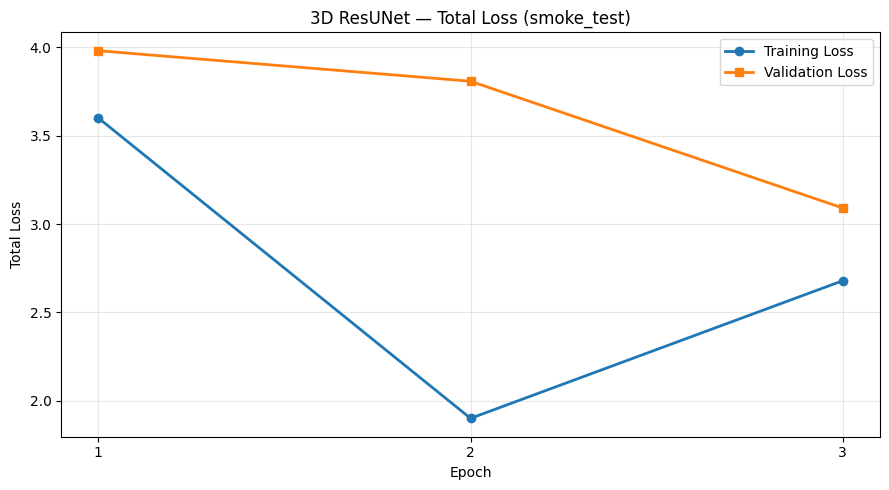

3D RESUNET — TOTAL LOSS SUMMARY
Epoch 1: Train=3.5994, Validation=3.9797
Epoch 2: Train=1.9017, Validation=3.8071
Epoch 3: Train=2.6797, Validation=3.0904

Best validation epoch: 3
Best validation loss: 3.090393543243408

Figure saved: /kaggle/working/training_results/smoke_test/total_loss.png
Cell 23: PASS


In [26]:

# ============================================================
# CELL 23 — TOTAL TRAINING AND VALIDATION LOSS
# Enhanced 3D ResUNet
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Retrieve training history
# ------------------------------------------------------------

train_losses = history_dict["loss"]
val_losses = history_dict["val_loss"]

epochs = np.arange(
    1,
    len(train_losses) + 1
)

assert len(train_losses) == len(val_losses)
assert len(epochs) > 0

# ------------------------------------------------------------
# 2. Plot training and validation loss
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="s",
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Total Loss")

plt.title(
    f"3D ResUNet — Total Loss ({TRAINING_MODE})"
)

plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# ------------------------------------------------------------
# 3. Save figure
# ------------------------------------------------------------

LOSS_FIGURE_PATH = (
    HISTORY_OUTPUT_DIR / "total_loss.png"
)

plt.savefig(
    LOSS_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("=" * 65)
print("3D RESUNET — TOTAL LOSS SUMMARY")
print("=" * 65)

for epoch, train_loss, val_loss in zip(
    epochs, train_losses, val_losses
):
    print(
        f"Epoch {epoch}: "
        f"Train={train_loss:.4f}, "
        f"Validation={val_loss:.4f}"
    )

best_epoch = int(np.argmin(val_losses)) + 1

print("\nBest validation epoch:", best_epoch)
print("Best validation loss:", min(val_losses))

assert LOSS_FIGURE_PATH.is_file()

print("\nFigure saved:", LOSS_FIGURE_PATH)
print("Cell 23: PASS")


3D RESUNET — SEGMENTATION LOSS ANALYSIS


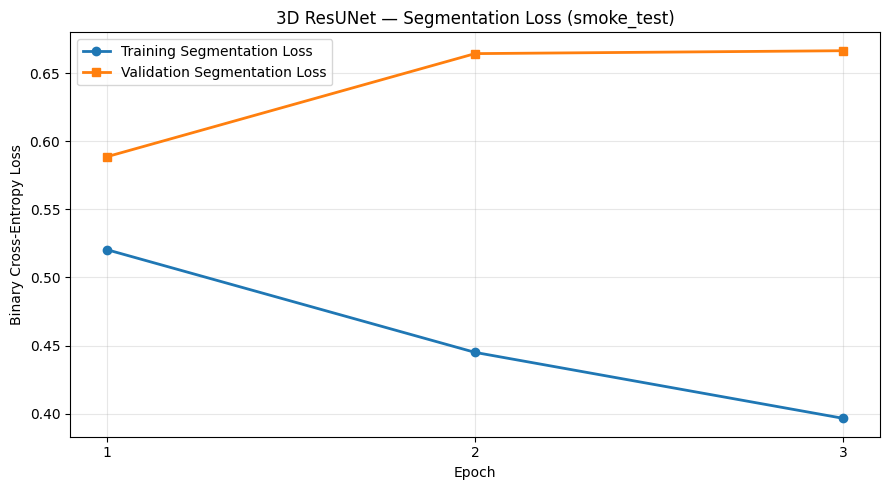

Epoch 1: Train Seg Loss=0.5204, Val Seg Loss=0.5886
Epoch 2: Train Seg Loss=0.4450, Val Seg Loss=0.6643
Epoch 3: Train Seg Loss=0.3966, Val Seg Loss=0.6665

Best segmentation validation epoch: 1
Best validation segmentation loss: 0.5886341333389282

Figure saved: /kaggle/working/training_results/smoke_test/segmentation_loss.png
Cell 24: PASS


In [27]:

# ============================================================
# CELL 24 — SEGMENTATION LOSS ANALYSIS
# Enhanced 3D Residual U-Net
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 65)
print("3D RESUNET — SEGMENTATION LOSS ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Retrieve segmentation loss history
# ------------------------------------------------------------

train_seg_loss = history_dict[
    "segmentation_output_loss"
]

val_seg_loss = history_dict[
    "val_segmentation_output_loss"
]

epochs = np.arange(
    1,
    len(train_seg_loss) + 1
)

assert len(train_seg_loss) == len(val_seg_loss)

assert np.all(np.isfinite(train_seg_loss))
assert np.all(np.isfinite(val_seg_loss))

# ------------------------------------------------------------
# 2. Plot segmentation losses
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_seg_loss,
    marker="o",
    linewidth=2,
    label="Training Segmentation Loss"
)

plt.plot(
    epochs,
    val_seg_loss,
    marker="s",
    linewidth=2,
    label="Validation Segmentation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")

plt.title(
    f"3D ResUNet — Segmentation Loss ({TRAINING_MODE})"
)

plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# ------------------------------------------------------------
# 3. Save figure
# ------------------------------------------------------------

SEG_LOSS_FIGURE_PATH = (
    HISTORY_OUTPUT_DIR / "segmentation_loss.png"
)

plt.savefig(
    SEG_LOSS_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. Display epoch-level results
# ------------------------------------------------------------

for epoch, train_loss, val_loss in zip(
    epochs,
    train_seg_loss,
    val_seg_loss
):

    print(
        f"Epoch {epoch}: "
        f"Train Seg Loss={train_loss:.4f}, "
        f"Val Seg Loss={val_loss:.4f}"
    )

# ------------------------------------------------------------
# 5. Report best segmentation-loss epoch
# ------------------------------------------------------------

best_epoch = int(np.argmin(val_seg_loss)) + 1

print("\nBest segmentation validation epoch:", best_epoch)

print(
    "Best validation segmentation loss:",
    min(val_seg_loss)
)

assert SEG_LOSS_FIGURE_PATH.is_file()

print("\nFigure saved:", SEG_LOSS_FIGURE_PATH)
print("Cell 24: PASS")


3D RESUNET — CLASSIFICATION LOSS ANALYSIS


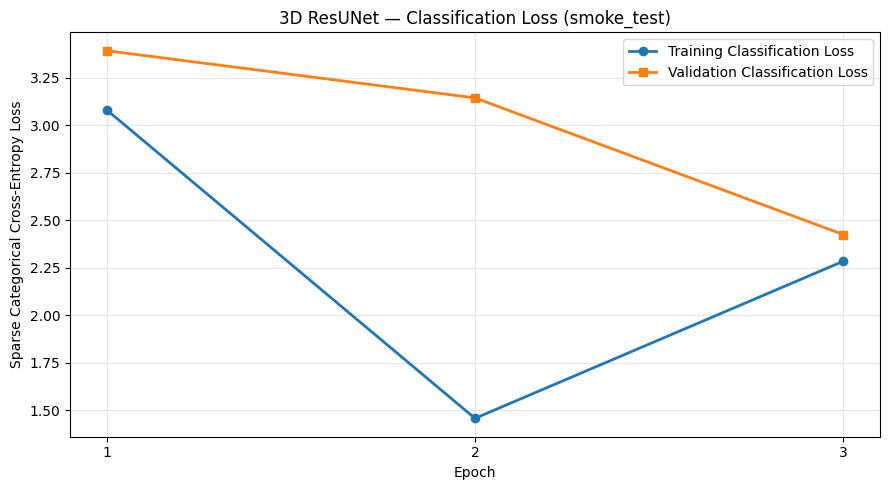

Epoch 1: Train Cls Loss=3.0790, Val Cls Loss=3.3911
Epoch 2: Train Cls Loss=1.4567, Val Cls Loss=3.1427
Epoch 3: Train Cls Loss=2.2831, Val Cls Loss=2.4239

Best classification validation epoch: 3
Best validation classification loss: 2.4239208698272705

Figure saved: /kaggle/working/training_results/smoke_test/classification_loss.png
Cell 25: PASS


In [28]:

# ============================================================
# CELL 25 — CLASSIFICATION LOSS ANALYSIS
# Enhanced 3D ResUNet
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 65)
print("3D RESUNET — CLASSIFICATION LOSS ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Retrieve classification loss history
# ------------------------------------------------------------

train_cls_loss = history_dict[
    "classification_output_loss"
]

val_cls_loss = history_dict[
    "val_classification_output_loss"
]

epochs = np.arange(
    1,
    len(train_cls_loss) + 1
)

assert len(train_cls_loss) == len(val_cls_loss)

assert np.all(np.isfinite(train_cls_loss))
assert np.all(np.isfinite(val_cls_loss))

# ------------------------------------------------------------
# 2. Plot training and validation losses
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_cls_loss,
    marker="o",
    linewidth=2,
    label="Training Classification Loss"
)

plt.plot(
    epochs,
    val_cls_loss,
    marker="s",
    linewidth=2,
    label="Validation Classification Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Sparse Categorical Cross-Entropy Loss")

plt.title(
    f"3D ResUNet — Classification Loss ({TRAINING_MODE})"
)

plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# ------------------------------------------------------------
# 3. Save classification loss figure
# ------------------------------------------------------------

CLS_LOSS_FIGURE_PATH = (
    HISTORY_OUTPUT_DIR / "classification_loss.png"
)

plt.savefig(
    CLS_LOSS_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. Display epoch-level results
# ------------------------------------------------------------

for epoch, train_loss, val_loss in zip(
    epochs,
    train_cls_loss,
    val_cls_loss
):

    print(
        f"Epoch {epoch}: "
        f"Train Cls Loss={train_loss:.4f}, "
        f"Val Cls Loss={val_loss:.4f}"
    )

# ------------------------------------------------------------
# 5. Report best validation epoch
# ------------------------------------------------------------

best_cls_epoch = int(np.argmin(val_cls_loss)) + 1

print("\nBest classification validation epoch:",
      best_cls_epoch)

print(
    "Best validation classification loss:",
    min(val_cls_loss)
)

assert CLS_LOSS_FIGURE_PATH.is_file()

print("\nFigure saved:", CLS_LOSS_FIGURE_PATH)
print("Cell 25: PASS")


3D RESUNET — SEGMENTATION DICE ANALYSIS


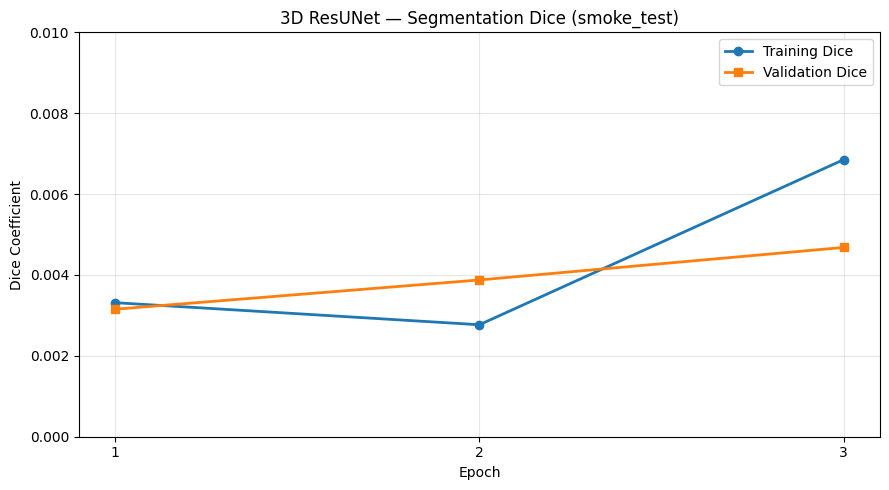

Epoch 1: Train Dice=0.003315, Val Dice=0.003153
Epoch 2: Train Dice=0.002769, Val Dice=0.003877
Epoch 3: Train Dice=0.006851, Val Dice=0.004681

Best validation Dice epoch: 3
Best validation Dice: 0.004680708982050419

Figure saved: /kaggle/working/training_results/smoke_test/segmentation_dice.png
Cell 26: PASS


In [29]:

# ============================================================
# CELL 26 — SEGMENTATION DICE ANALYSIS
# Enhanced 3D Residual U-Net
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 65)
print("3D RESUNET — SEGMENTATION DICE ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Retrieve Dice scores from training history
# ------------------------------------------------------------

train_dice = history_dict[
    "segmentation_output_dice_coefficient"
]

val_dice = history_dict[
    "val_segmentation_output_dice_coefficient"
]

epochs = np.arange(
    1,
    len(train_dice) + 1
)

assert len(train_dice) == len(val_dice)

assert np.all(np.isfinite(train_dice))
assert np.all(np.isfinite(val_dice))

# ------------------------------------------------------------
# 2. Plot training and validation Dice
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_dice,
    marker="o",
    linewidth=2,
    label="Training Dice"
)

plt.plot(
    epochs,
    val_dice,
    marker="s",
    linewidth=2,
    label="Validation Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Dice Coefficient")

plt.title(
    f"3D ResUNet — Segmentation Dice ({TRAINING_MODE})"
)

plt.xticks(epochs)
plt.ylim(0, max(0.01, max(train_dice + val_dice) * 1.15))

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# ------------------------------------------------------------
# 3. Save figure
# ------------------------------------------------------------

DICE_FIGURE_PATH = (
    HISTORY_OUTPUT_DIR / "segmentation_dice.png"
)

plt.savefig(
    DICE_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. Display epoch-level Dice values
# ------------------------------------------------------------

for epoch, train_score, val_score in zip(
    epochs,
    train_dice,
    val_dice
):

    print(
        f"Epoch {epoch}: "
        f"Train Dice={train_score:.6f}, "
        f"Val Dice={val_score:.6f}"
    )

# ------------------------------------------------------------
# 5. Identify best validation Dice
# ------------------------------------------------------------

best_dice_epoch = int(np.argmax(val_dice)) + 1

print("\nBest validation Dice epoch:",
      best_dice_epoch)

print(
    "Best validation Dice:",
    max(val_dice)
)

assert DICE_FIGURE_PATH.is_file()

print("\nFigure saved:", DICE_FIGURE_PATH)
print("Cell 26: PASS")


3D RESUNET — SEGMENTATION IoU ANALYSIS


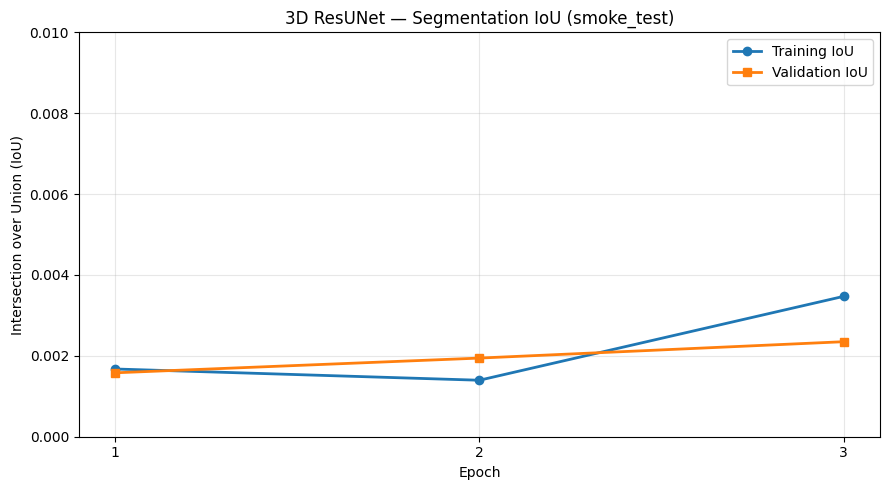

Epoch 1: Train IoU=0.001675, Val IoU=0.001581
Epoch 2: Train IoU=0.001397, Val IoU=0.001945
Epoch 3: Train IoU=0.003471, Val IoU=0.002350

Best validation IoU epoch: 3
Best validation IoU: 0.002349657705053687

Figure saved: /kaggle/working/training_results/smoke_test/segmentation_iou.png
Cell 27: PASS


In [30]:

# ============================================================
# CELL 27 — SEGMENTATION IoU ANALYSIS
# Enhanced 3D Residual U-Net
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 65)
print("3D RESUNET — SEGMENTATION IoU ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Retrieve IoU history
# ------------------------------------------------------------

train_iou = history_dict[
    "segmentation_output_iou_coefficient"
]

val_iou = history_dict[
    "val_segmentation_output_iou_coefficient"
]

epochs = np.arange(
    1,
    len(train_iou) + 1
)

assert len(train_iou) == len(val_iou)

assert np.all(np.isfinite(train_iou))
assert np.all(np.isfinite(val_iou))

# ------------------------------------------------------------
# 2. Plot IoU curves
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_iou,
    marker="o",
    linewidth=2,
    label="Training IoU"
)

plt.plot(
    epochs,
    val_iou,
    marker="s",
    linewidth=2,
    label="Validation IoU"
)

plt.xlabel("Epoch")
plt.ylabel("Intersection over Union (IoU)")

plt.title(
    f"3D ResUNet — Segmentation IoU ({TRAINING_MODE})"
)

plt.xticks(epochs)

plt.ylim(
    0,
    max(
        0.01,
        max(train_iou + val_iou) * 1.15
    )
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# ------------------------------------------------------------
# 3. Save figure
# ------------------------------------------------------------

IOU_FIGURE_PATH = (
    HISTORY_OUTPUT_DIR / "segmentation_iou.png"
)

plt.savefig(
    IOU_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. Display epoch-level IoU
# ------------------------------------------------------------

for epoch, train_score, val_score in zip(
    epochs,
    train_iou,
    val_iou
):
    print(
        f"Epoch {epoch}: "
        f"Train IoU={train_score:.6f}, "
        f"Val IoU={val_score:.6f}"
    )

# ------------------------------------------------------------
# 5. Identify best validation IoU
# ------------------------------------------------------------

best_iou_epoch = int(np.argmax(val_iou)) + 1

print(
    "\nBest validation IoU epoch:",
    best_iou_epoch
)

print(
    "Best validation IoU:",
    max(val_iou)
)

assert IOU_FIGURE_PATH.is_file()

print("\nFigure saved:", IOU_FIGURE_PATH)
print("Cell 27: PASS")


3D RESUNET — CLASSIFICATION ACCURACY ANALYSIS


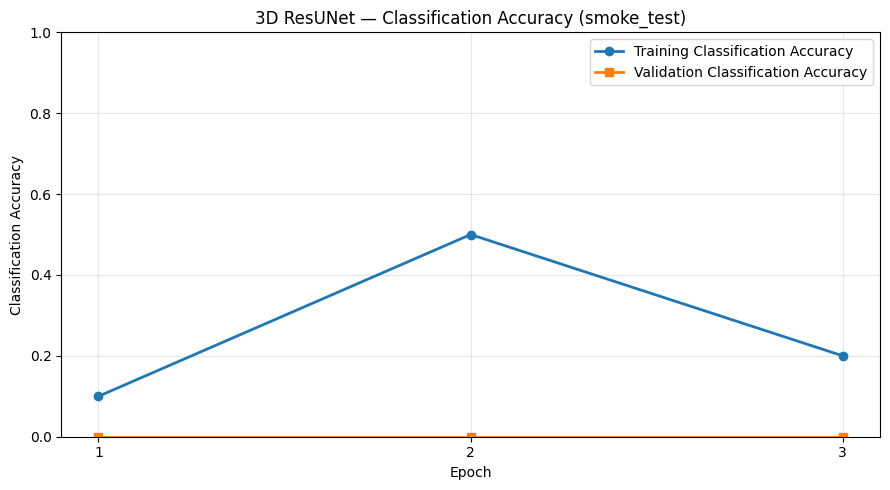

Epoch 1: Train Accuracy=0.1000, Val Accuracy=0.0000
Epoch 2: Train Accuracy=0.5000, Val Accuracy=0.0000
Epoch 3: Train Accuracy=0.2000, Val Accuracy=0.0000

Best classification validation accuracy epoch: 1
Best validation classification accuracy: 0.0

Figure saved: /kaggle/working/training_results/smoke_test/classification_accuracy.png
Cell 28: PASS


In [31]:

# ============================================================
# CELL 28 — CLASSIFICATION ACCURACY ANALYSIS
# Enhanced 3D Residual U-Net
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 65)
print("3D RESUNET — CLASSIFICATION ACCURACY ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. Retrieve classification accuracy history
# ------------------------------------------------------------

train_cls_accuracy = history_dict[
    "classification_output_cls_accuracy"
]

val_cls_accuracy = history_dict[
    "val_classification_output_cls_accuracy"
]

epochs = np.arange(
    1,
    len(train_cls_accuracy) + 1
)

assert len(train_cls_accuracy) == len(val_cls_accuracy)

assert np.all(np.isfinite(train_cls_accuracy))
assert np.all(np.isfinite(val_cls_accuracy))

# ------------------------------------------------------------
# 2. Plot classification accuracy
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_cls_accuracy,
    marker="o",
    linewidth=2,
    label="Training Classification Accuracy"
)

plt.plot(
    epochs,
    val_cls_accuracy,
    marker="s",
    linewidth=2,
    label="Validation Classification Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Classification Accuracy")

plt.title(
    f"3D ResUNet — Classification Accuracy ({TRAINING_MODE})"
)

plt.xticks(epochs)
plt.ylim(0, 1.0)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

# ------------------------------------------------------------
# 3. Save figure
# ------------------------------------------------------------

CLS_ACCURACY_FIGURE_PATH = (
    HISTORY_OUTPUT_DIR / "classification_accuracy.png"
)

plt.savefig(
    CLS_ACCURACY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. Display epoch-level accuracy
# ------------------------------------------------------------

for epoch, train_acc, val_acc in zip(
    epochs,
    train_cls_accuracy,
    val_cls_accuracy
):

    print(
        f"Epoch {epoch}: "
        f"Train Accuracy={train_acc:.4f}, "
        f"Val Accuracy={val_acc:.4f}"
    )

# ------------------------------------------------------------
# 5. Identify best validation accuracy
# ------------------------------------------------------------

best_cls_accuracy_epoch = (
    int(np.argmax(val_cls_accuracy)) + 1
)

print(
    "\nBest classification validation accuracy epoch:",
    best_cls_accuracy_epoch
)

print(
    "Best validation classification accuracy:",
    max(val_cls_accuracy)
)

assert CLS_ACCURACY_FIGURE_PATH.is_file()

print("\nFigure saved:", CLS_ACCURACY_FIGURE_PATH)
print("Cell 28: PASS")


## 9. Evaluate and save the best model


In [32]:
# ============================================================
# CELL 29 — LOAD BEST TRAINED 3D RESUNET
# Supports smoke-test and full-pilot checkpoints
# ============================================================

from pathlib import Path
from tensorflow import keras

print("=" * 65)
print("3D RESUNET — LOAD BEST TRAINED MODEL")
print("=" * 65)

# ------------------------------------------------------------
# 1. Select checkpoint from current training experiment
# ------------------------------------------------------------

BEST_CHECKPOINT_PATH = Path(
    ACTIVE_BEST_MODEL_PATH
)

assert BEST_CHECKPOINT_PATH.is_file(), (
    f"Best checkpoint not found: {BEST_CHECKPOINT_PATH}"
)

assert BEST_CHECKPOINT_PATH.stat().st_size > 0

# ------------------------------------------------------------
# 2. Load saved model
# ------------------------------------------------------------

best_model = keras.models.load_model(
    str(BEST_CHECKPOINT_PATH),
    custom_objects={
        "dice_coefficient": dice_coefficient,
        "iou_coefficient": iou_coefficient,
    },
    compile=False
)

# ------------------------------------------------------------
# 3. Verify architecture and outputs
# ------------------------------------------------------------

assert best_model.input_shape == (
    None, 64, 64, 64, 1
)

assert best_model.count_params() == model.count_params()

output_shapes = {
    name: tuple(shape)
    for name, shape in zip(
        best_model.output_names,
        best_model.output_shape
    )
}

assert output_shapes["segmentation_output"] == (
    None, 64, 64, 64, 1
)

assert output_shapes["classification_output"] == (
    None, NUM_CLASSES
)

# ------------------------------------------------------------
# 4. Display model information
# ------------------------------------------------------------

print("Training mode:", TRAINING_MODE)
print("Model loaded:", best_model.name)

print("\nCheckpoint path:")
print(BEST_CHECKPOINT_PATH)

print("\nInput shape:", best_model.input_shape)
print("Output shapes:", output_shapes)

print("\nTotal parameters:", best_model.count_params())

print(
    "Checkpoint size:",
    f"{BEST_CHECKPOINT_PATH.stat().st_size / (1024**2):.2f} MiB"
)

print("\nBest model loading: PASS")
print("Cell 29: PASS")


3D RESUNET — LOAD BEST TRAINED MODEL
Training mode: smoke_test
Model loaded: Enhanced_3D_ResUNet_MultiTask

Checkpoint path:
/kaggle/working/training_results/smoke_test/best_smoke_model.keras

Input shape: (None, 64, 64, 64, 1)
Output shapes: {'classification_output': (None, 5), 'segmentation_output': (None, 64, 64, 64, 1)}

Total parameters: 7258326
Checkpoint size: 83.43 MiB

Best model loading: PASS
Cell 29: PASS


In [33]:

# ============================================================
# CELL 30 — COMPILE BEST MODEL
# ============================================================

best_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss={
        "segmentation_output":
            keras.losses.BinaryCrossentropy(),

        "classification_output":
            keras.losses.SparseCategoricalCrossentropy(),
    },

    loss_weights={
        "segmentation_output":
            SEGMENTATION_LOSS_WEIGHT,

        "classification_output":
            CLASSIFICATION_LOSS_WEIGHT,
    },

    metrics={
        "segmentation_output": [
            keras.metrics.BinaryAccuracy(
                name="seg_accuracy"
            ),
            dice_coefficient,
            iou_coefficient,
        ],

        "classification_output": [
            keras.metrics.SparseCategoricalAccuracy(
                name="cls_accuracy"
            ),
        ],
    },
)

print("Best model compiled.")
print("Cell 30: PASS")


Best model compiled.
Cell 30: PASS


In [34]:

# ============================================================
# CELL 31 — COMPLETE PILOT VALIDATION EVALUATION
# Enhanced 3D Residual U-Net
# ============================================================

import numpy as np

print("=" * 70)
print("3D RESUNET — COMPLETE VALIDATION EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify validation dataset
# ------------------------------------------------------------

assert len(val_patch_index) == 100
assert len(val_dataset) == 100

assert len(val_patient_dirs) == 1

assert val_patient_dirs[0].name == "RibFrac10"

assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

print("Training mode:", TRAINING_MODE)
print("Model:", best_model.name)

print("\nValidation patient:", val_patient_dirs[0].name)
print("Validation patches:", len(val_patch_index))
print("Validation batches:", len(val_dataset))
print("Batch size:", BATCH_SIZE)

# ------------------------------------------------------------
# 2. Evaluate all available validation patches
# ------------------------------------------------------------

evaluation_results = best_model.evaluate(
    val_dataset,
    return_dict=True,
    verbose=1
)

# ------------------------------------------------------------
# 3. Verify evaluation results
# ------------------------------------------------------------

assert isinstance(evaluation_results, dict)
assert "loss" in evaluation_results

for metric_name, metric_value in evaluation_results.items():

    assert np.isfinite(metric_value), (
        f"Non-finite evaluation metric: {metric_name}"
    )

# ------------------------------------------------------------
# 4. Display evaluation metrics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPLETE PILOT VALIDATION RESULTS")
print("=" * 70)

for metric_name, metric_value in evaluation_results.items():

    print(
        f"{metric_name}: {float(metric_value):.6f}"
    )

# ------------------------------------------------------------
# 5. Highlight important evaluation metrics
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("KEY PERFORMANCE METRICS")
print("-" * 70)

metric_labels = {
    "loss": "Total validation loss",

    "segmentation_output_loss":
        "Segmentation loss",

    "classification_output_loss":
        "Classification loss",

    "segmentation_output_dice_coefficient":
        "Segmentation Dice",

    "segmentation_output_iou_coefficient":
        "Segmentation IoU",

    "segmentation_output_seg_accuracy":
        "Segmentation binary accuracy",

    "classification_output_cls_accuracy":
        "Classification accuracy",
}

for metric_key, display_name in metric_labels.items():

    if metric_key in evaluation_results:

        print(
            f"{display_name}: "
            f"{float(evaluation_results[metric_key]):.6f}"
        )

# ------------------------------------------------------------
# 6. Confirm completion
# ------------------------------------------------------------

print("\nValidation patients evaluated: 1")
print("Validation patches evaluated:", len(val_patch_index))

print("\nFull available pilot validation: PASS")
print("Cell 31: PASS")


3D RESUNET — COMPLETE VALIDATION EVALUATION
Training mode: smoke_test
Model: Enhanced_3D_ResUNet_MultiTask

Validation patient: RibFrac10
Validation patches: 100
Validation batches: 100
Batch size: 1
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - classification_output_cls_accuracy: 0.3100 - classification_output_loss: 1.5893 - loss: 2.2465 - segmentation_output_dice_coefficient: 0.0111 - segmentation_output_iou_coefficient: 0.0057 - segmentation_output_loss: 0.6572 - segmentation_output_seg_accuracy: 0.7023

COMPLETE PILOT VALIDATION RESULTS
classification_output_cls_accuracy: 0.310000
classification_output_loss: 1.589311
loss: 2.246464
segmentation_output_dice_coefficient: 0.011135
segmentation_output_iou_coefficient: 0.005700
segmentation_output_loss: 0.657155
segmentation_output_seg_accuracy: 0.702333

----------------------------------------------------------------------
KEY PERFORMANCE METRICS
----------------------------------------------------------------------
Total validation los

In [35]:

# ============================================================
# CELL 32 — SAVE COMPLETE VALIDATION METRICS
# Enhanced 3D ResUNet
# ============================================================

import json
import numpy as np

print("=" * 70)
print("3D RESUNET — SAVE VALIDATION METRICS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Select output directory
# ------------------------------------------------------------

if TRAINING_MODE == "smoke_test":
    ACTIVE_METRICS_PATH = (
        SMOKE_ROOT / "validation_metrics.json"
    )
    ACTIVE_EVALUATION_CONTEXT_PATH = (
        SMOKE_ROOT / "validation_context.json"
    )
else:
    ACTIVE_METRICS_PATH = METRICS_PATH
    ACTIVE_EVALUATION_CONTEXT_PATH = (
        OUTPUT_ROOT / "validation_context.json"
    )

ACTIVE_METRICS_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Convert evaluation metrics to standard floats
# ------------------------------------------------------------

validation_metrics = {
    key: float(value)
    for key, value in evaluation_results.items()
}

assert len(validation_metrics) > 0

for metric_name, metric_value in validation_metrics.items():
    assert np.isfinite(metric_value), (
        f"Invalid metric: {metric_name}"
    )

# ------------------------------------------------------------
# 3. Save validation metrics
# ------------------------------------------------------------

with open(
    ACTIVE_METRICS_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(validation_metrics, f, indent=2)

# ------------------------------------------------------------
# 4. Save evaluation context separately
# ------------------------------------------------------------

validation_context = {
    "model": best_model.name,
    "training_mode": TRAINING_MODE,
    "evaluation_type": "pilot_validation",
    "smoke_test_only": TRAINING_MODE == "smoke_test",
    "validation_patient_ids": sorted(
        val_patch_index["patient_id"].unique().tolist()
    ),
    "validation_patient_count": int(
        val_patch_index["patient_id"].nunique()
    ),
    "validation_patch_count": int(
        len(val_patch_index)
    ),
    "validation_batch_count": int(
        len(val_dataset)
    ),
    "batch_size": int(BATCH_SIZE),
    "best_checkpoint": str(BEST_CHECKPOINT_PATH),
    "original_internal_test_used": False,
    "final_500_patient_experiment": False,
}

with open(
    ACTIVE_EVALUATION_CONTEXT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(validation_context, f, indent=2)

# ------------------------------------------------------------
# 5. Verify saved metrics
# ------------------------------------------------------------

with open(
    ACTIVE_METRICS_PATH,
    "r",
    encoding="utf-8"
) as f:
    loaded_metrics = json.load(f)

assert loaded_metrics == validation_metrics

assert ACTIVE_METRICS_PATH.is_file()
assert ACTIVE_EVALUATION_CONTEXT_PATH.is_file()

# ------------------------------------------------------------
# 6. Display saved results
# ------------------------------------------------------------

print("Training mode:", TRAINING_MODE)
print("Validation patients:",
      validation_context["validation_patient_count"])
print("Validation patches:",
      validation_context["validation_patch_count"])

print("\nSaved validation metrics:")

for metric_name, metric_value in loaded_metrics.items():
    print(f"{metric_name}: {metric_value:.6f}")

print("\nMetrics saved:")
print(ACTIVE_METRICS_PATH)

print("\nEvaluation context saved:")
print(ACTIVE_EVALUATION_CONTEXT_PATH)

print("\nValidation metrics saved: PASS")
print("Cell 32: PASS")


3D RESUNET — SAVE VALIDATION METRICS
Training mode: smoke_test
Validation patients: 1
Validation patches: 100

Saved validation metrics:
classification_output_cls_accuracy: 0.310000
classification_output_loss: 1.589311
loss: 2.246464
segmentation_output_dice_coefficient: 0.011135
segmentation_output_iou_coefficient: 0.005700
segmentation_output_loss: 0.657155
segmentation_output_seg_accuracy: 0.702333

Metrics saved:
/kaggle/working/training_results/smoke_test/validation_metrics.json

Evaluation context saved:
/kaggle/working/training_results/smoke_test/validation_context.json

Validation metrics saved: PASS
Cell 32: PASS


In [36]:

# ============================================================
# CELL 33 — SAVE TRAINED 3D RESUNET MODEL
# Enhanced 3D Residual U-Net
# ============================================================

from pathlib import Path
from tensorflow import keras

print("=" * 70)
print("3D RESUNET — SAVE TRAINED MODEL")
print("=" * 70)

# ------------------------------------------------------------
# 1. Select output path based on training mode
# ------------------------------------------------------------

if TRAINING_MODE == "smoke_test":

    ACTIVE_FINAL_MODEL_PATH = (
        SMOKE_ROOT / "final_smoke_model.keras"
    )

else:

    ACTIVE_FINAL_MODEL_PATH = FINAL_MODEL_PATH

ACTIVE_FINAL_MODEL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Save best trained model
# ------------------------------------------------------------

best_model.save(
    str(ACTIVE_FINAL_MODEL_PATH)
)

# ------------------------------------------------------------
# 3. Verify saved model file
# ------------------------------------------------------------

assert ACTIVE_FINAL_MODEL_PATH.is_file(), (
    "Saved model file does not exist."
)

assert ACTIVE_FINAL_MODEL_PATH.stat().st_size > 0

# ------------------------------------------------------------
# 4. Reload saved model to verify integrity
# ------------------------------------------------------------

verified_model = keras.models.load_model(
    str(ACTIVE_FINAL_MODEL_PATH),
    compile=False
)

assert verified_model.input_shape == (
    None, 64, 64, 64, 1
)

assert (
    verified_model.count_params()
    == best_model.count_params()
)

assert set(verified_model.output_names) == {
    "segmentation_output",
    "classification_output",
}

# ------------------------------------------------------------
# 5. Display model information
# ------------------------------------------------------------

print("\nTraining mode:", TRAINING_MODE)

print("Model:", verified_model.name)

print(
    "Total parameters:",
    verified_model.count_params()
)

print("\nSaved model path:")
print(ACTIVE_FINAL_MODEL_PATH)

print(
    "\nModel file size:",
    f"{ACTIVE_FINAL_MODEL_PATH.stat().st_size / (1024**2):.2f} MiB"
)

print("\nSaved model verification: PASS")
print("Cell 33: PASS")


3D RESUNET — SAVE TRAINED MODEL

Training mode: smoke_test
Model: Enhanced_3D_ResUNet_MultiTask
Total parameters: 7258326

Saved model path:
/kaggle/working/training_results/smoke_test/final_smoke_model.keras

Model file size: 28.02 MiB

Saved model verification: PASS
Cell 33: PASS


In [37]:

# ============================================================
# CELL 34 — SAVE EXPERIMENT CONFIGURATION
# Enhanced 3D Residual U-Net
# ============================================================

import json
import numpy as np
from pathlib import Path

print("=" * 70)
print("3D RESUNET — SAVE EXPERIMENT CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Select experiment configuration path
# ------------------------------------------------------------

if TRAINING_MODE == "smoke_test":
    ACTIVE_CONFIG_OUTPUT_PATH = (
        SMOKE_ROOT / "smoke_experiment_config.json"
    )
else:
    ACTIVE_CONFIG_OUTPUT_PATH = CONFIG_OUTPUT_PATH

ACTIVE_CONFIG_OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Verify patient-level separation
# ------------------------------------------------------------

training_patient_ids = sorted(
    train_patch_index["patient_id"].unique().tolist()
)

validation_patient_ids = sorted(
    val_patch_index["patient_id"].unique().tolist()
)

assert set(training_patient_ids).isdisjoint(
    set(validation_patient_ids)
)

training_source_splits = sorted(
    train_patch_index["source_split"].unique().tolist()
)

validation_source_splits = sorted(
    val_patch_index["source_split"].unique().tolist()
)

assert "test" not in training_source_splits
assert "test" not in validation_source_splits

# ------------------------------------------------------------
# 3. Record class distributions
# ------------------------------------------------------------

training_class_distribution = {
    str(i): int(
        (train_patch_index["classification"] == i).sum()
    )
    for i in range(NUM_CLASSES)
}

validation_class_distribution = {
    str(i): int(
        (val_patch_index["classification"] == i).sum()
    )
    for i in range(NUM_CLASSES)
}

# ------------------------------------------------------------
# 4. Create experiment configuration
# ------------------------------------------------------------

experiment_config = {

    "experiment_name":
        "Enhanced_3D_ResUNet_MultiTask",

    "training_mode": TRAINING_MODE,

    "smoke_test_only":
        TRAINING_MODE == "smoke_test",

    "pilot_mode": bool(PILOT_MODE),

    "final_500_patient_experiment": False,

    "model_architecture": {
        "input_shape": list(INPUT_SHAPE),
        "patch_size": list(PATCH_SIZE),
        "num_classes": int(NUM_CLASSES),
        "class_names": CLASS_NAMES,
        "base_filters": int(BASE_FILTERS),
        "encoder_depth": int(DEPTH),
        "dropout_rate": float(DROPOUT_RATE),
        "total_parameters": int(
            best_model.count_params()
        ),
    },

    "training_configuration": {
        "batch_size": int(BATCH_SIZE),
        "epochs_requested": int(TRAIN_EPOCHS),
        "epochs_completed": int(
            len(history_dict["loss"])
        ),
        "training_steps_per_epoch": int(TRAIN_STEPS),
        "validation_steps_per_epoch": int(VAL_STEPS),
        "learning_rate": float(LEARNING_RATE),
        "optimizer": "Adam",
        "segmentation_loss": "BinaryCrossentropy",
        "classification_loss":
            "SparseCategoricalCrossentropy",
        "segmentation_loss_weight": float(
            SEGMENTATION_LOSS_WEIGHT
        ),
        "classification_loss_weight": float(
            CLASSIFICATION_LOSS_WEIGHT
        ),
        "random_seed": int(SEED),
    },

    "dataset_configuration": {
        "patient_level_split": True,
        "authoritative_final_split_used":
            bool(USE_FINAL_SPLITS),
        "training_patient_ids": training_patient_ids,
        "validation_patient_ids":
            validation_patient_ids,
        "training_patient_count": len(
            training_patient_ids
        ),
        "validation_patient_count": len(
            validation_patient_ids
        ),
        "training_patches": int(
            len(train_patch_index)
        ),
        "validation_patches": int(
            len(val_patch_index)
        ),
        "training_source_splits":
            training_source_splits,
        "validation_source_splits":
            validation_source_splits,
        "test_data_used": False,
        "training_class_distribution":
            training_class_distribution,
        "validation_class_distribution":
            validation_class_distribution,
    },

    "validation_configuration": {
        "selection_metric": "val_loss",
        "best_epoch": int(
            np.argmin(history_dict["val_loss"]) + 1
        ),
        "best_epoch_validation_loss": float(
            min(history_dict["val_loss"])
        ),
        "evaluation_patches": int(
            len(val_patch_index)
        ),
        "evaluation_batches": int(
            len(val_dataset)
        ),
        "segmentation_threshold": 0.5,
        "independent_validation_patients": int(
            len(validation_patient_ids)
        ),
    },

    "output_artifacts": {
        "best_model": str(
            ACTIVE_BEST_MODEL_PATH
        ),
        "saved_model": str(
            ACTIVE_FINAL_MODEL_PATH
        ),
        "history_csv": str(
            ACTIVE_HISTORY_CSV_PATH
        ),
        "history_npy": str(
            ACTIVE_HISTORY_NPY_PATH
        ),
        "validation_metrics": str(
            ACTIVE_METRICS_PATH
        ),
    },
}

# ------------------------------------------------------------
# 5. Save configuration
# ------------------------------------------------------------

with open(
    ACTIVE_CONFIG_OUTPUT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        experiment_config,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 6. Reload and verify configuration
# ------------------------------------------------------------

with open(
    ACTIVE_CONFIG_OUTPUT_PATH,
    "r",
    encoding="utf-8"
) as f:
    verified_config = json.load(f)

assert (
    verified_config["training_mode"]
    == TRAINING_MODE
)

assert (
    verified_config["training_configuration"]
    ["epochs_completed"]
    == len(history_dict["loss"])
)

assert (
    verified_config["dataset_configuration"]
    ["training_patches"]
    == len(train_patch_index)
)

assert (
    verified_config["dataset_configuration"]
    ["validation_patches"]
    == len(val_patch_index)
)

assert ACTIVE_CONFIG_OUTPUT_PATH.is_file()

# ------------------------------------------------------------
# 7. Display experiment summary
# ------------------------------------------------------------

print("Training mode:", TRAINING_MODE)

print(
    "Epochs requested:",
    verified_config["training_configuration"]
    ["epochs_requested"]
)

print(
    "Epochs completed:",
    verified_config["training_configuration"]
    ["epochs_completed"]
)

print("Training patients:", len(training_patient_ids))
print("Validation patients:", len(validation_patient_ids))

print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("Training steps per epoch:", TRAIN_STEPS)
print("Validation steps per epoch:", VAL_STEPS)

print("\nTest data used: False")

print("\nExperiment configuration saved:")
print(ACTIVE_CONFIG_OUTPUT_PATH)

print("\nExperiment configuration verified: PASS")
print("Cell 34: PASS")


3D RESUNET — SAVE EXPERIMENT CONFIGURATION
Training mode: smoke_test
Epochs requested: 3
Epochs completed: 3
Training patients: 4
Validation patients: 1
Training patches: 202
Validation patches: 100
Training steps per epoch: 10
Validation steps per epoch: 5

Test data used: False

Experiment configuration saved:
/kaggle/working/training_results/smoke_test/smoke_experiment_config.json

Experiment configuration verified: PASS
Cell 34: PASS


In [39]:

# ============================================================
# CELL 35 — CREATE KAGGLE DATASET METADATA
# Enhanced 3D ResUNet Training Artifacts
# ============================================================

import json
from pathlib import Path

print("=" * 70)
print("3D RESUNET — CREATE KAGGLE DATASET METADATA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Select dataset based on training mode
# ------------------------------------------------------------

if TRAINING_MODE == "smoke_test":

    KAGGLE_PUBLISH_ROOT = SMOKE_ROOT

    KAGGLE_DATASET_ID = (
        "waboke/ribfrac-resunet-smoke-test"
    )

    KAGGLE_DATASET_TITLE = (
        "RibFrac 3D ResUNet Smoke-Test Artifacts"
    )

    dataset_description = (
        "Technical smoke-test artifacts for an enhanced "
        "3D ResUNet multi-task framework for rib fracture "
        "segmentation and five-class classification using "
        "chest CT patches. "
        "The experiment used four training patients, "
        "one pilot validation patient, three epochs, "
        "10 training batches and five validation batches "
        "per epoch. The saved checkpoint was subsequently "
        "evaluated on all 100 available validation patches. "
        "These results are preliminary and do not represent "
        "the final 500-patient study or clinical validation."
    )

else:

    KAGGLE_PUBLISH_ROOT = OUTPUT_ROOT

    KAGGLE_DATASET_ID = (
        "waboke/ribfrac-resunet-training-results"
    )

    KAGGLE_DATASET_TITLE = (
        "RibFrac Enhanced 3D ResUNet Training Results"
    )

    dataset_description = (
        "Training artifacts for an enhanced 3D ResUNet "
        "multi-task framework for rib fracture segmentation "
        "and five-class classification using chest CT. "
        "Includes model checkpoints, training history, "
        "validation results and experiment configuration."
    )

KAGGLE_PUBLISH_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Define metadata file location
# ------------------------------------------------------------

KAGGLE_METADATA_PATH = (
    KAGGLE_PUBLISH_ROOT / "dataset-metadata.json"
)

# ------------------------------------------------------------
# 3. Create Kaggle dataset metadata
# ------------------------------------------------------------

training_dataset_metadata = {
    "title": KAGGLE_DATASET_TITLE,
    "id": KAGGLE_DATASET_ID,
    "licenses": [
        {"name": "CC-BY-4.0"}
    ],
    "description": dataset_description,
}

# ------------------------------------------------------------
# 4. Save dataset metadata
# ------------------------------------------------------------

with open(
    KAGGLE_METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_dataset_metadata,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 5. Reload and verify metadata
# ------------------------------------------------------------

with open(
    KAGGLE_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:

    verified_metadata = json.load(f)

assert (
    verified_metadata["id"]
    == KAGGLE_DATASET_ID
)

assert verified_metadata["title"]

assert KAGGLE_METADATA_PATH.is_file()

assert KAGGLE_METADATA_PATH.stat().st_size > 0

# ------------------------------------------------------------
# 6. Display metadata summary
# ------------------------------------------------------------

print("Training mode:", TRAINING_MODE)

print("\nDataset title:")
print(verified_metadata["title"])

print("\nDataset identifier:")
print(verified_metadata["id"])

print("\nDataset directory:")
print(KAGGLE_PUBLISH_ROOT)

print("\nMetadata file:")
print(KAGGLE_METADATA_PATH)

print("\nDataset metadata verified: PASS")
print("Cell 35: PASS")


3D RESUNET — CREATE KAGGLE DATASET METADATA
Training mode: smoke_test

Dataset title:
RibFrac 3D ResUNet Smoke-Test Artifacts

Dataset identifier:
waboke/ribfrac-resunet-smoke-test

Dataset directory:
/kaggle/working/training_results/smoke_test

Metadata file:
/kaggle/working/training_results/smoke_test/dataset-metadata.json

Dataset metadata verified: PASS
Cell 35: PASS


In [40]:

# ============================================================
# CELL 36 — VERIFY ALL TRAINING ARTIFACTS
# Enhanced 3D ResUNet
# ============================================================

import json
from pathlib import Path

print("=" * 70)
print("3D RESUNET — VERIFY ALL TRAINING ARTIFACTS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Define required model and experiment files
# ------------------------------------------------------------

required_artifacts = {
    "Best model checkpoint":
        ACTIVE_BEST_MODEL_PATH,

    "Final saved model":
        ACTIVE_FINAL_MODEL_PATH,

    "Training history CSV":
        ACTIVE_HISTORY_CSV_PATH,

    "Training history NPY":
        ACTIVE_HISTORY_NPY_PATH,

    "Training summary JSON":
        ACTIVE_HISTORY_JSON_PATH,

    "Validation metrics JSON":
        ACTIVE_METRICS_PATH,

    "Validation context JSON":
        ACTIVE_EVALUATION_CONTEXT_PATH,

    "Experiment configuration":
        ACTIVE_CONFIG_OUTPUT_PATH,

    "Kaggle dataset metadata":
        KAGGLE_METADATA_PATH,
}

# ------------------------------------------------------------
# 2. Add generated training figures
# ------------------------------------------------------------

required_figures = {
    "Total loss":
        HISTORY_OUTPUT_DIR / "total_loss.png",

    "Segmentation loss":
        HISTORY_OUTPUT_DIR / "segmentation_loss.png",

    "Classification loss":
        HISTORY_OUTPUT_DIR / "classification_loss.png",

    "Segmentation Dice":
        HISTORY_OUTPUT_DIR / "segmentation_dice.png",

    "Segmentation IoU":
        HISTORY_OUTPUT_DIR / "segmentation_iou.png",

    "Classification accuracy":
        HISTORY_OUTPUT_DIR / "classification_accuracy.png",
}

required_artifacts.update(required_figures)

# ------------------------------------------------------------
# 3. Verify existence and nonempty files
# ------------------------------------------------------------

missing_artifacts = []

for artifact_name, artifact_path in required_artifacts.items():

    artifact_path = Path(artifact_path)

    if (
        artifact_path.is_file()
        and artifact_path.stat().st_size > 0
    ):
        print(f"PASS | {artifact_name}")
    else:
        print(f"FAIL | {artifact_name}")
        missing_artifacts.append(str(artifact_path))

assert not missing_artifacts, (
    "Missing artifacts:\n"
    + "\n".join(missing_artifacts)
)

# ------------------------------------------------------------
# 4. Verify files belong to publication directory
# ------------------------------------------------------------

publish_root = Path(
    KAGGLE_PUBLISH_ROOT
).resolve()

for artifact_path in required_artifacts.values():

    resolved_path = Path(artifact_path).resolve()

    assert resolved_path.is_relative_to(publish_root), (
        f"Artifact outside publication directory: "
        f"{resolved_path}"
    )

# ------------------------------------------------------------
# 5. Verify experiment identity
# ------------------------------------------------------------

with open(
    ACTIVE_CONFIG_OUTPUT_PATH,
    "r",
    encoding="utf-8"
) as f:
    saved_config = json.load(f)

with open(
    KAGGLE_METADATA_PATH,
    "r",
    encoding="utf-8"
) as f:
    saved_metadata = json.load(f)

assert saved_config["training_mode"] == TRAINING_MODE

assert saved_config[
    "training_configuration"
]["epochs_completed"] == 3

assert saved_config[
    "dataset_configuration"
]["validation_patches"] == 100

if TRAINING_MODE == "smoke_test":

    assert saved_metadata["id"] == (
        "waboke/ribfrac-resunet-smoke-test"
    )

    assert saved_config["smoke_test_only"] is True

# ------------------------------------------------------------
# 6. Display final artifact summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ARTIFACT VERIFICATION SUMMARY")
print("=" * 70)

print("Training mode:", TRAINING_MODE)
print("Required artifacts:", len(required_artifacts))
print("Verified artifacts:", len(required_artifacts))
print("Missing artifacts:", len(missing_artifacts))

print("\nKaggle publication directory:")
print(KAGGLE_PUBLISH_ROOT)

print("\nKaggle dataset identifier:")
print(saved_metadata["id"])

print("\nAll training artifacts verified: PASS")
print("Cell 36: PASS")


3D RESUNET — VERIFY ALL TRAINING ARTIFACTS
PASS | Best model checkpoint
PASS | Final saved model
PASS | Training history CSV
PASS | Training history NPY
PASS | Training summary JSON
PASS | Validation metrics JSON
PASS | Validation context JSON
PASS | Experiment configuration
PASS | Kaggle dataset metadata
PASS | Total loss
PASS | Segmentation loss
PASS | Classification loss
PASS | Segmentation Dice
PASS | Segmentation IoU
PASS | Classification accuracy

ARTIFACT VERIFICATION SUMMARY
Training mode: smoke_test
Required artifacts: 15
Verified artifacts: 15
Missing artifacts: 0

Kaggle publication directory:
/kaggle/working/training_results/smoke_test

Kaggle dataset identifier:
waboke/ribfrac-resunet-smoke-test

All training artifacts verified: PASS
Cell 36: PASS


## 10. Prepare persistent Kaggle Dataset for Notebook 06

Notebook 06 will consume this complete `training_results` directory. Do not delete or rename the files after training.


In [41]:

# ============================================================
# CELL 37 — FINAL TRAINING SUMMARY
# Enhanced 3D ResUNet Multi-Task Framework
# ============================================================

import json
from pathlib import Path

print("=" * 70)
print("NOTEBOOK 05 — ENHANCED 3D RESUNET TRAINING SUMMARY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify completed experiment
# ------------------------------------------------------------

assert TRAINING_MODE in {"smoke_test", "full_pilot"}

assert Path(ACTIVE_FINAL_MODEL_PATH).is_file()
assert Path(ACTIVE_BEST_MODEL_PATH).is_file()
assert Path(ACTIVE_METRICS_PATH).is_file()
assert Path(ACTIVE_CONFIG_OUTPUT_PATH).is_file()

# ------------------------------------------------------------
# 2. Load saved validation metrics
# ------------------------------------------------------------

with open(
    ACTIVE_METRICS_PATH,
    "r",
    encoding="utf-8"
) as f:
    final_metrics = json.load(f)

# ------------------------------------------------------------
# 3. Display model architecture
# ------------------------------------------------------------

print("\nMODEL INFORMATION")
print("-" * 70)

print("Model:", best_model.name)
print("Input shape:", best_model.input_shape)
print("Parameters:", best_model.count_params())
print("Classification classes:", NUM_CLASSES)

# ------------------------------------------------------------
# 4. Display dataset information
# ------------------------------------------------------------

print("\nDATASET INFORMATION")
print("-" * 70)

print(
    "Training patients:",
    train_patch_index["patient_id"].nunique()
)

print(
    "Validation patients:",
    val_patch_index["patient_id"].nunique()
)

print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("Patient-level split used: True")
print("Authoritative final split used:", USE_FINAL_SPLITS)
print("Internal test dataset used: False")

# ------------------------------------------------------------
# 5. Display training configuration
# ------------------------------------------------------------

print("\nTRAINING CONFIGURATION")
print("-" * 70)

print("Training mode:", TRAINING_MODE)
print(
    "Smoke-test only:",
    TRAINING_MODE == "smoke_test"
)

print("Epochs requested:", TRAIN_EPOCHS)

print(
    "Epochs completed:",
    len(history_dict["loss"])
)

print("Batch size:", BATCH_SIZE)

print("Training steps per epoch:", TRAIN_STEPS)
print("Validation steps per epoch:", VAL_STEPS)

print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)

# ------------------------------------------------------------
# 6. Display complete pilot validation results
# ------------------------------------------------------------

print("\nCOMPLETE PILOT VALIDATION RESULTS")
print("-" * 70)

metric_labels = {
    "loss": "Total validation loss",

    "segmentation_output_loss":
        "Segmentation loss",

    "classification_output_loss":
        "Classification loss",

    "segmentation_output_dice_coefficient":
        "Segmentation Dice",

    "segmentation_output_iou_coefficient":
        "Segmentation IoU",

    "segmentation_output_seg_accuracy":
        "Segmentation binary accuracy",

    "classification_output_cls_accuracy":
        "Classification accuracy",
}

for metric_name, label in metric_labels.items():

    if metric_name in final_metrics:
        print(
            f"{label}: "
            f"{final_metrics[metric_name]:.6f}"
        )

# ------------------------------------------------------------
# 7. Display saved artifacts
# ------------------------------------------------------------

print("\nSAVED ARTIFACTS")
print("-" * 70)

print("Best checkpoint:")
print(ACTIVE_BEST_MODEL_PATH)

print("\nSaved trained model:")
print(ACTIVE_FINAL_MODEL_PATH)

print("\nTraining history:")
print(ACTIVE_HISTORY_CSV_PATH)

print("\nValidation metrics:")
print(ACTIVE_METRICS_PATH)

print("\nExperiment configuration:")
print(ACTIVE_CONFIG_OUTPUT_PATH)

print("\nKaggle dataset metadata:")
print(KAGGLE_METADATA_PATH)

# ------------------------------------------------------------
# 8. Display experiment status
# ------------------------------------------------------------

print("\nEXPERIMENT STATUS")
print("-" * 70)

if TRAINING_MODE == "smoke_test":

    print("Smoke-test training: COMPLETE")
    print("Full pilot training: NOT YET COMPLETED")
    print("Final 500-patient training: NOT YET COMPLETED")

else:

    print("Full pilot training: COMPLETE")
    print("Final 500-patient training: NOT YET COMPLETED")

print("\nKaggle dataset identifier:")
print(KAGGLE_DATASET_ID)

print("\n" + "=" * 70)
print("NOTEBOOK 05 — CURRENT EXPERIMENT COMPLETED")
print("Cell 37: PASS")
print("=" * 70)


NOTEBOOK 05 — ENHANCED 3D RESUNET TRAINING SUMMARY

MODEL INFORMATION
----------------------------------------------------------------------
Model: Enhanced_3D_ResUNet_MultiTask
Input shape: (None, 64, 64, 64, 1)
Parameters: 7258326
Classification classes: 5

DATASET INFORMATION
----------------------------------------------------------------------
Training patients: 4
Validation patients: 1
Training patches: 202
Validation patches: 100
Patient-level split used: True
Authoritative final split used: False
Internal test dataset used: False

TRAINING CONFIGURATION
----------------------------------------------------------------------
Training mode: smoke_test
Smoke-test only: True
Epochs requested: 3
Epochs completed: 3
Batch size: 1
Training steps per epoch: 10
Validation steps per epoch: 5
Optimizer: Adam
Learning rate: 0.0001

COMPLETE PILOT VALIDATION RESULTS
----------------------------------------------------------------------
Total validation loss: 2.246464
Segmentation loss: 0.657

## Pilot Training of the Model

In [42]:

# ============================================================
# FULL PILOT PREPARATION — STEP 1
# RESET MODEL TO ORIGINAL UNTRAINED WEIGHTS
# ============================================================

from tensorflow import keras
from pathlib import Path

print("=" * 70)
print("PREPARING FULL PILOT — RESET ORIGINAL MODEL")
print("=" * 70)

assert Path(MODEL_PATH).is_file()

# Reload original architecture and initial weights.
# Do NOT load the smoke-test checkpoint.
model = keras.models.load_model(
    str(MODEL_PATH),
    compile=False
)

assert model.count_params() == 7258326
assert model.input_shape == (None, 64, 64, 64, 1)

assert len(train_dataset) == 202
assert len(val_dataset) == 100

assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

print("Model:", model.name)
print("Parameters:", model.count_params())
print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))
print("Original model:", MODEL_PATH)

print("\nOriginal model reloaded successfully.")
print("Full pilot preparation — Step 1: PASS")


PREPARING FULL PILOT — RESET ORIGINAL MODEL
Model: Enhanced_3D_ResUNet_MultiTask
Parameters: 7258326
Training patches: 202
Validation patches: 100
Original model: /kaggle/input/datasets/waboke/ribfrac-model-artifacts/enhanced_3d_resunet_multitask.keras

Original model reloaded successfully.
Full pilot preparation — Step 1: PASS


In [43]:

# ============================================================
# FULL PILOT PREPARATION — STEP 2
# COMPILE THE ORIGINAL MODEL FOR FULL PILOT TRAINING
# ============================================================

import tensorflow as tf
from tensorflow import keras

print("=" * 70)
print("FULL PILOT — MODEL COMPILATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Configure full pilot experiment
# ------------------------------------------------------------

RUN_SMOKE_TEST = False
TRAINING_MODE = "full_pilot"

TRAIN_EPOCHS = 50
TRAIN_STEPS = len(train_dataset)
VAL_STEPS = len(val_dataset)

assert TRAIN_STEPS == 202
assert VAL_STEPS == 100
assert BATCH_SIZE == 1
assert PILOT_MODE is True
assert USE_FINAL_SPLITS is False

# Ensure patient-level separation
assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

# ------------------------------------------------------------
# 2. Compile model with a fresh optimizer
# ------------------------------------------------------------

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss={
        "segmentation_output":
            keras.losses.BinaryCrossentropy(),

        "classification_output":
            keras.losses.SparseCategoricalCrossentropy(),
    },

    loss_weights={
        "segmentation_output":
            SEGMENTATION_LOSS_WEIGHT,

        "classification_output":
            CLASSIFICATION_LOSS_WEIGHT,
    },

    metrics={
        "segmentation_output": [
            keras.metrics.BinaryAccuracy(
                name="seg_accuracy"
            ),
            dice_coefficient,
            iou_coefficient,
        ],

        "classification_output": [
            keras.metrics.SparseCategoricalAccuracy(
                name="cls_accuracy"
            ),
        ],
    },
)

# ------------------------------------------------------------
# 3. Verify compiled model
# ------------------------------------------------------------

assert model.optimizer is not None
assert model.count_params() == 7258326

assert set(model.output_names) == {
    "segmentation_output",
    "classification_output",
}

assert len(train_dataset) == TRAIN_STEPS
assert len(val_dataset) == VAL_STEPS

# ------------------------------------------------------------
# 4. Display experiment settings
# ------------------------------------------------------------

print("Model:", model.name)
print("Training mode:", TRAINING_MODE)

print("\nMaximum epochs:", TRAIN_EPOCHS)
print("Batch size:", BATCH_SIZE)

print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("Training steps per epoch:", TRAIN_STEPS)
print("Validation steps per epoch:", VAL_STEPS)

print("\nOptimizer: Adam")
print("Learning rate:", LEARNING_RATE)

print(
    "Segmentation loss: BinaryCrossentropy"
)

print(
    "Classification loss: SparseCategoricalCrossentropy"
)

print(
    "Segmentation loss weight:",
    SEGMENTATION_LOSS_WEIGHT
)

print(
    "Classification loss weight:",
    CLASSIFICATION_LOSS_WEIGHT
)

print("\nModel compilation: PASS")
print("Full pilot preparation — Step 2: PASS")


FULL PILOT — MODEL COMPILATION
Model: Enhanced_3D_ResUNet_MultiTask
Training mode: full_pilot

Maximum epochs: 50
Batch size: 1
Training patches: 202
Validation patches: 100
Training steps per epoch: 202
Validation steps per epoch: 100

Optimizer: Adam
Learning rate: 0.0001
Segmentation loss: BinaryCrossentropy
Classification loss: SparseCategoricalCrossentropy
Segmentation loss weight: 1.0
Classification loss weight: 1.0

Model compilation: PASS
Full pilot preparation — Step 2: PASS


In [44]:

# ============================================================
# FULL PILOT PREPARATION — STEP 3
# CONFIGURE TRAINING CALLBACKS
# ============================================================

from pathlib import Path
from tensorflow import keras

print("=" * 70)
print("FULL PILOT — CONFIGURE TRAINING CALLBACKS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify full pilot settings
# ------------------------------------------------------------

assert TRAINING_MODE == "full_pilot"
assert RUN_SMOKE_TEST is False

assert TRAIN_EPOCHS == 50
assert TRAIN_STEPS == 202
assert VAL_STEPS == 100

assert model.optimizer is not None

# ------------------------------------------------------------
# 2. Create separate full-pilot output directories
# ------------------------------------------------------------

FULL_PILOT_ROOT = OUTPUT_ROOT / "full_pilot"

FULL_PILOT_CHECKPOINT_ROOT = (
    FULL_PILOT_ROOT / "checkpoints"
)

FULL_PILOT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

FULL_PILOT_CHECKPOINT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. Define full-pilot artifact paths
# ------------------------------------------------------------

ACTIVE_BEST_MODEL_PATH = (
    FULL_PILOT_CHECKPOINT_ROOT
    / "best_full_pilot_model.keras"
)

ACTIVE_FINAL_MODEL_PATH = (
    FULL_PILOT_ROOT
    / "final_full_pilot_model.keras"
)

ACTIVE_HISTORY_CSV_PATH = (
    FULL_PILOT_ROOT
    / "full_pilot_training_history.csv"
)

ACTIVE_HISTORY_NPY_PATH = (
    FULL_PILOT_ROOT
    / "full_pilot_training_history.npy"
)

ACTIVE_HISTORY_JSON_PATH = (
    FULL_PILOT_ROOT
    / "full_pilot_training_summary.json"
)

ACTIVE_METRICS_PATH = (
    FULL_PILOT_ROOT
    / "validation_metrics.json"
)

ACTIVE_EVALUATION_CONTEXT_PATH = (
    FULL_PILOT_ROOT
    / "validation_context.json"
)

ACTIVE_CONFIG_OUTPUT_PATH = (
    FULL_PILOT_ROOT
    / "full_pilot_experiment_config.json"
)

# Prevent accidental overwrite of an existing checkpoint
assert not ACTIVE_BEST_MODEL_PATH.exists(), (
    "An existing full-pilot checkpoint was found. "
    "Inspect it before starting a new training run."
)

# ------------------------------------------------------------
# 4. ModelCheckpoint
# Save model with lowest validation loss
# ------------------------------------------------------------

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=str(ACTIVE_BEST_MODEL_PATH),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

# ------------------------------------------------------------
# 5. EarlyStopping
# Stop after 7 epochs without improvement
# ------------------------------------------------------------

early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# ------------------------------------------------------------
# 6. ReduceLROnPlateau
# Reduce learning rate when validation loss plateaus
# ------------------------------------------------------------

reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# ------------------------------------------------------------
# 7. CSVLogger
# Record all epoch-level metrics
# ------------------------------------------------------------

csv_logger_callback = keras.callbacks.CSVLogger(
    filename=str(ACTIVE_HISTORY_CSV_PATH),
    append=False
)

# ------------------------------------------------------------
# 8. TerminateOnNaN
# Stop if loss becomes NaN or infinite
# ------------------------------------------------------------

nan_callback = keras.callbacks.TerminateOnNaN()

# ------------------------------------------------------------
# 9. Assemble callbacks
# ------------------------------------------------------------

training_callbacks = [
    checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback,
    csv_logger_callback,
    nan_callback
]

assert len(training_callbacks) == 5

# ------------------------------------------------------------
# 10. Display configuration
# ------------------------------------------------------------

print("Training mode:", TRAINING_MODE)

print("\nMaximum epochs:", TRAIN_EPOCHS)
print("Training steps per epoch:", TRAIN_STEPS)
print("Validation steps per epoch:", VAL_STEPS)

print("\nConfigured callbacks:")

for callback in training_callbacks:
    print("-", type(callback).__name__)

print("\nBest checkpoint:")
print(ACTIVE_BEST_MODEL_PATH)

print("\nTraining history:")
print(ACTIVE_HISTORY_CSV_PATH)

print("\nFull-pilot output directory:")
print(FULL_PILOT_ROOT)

print("\nFull pilot callbacks configured: PASS")
print("Full pilot preparation — Step 3: PASS")


FULL PILOT — CONFIGURE TRAINING CALLBACKS
Training mode: full_pilot

Maximum epochs: 50
Training steps per epoch: 202
Validation steps per epoch: 100

Configured callbacks:
- ModelCheckpoint
- EarlyStopping
- ReduceLROnPlateau
- CSVLogger
- TerminateOnNaN

Best checkpoint:
/kaggle/working/training_results/full_pilot/checkpoints/best_full_pilot_model.keras

Training history:
/kaggle/working/training_results/full_pilot/full_pilot_training_history.csv

Full-pilot output directory:
/kaggle/working/training_results/full_pilot

Full pilot callbacks configured: PASS
Full pilot preparation — Step 3: PASS


In [45]:

# ============================================================
# FULL PILOT — STEP 4
# TRAIN ENHANCED 3D RESUNET ON ALL AVAILABLE PATCHES
# ============================================================

import numpy as np
from pathlib import Path

print("=" * 70)
print("STARTING ENHANCED 3D RESUNET — FULL PILOT TRAINING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify training configuration
# ------------------------------------------------------------

assert TRAINING_MODE == "full_pilot"
assert RUN_SMOKE_TEST is False

assert TRAIN_EPOCHS == 50
assert TRAIN_STEPS == 202
assert VAL_STEPS == 100
assert BATCH_SIZE == 1

assert len(train_dataset) == TRAIN_STEPS
assert len(val_dataset) == VAL_STEPS

assert model.optimizer is not None
assert len(training_callbacks) == 5

# ------------------------------------------------------------
# 2. Verify patient-level separation
# ------------------------------------------------------------

train_patient_ids = set(
    train_patch_index["patient_id"].unique()
)

val_patient_ids = set(
    val_patch_index["patient_id"].unique()
)

assert train_patient_ids.isdisjoint(val_patient_ids)

assert len(train_patient_ids) == 4
assert len(val_patient_ids) == 1

# Ensure original internal test data is not used
assert "test" not in set(
    train_patch_index["source_split"]
)

assert "test" not in set(
    val_patch_index["source_split"]
)

# ------------------------------------------------------------
# 3. Protect existing experiment artifacts
# ------------------------------------------------------------

assert not Path(ACTIVE_BEST_MODEL_PATH).exists(), (
    "Full-pilot checkpoint already exists. "
    "Do not overwrite an earlier experiment."
)

assert not Path(ACTIVE_HISTORY_CSV_PATH).exists(), (
    "Full-pilot history already exists. "
    "Inspect it before starting another run."
)

# ------------------------------------------------------------
# 4. Display training configuration
# ------------------------------------------------------------

print("\nModel:", model.name)
print("Training mode:", TRAINING_MODE)

print("\nTraining patients:", len(train_patient_ids))
print("Validation patients:", len(val_patient_ids))

print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("\nMaximum epochs:", TRAIN_EPOCHS)
print("Training steps per epoch:", TRAIN_STEPS)
print("Validation steps per epoch:", VAL_STEPS)
print("Batch size:", BATCH_SIZE)

print("\nLearning rate:", LEARNING_RATE)

print("\nBest model checkpoint:")
print(ACTIVE_BEST_MODEL_PATH)

print("\nTraining history CSV:")
print(ACTIVE_HISTORY_CSV_PATH)

# ------------------------------------------------------------
# 5. Begin full pilot training
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FULL PILOT TRAINING IN PROGRESS")
print("=" * 70)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,

    epochs=TRAIN_EPOCHS,

    steps_per_epoch=TRAIN_STEPS,
    validation_steps=VAL_STEPS,

    callbacks=training_callbacks,

    verbose=1
)

# ------------------------------------------------------------
# 6. Verify training completed
# ------------------------------------------------------------

completed_epochs = len(history.history["loss"])

assert completed_epochs > 0

assert np.all(
    np.isfinite(history.history["loss"])
)

assert np.all(
    np.isfinite(history.history["val_loss"])
)

assert Path(ACTIVE_BEST_MODEL_PATH).is_file()
assert Path(ACTIVE_HISTORY_CSV_PATH).is_file()

# ------------------------------------------------------------
# 7. Extract training results
# ------------------------------------------------------------

train_losses = history.history["loss"]
val_losses = history.history["val_loss"]

best_epoch = int(np.argmin(val_losses)) + 1

# ------------------------------------------------------------
# 8. Display full pilot training summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ENHANCED 3D RESUNET — FULL PILOT TRAINING SUMMARY")
print("=" * 70)

print("Training mode:", TRAINING_MODE)
print("Maximum epochs:", TRAIN_EPOCHS)
print("Completed epochs:", completed_epochs)

print("\nFinal training loss:", train_losses[-1])
print("Final validation loss:", val_losses[-1])

print("\nBest validation epoch:", best_epoch)
print("Best validation loss:", min(val_losses))

print("\nBest model checkpoint:")
print(ACTIVE_BEST_MODEL_PATH)

print("\nTraining history CSV:")
print(ACTIVE_HISTORY_CSV_PATH)

print("\nFull pilot training: PASS")
print("Full Pilot — Step 4: PASS")


STARTING ENHANCED 3D RESUNET — FULL PILOT TRAINING

Model: Enhanced_3D_ResUNet_MultiTask
Training mode: full_pilot

Training patients: 4
Validation patients: 1
Training patches: 202
Validation patches: 100

Maximum epochs: 50
Training steps per epoch: 202
Validation steps per epoch: 100
Batch size: 1

Learning rate: 0.0001

Best model checkpoint:
/kaggle/working/training_results/full_pilot/checkpoints/best_full_pilot_model.keras

Training history CSV:
/kaggle/working/training_results/full_pilot/full_pilot_training_history.csv

FULL PILOT TRAINING IN PROGRESS
Epoch 1/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - classification_output_cls_accuracy: 0.4086 - classification_output_loss: 1.7088 - loss: 2.0634 - segmentation_output_dice_coefficient: 0.0053 - segmentation_output_iou_coefficient: 0.0027 - segmentation_output_loss: 0.3547 - segmentation_output_seg_accuracy: 0.8703
Epoch 1: val_loss improved from None to 1.91313, saving model to /kaggle/working/training_results/full_pilot/chec

In [46]:

# ============================================================
# FULL PILOT — STEP 5
# SAVE AND ANALYSE COMPLETE TRAINING HISTORY
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 70)
print("FULL PILOT — SAVE TRAINING HISTORY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify experiment
# ------------------------------------------------------------

assert TRAINING_MODE == "full_pilot"

assert Path(ACTIVE_BEST_MODEL_PATH).is_file()
assert Path(ACTIVE_HISTORY_CSV_PATH).is_file()

# ------------------------------------------------------------
# 2. Extract training history
# ------------------------------------------------------------

full_pilot_history = {
    key: [float(value) for value in values]
    for key, values in history.history.items()
}

completed_epochs = len(full_pilot_history["loss"])

assert completed_epochs == 14

for metric_name, values in full_pilot_history.items():
    assert len(values) == completed_epochs
    assert np.all(np.isfinite(values)), metric_name

# ------------------------------------------------------------
# 3. Identify best validation epoch
# ------------------------------------------------------------

train_losses = full_pilot_history["loss"]
val_losses = full_pilot_history["val_loss"]

best_epoch = int(np.argmin(val_losses)) + 1
best_val_loss = float(min(val_losses))

assert best_epoch == 7

# ------------------------------------------------------------
# 4. Save NumPy training history
# ------------------------------------------------------------

np.save(
    ACTIVE_HISTORY_NPY_PATH,
    full_pilot_history,
    allow_pickle=True
)

# ------------------------------------------------------------
# 5. Verify CSV training history
# ------------------------------------------------------------

training_history_df = pd.read_csv(
    ACTIVE_HISTORY_CSV_PATH
)

assert len(training_history_df) == completed_epochs

# ------------------------------------------------------------
# 6. Build experiment summary
# ------------------------------------------------------------

full_pilot_summary = {
    "model": model.name,
    "training_mode": "full_pilot",
    "pilot_mode": True,
    "epochs_requested": int(TRAIN_EPOCHS),
    "epochs_completed": int(completed_epochs),
    "batch_size": int(BATCH_SIZE),
    "training_steps_per_epoch": int(TRAIN_STEPS),
    "validation_steps_per_epoch": int(VAL_STEPS),
    "training_patients": int(
        train_patch_index["patient_id"].nunique()
    ),
    "validation_patients": int(
        val_patch_index["patient_id"].nunique()
    ),
    "training_patches": int(len(train_patch_index)),
    "validation_patches": int(len(val_patch_index)),
    "best_validation_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
    "final_training_loss": float(train_losses[-1]),
    "final_validation_loss": float(val_losses[-1]),
    "best_checkpoint": str(ACTIVE_BEST_MODEL_PATH),
    "original_internal_test_used": False,
    "final_500_patient_experiment": False,
    "history": full_pilot_history,
}

# ------------------------------------------------------------
# 7. Save JSON summary
# ------------------------------------------------------------

with open(
    ACTIVE_HISTORY_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(full_pilot_summary, f, indent=2)

# ------------------------------------------------------------
# 8. Verify all history files
# ------------------------------------------------------------

for path in [
    ACTIVE_HISTORY_CSV_PATH,
    ACTIVE_HISTORY_NPY_PATH,
    ACTIVE_HISTORY_JSON_PATH,
]:
    assert Path(path).is_file()
    assert Path(path).stat().st_size > 0

# ------------------------------------------------------------
# 9. Display epoch-by-epoch losses
# ------------------------------------------------------------

loss_table = pd.DataFrame({
    "Epoch": np.arange(1, completed_epochs + 1),
    "Training Loss": train_losses,
    "Validation Loss": val_losses,
})

print("\nEPOCH-BY-EPOCH TRAINING RESULTS")
print("-" * 70)

print(
    loss_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 10. Display final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FULL PILOT TRAINING HISTORY SUMMARY")
print("=" * 70)

print("Epochs completed:", completed_epochs)
print("Best validation epoch:", best_epoch)
print("Best validation loss:", best_val_loss)

print("\nFinal training loss:", train_losses[-1])
print("Final validation loss:", val_losses[-1])

print("\nHistory CSV:")
print(ACTIVE_HISTORY_CSV_PATH)

print("\nHistory NPY:")
print(ACTIVE_HISTORY_NPY_PATH)

print("\nSummary JSON:")
print(ACTIVE_HISTORY_JSON_PATH)

print("\nFull pilot history saved: PASS")
print("Full Pilot — Step 5: PASS")


FULL PILOT — SAVE TRAINING HISTORY

EPOCH-BY-EPOCH TRAINING RESULTS
----------------------------------------------------------------------
 Epoch  Training Loss  Validation Loss
     1       1.793193         1.913128
     2       1.447378         1.586876
     3       1.295959         1.537164
     4       1.300486         1.536148
     5       1.218825         1.523095
     6       1.146766         1.515126
     7       1.049546         1.376632
     8       1.007359         2.198446
     9       0.916156         1.794033
    10       0.850743         1.737215
    11       0.614225         2.184809
    12       0.581003         1.864768
    13       0.531864         1.869210
    14       0.416019         1.975788

FULL PILOT TRAINING HISTORY SUMMARY
Epochs completed: 14
Best validation epoch: 7
Best validation loss: 1.3766323328018188

Final training loss: 0.41601940989494324
Final validation loss: 1.9757884740829468

History CSV:
/kaggle/working/training_results/full_pilot/full_pilot

In [47]:

# ============================================================
# FULL PILOT — STEP 6
# EVALUATE BEST 3D RESUNET CHECKPOINT
# ============================================================

import numpy as np
from pathlib import Path
from tensorflow import keras

print("=" * 70)
print("FULL PILOT — BEST MODEL VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify experiment and checkpoint
# ------------------------------------------------------------

assert TRAINING_MODE == "full_pilot"

assert Path(ACTIVE_BEST_MODEL_PATH).is_file()

assert len(val_dataset) == 100

assert len(val_patch_index) == 100

assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

# ------------------------------------------------------------
# 2. Load best full-pilot checkpoint
# ------------------------------------------------------------

best_model = keras.models.load_model(
    str(ACTIVE_BEST_MODEL_PATH),
    compile=False
)

assert best_model.count_params() == 7258326

assert best_model.input_shape == (
    None, 64, 64, 64, 1
)

assert set(best_model.output_names) == {
    "segmentation_output",
    "classification_output"
}

print("\nBest model loaded successfully.")
print("Model:", best_model.name)
print("Parameters:", best_model.count_params())

print("\nCheckpoint:")
print(ACTIVE_BEST_MODEL_PATH)

print("\nBest training epoch:",
      int(np.argmin(history.history["val_loss"])) + 1)

# ------------------------------------------------------------
# 3. Compile best model for evaluation
# ------------------------------------------------------------

best_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss={
        "segmentation_output":
            keras.losses.BinaryCrossentropy(),

        "classification_output":
            keras.losses.SparseCategoricalCrossentropy(),
    },

    loss_weights={
        "segmentation_output":
            SEGMENTATION_LOSS_WEIGHT,

        "classification_output":
            CLASSIFICATION_LOSS_WEIGHT,
    },

    metrics={
        "segmentation_output": [
            keras.metrics.BinaryAccuracy(
                name="seg_accuracy"
            ),
            dice_coefficient,
            iou_coefficient,
        ],

        "classification_output": [
            keras.metrics.SparseCategoricalAccuracy(
                name="cls_accuracy"
            ),
        ],
    },
)

print("\nBest model compiled for evaluation.")

# ------------------------------------------------------------
# 4. Evaluate on all 100 validation patches
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EVALUATING COMPLETE PILOT VALIDATION DATASET")
print("=" * 70)

full_pilot_evaluation_results = best_model.evaluate(
    val_dataset,
    steps=len(val_dataset),
    return_dict=True,
    verbose=1
)

# ------------------------------------------------------------
# 5. Verify evaluation results
# ------------------------------------------------------------

required_metrics = [
    "loss",
    "segmentation_output_loss",
    "classification_output_loss",
    "segmentation_output_dice_coefficient",
    "segmentation_output_iou_coefficient",
    "segmentation_output_seg_accuracy",
    "classification_output_cls_accuracy",
]

for metric_name in required_metrics:

    assert metric_name in full_pilot_evaluation_results, (
        f"Missing metric: {metric_name}"
    )

    assert np.isfinite(
        full_pilot_evaluation_results[metric_name]
    )

# ------------------------------------------------------------
# 6. Display evaluation results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FULL PILOT — COMPLETE VALIDATION RESULTS")
print("=" * 70)

for metric_name, metric_value in (
    full_pilot_evaluation_results.items()
):

    print(
        f"{metric_name}: "
        f"{float(metric_value):.6f}"
    )

# ------------------------------------------------------------
# 7. Display key model performance
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("KEY PERFORMANCE METRICS")
print("-" * 70)

print(
    "Total validation loss:",
    full_pilot_evaluation_results["loss"]
)

print(
    "Segmentation Dice:",
    full_pilot_evaluation_results[
        "segmentation_output_dice_coefficient"
    ]
)

print(
    "Segmentation IoU:",
    full_pilot_evaluation_results[
        "segmentation_output_iou_coefficient"
    ]
)

print(
    "Classification accuracy:",
    full_pilot_evaluation_results[
        "classification_output_cls_accuracy"
    ]
)

print("\nValidation patients: 1")
print("Validation patches evaluated:", len(val_patch_index))

print("\nBest full-pilot model evaluation: PASS")
print("Full Pilot — Step 6: PASS")


FULL PILOT — BEST MODEL VALIDATION

Best model loaded successfully.
Model: Enhanced_3D_ResUNet_MultiTask
Parameters: 7258326

Checkpoint:
/kaggle/working/training_results/full_pilot/checkpoints/best_full_pilot_model.keras

Best training epoch: 7

Best model compiled for evaluation.

EVALUATING COMPLETE PILOT VALIDATION DATASET
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - classification_output_cls_accuracy: 0.5100 - classification_output_loss: 1.3554 - loss: 1.3766 - segmentation_output_dice_coefficient: 0.5000 - segmentation_output_iou_coefficient: 0.5000 - segmentation_output_loss: 0.0212 - segmentation_output_seg_accuracy: 0.9959

FULL PILOT — COMPLETE VALIDATION RESULTS
classification_output_cls_accuracy: 0.510000
classification_output_loss: 1.355433
loss: 1.376632
segmentation_output_dice_coefficient: 0.500000
segmentation_output_iou_coefficient: 0.500000
segmentation_output_loss: 0.021199
segmentation_output_seg_accuracy: 0.995916

--------------------------------------------------

In [48]:

# ============================================================
# FULL PILOT — STEP 7
# SAVE RESULTS AND DIAGNOSE MODEL PREDICTIONS
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 70)
print("FULL PILOT — PREDICTION DIAGNOSTICS")
print("=" * 70)

assert TRAINING_MODE == "full_pilot"
assert len(val_dataset) == 100

# ------------------------------------------------------------
# 1. Save complete validation metrics
# ------------------------------------------------------------

validation_metrics = {
    key: float(value)
    for key, value in full_pilot_evaluation_results.items()
}

with open(ACTIVE_METRICS_PATH, "w") as f:
    json.dump(validation_metrics, f, indent=2)

print("Validation metrics saved:", ACTIVE_METRICS_PATH)

# ------------------------------------------------------------
# 2. Initialize diagnostic counters
# ------------------------------------------------------------

true_empty_patches = 0
predicted_empty_patches = 0
fracture_positive_patches = 0
fracture_patches_with_prediction = 0

positive_dice_scores = []
positive_iou_scores = []

confusion_matrix = np.zeros(
    (NUM_CLASSES, NUM_CLASSES), dtype=int
)

total_true_fracture_voxels = 0
total_predicted_fracture_voxels = 0

# ------------------------------------------------------------
# 3. Inspect all validation predictions
# ------------------------------------------------------------

for batch_idx in range(len(val_dataset)):

    X_batch, targets = val_dataset[batch_idx]

    predictions = best_model.predict_on_batch(X_batch)

    if isinstance(predictions, dict):
        prediction_dict = predictions
    else:
        prediction_dict = dict(
            zip(best_model.output_names, predictions)
        )

    y_true_seg = (
        np.asarray(targets["segmentation_output"])[0, ..., 0]
        >= 0.5
    )

    y_pred_seg = (
        np.asarray(
            prediction_dict["segmentation_output"]
        )[0, ..., 0]
        >= 0.5
    )

    true_voxels = int(np.count_nonzero(y_true_seg))
    pred_voxels = int(np.count_nonzero(y_pred_seg))

    total_true_fracture_voxels += true_voxels
    total_predicted_fracture_voxels += pred_voxels

    if true_voxels == 0:
        true_empty_patches += 1

    if pred_voxels == 0:
        predicted_empty_patches += 1

    # Dice and IoU on fracture-positive patches only
    if true_voxels > 0:

        fracture_positive_patches += 1

        if pred_voxels > 0:
            fracture_patches_with_prediction += 1

        intersection = int(
            np.count_nonzero(y_true_seg & y_pred_seg)
        )

        union = int(
            np.count_nonzero(y_true_seg | y_pred_seg)
        )

        dice = (
            2.0 * intersection
            / (true_voxels + pred_voxels)
        )

        iou = intersection / union

        positive_dice_scores.append(dice)
        positive_iou_scores.append(iou)

    # Classification confusion matrix
    true_class = int(
        np.asarray(
            targets["classification_output"]
        ).reshape(-1)[0]
    )

    predicted_class = int(
        np.argmax(
            np.asarray(
                prediction_dict["classification_output"]
            )[0]
        )
    )

    confusion_matrix[true_class, predicted_class] += 1

# ------------------------------------------------------------
# 4. Calculate diagnostic metrics
# ------------------------------------------------------------

mean_positive_dice = (
    float(np.mean(positive_dice_scores))
    if positive_dice_scores else None
)

mean_positive_iou = (
    float(np.mean(positive_iou_scores))
    if positive_iou_scores else None
)

baseline_accuracy = (
    float(
        val_patch_index["classification"]
        .value_counts(normalize=True)
        .max()
    )
)

# ------------------------------------------------------------
# 5. Save diagnostics
# ------------------------------------------------------------

diagnostics = {
    "training_mode": TRAINING_MODE,
    "checkpoint": str(ACTIVE_BEST_MODEL_PATH),
    "threshold": 0.5,
    "validation_patches": len(val_dataset),
    "true_empty_patches": true_empty_patches,
    "predicted_empty_patches": predicted_empty_patches,
    "fracture_positive_patches": fracture_positive_patches,
    "fracture_patches_with_prediction":
        fracture_patches_with_prediction,
    "true_fracture_voxels":
        total_true_fracture_voxels,
    "predicted_fracture_voxels":
        total_predicted_fracture_voxels,
    "fracture_positive_mean_dice":
        mean_positive_dice,
    "fracture_positive_mean_iou":
        mean_positive_iou,
    "majority_class_accuracy_baseline":
        baseline_accuracy,
    "classification_confusion_matrix":
        confusion_matrix.tolist(),
}

DIAGNOSTICS_PATH = (
    FULL_PILOT_ROOT / "prediction_diagnostics.json"
)

with open(DIAGNOSTICS_PATH, "w") as f:
    json.dump(diagnostics, f, indent=2)

# ------------------------------------------------------------
# 6. Print segmentation diagnostic results
# ------------------------------------------------------------

print("\nSEGMENTATION DIAGNOSTICS")
print("-" * 70)

print("Validation patches:", len(val_dataset))
print("True empty patches:", true_empty_patches)
print("Predicted empty patches:", predicted_empty_patches)

print("Fracture-positive patches:", fracture_positive_patches)

print(
    "Positive patches with nonempty prediction:",
    fracture_patches_with_prediction
)

print(
    "Ground-truth fracture voxels:",
    total_true_fracture_voxels
)

print(
    "Predicted fracture voxels:",
    total_predicted_fracture_voxels
)

print("Positive-only mean Dice:", mean_positive_dice)
print("Positive-only mean IoU:", mean_positive_iou)

# ------------------------------------------------------------
# 7. Print classification diagnostics
# ------------------------------------------------------------

class_labels = [
    CLASS_NAMES[i] for i in range(NUM_CLASSES)
]

cm_df = pd.DataFrame(
    confusion_matrix,
    index=class_labels,
    columns=class_labels
)

print("\nCLASSIFICATION CONFUSION MATRIX")
print("Rows = true class; columns = predicted class")
print(cm_df.to_string())

print(
    "\nClassification accuracy:",
    validation_metrics["classification_output_cls_accuracy"]
)

print(
    "Majority-class baseline accuracy:",
    baseline_accuracy
)

# ------------------------------------------------------------
# 8. Check for empty-mask collapse
# ------------------------------------------------------------

if predicted_empty_patches == len(val_dataset):
    print("\nWARNING: ALL PREDICTED MASKS ARE EMPTY.")
    print("The model is not detecting fracture voxels")
    print("at the current threshold of 0.5.")
else:
    print("\nNonempty segmentation predictions detected.")

print("\nDiagnostics saved:", DIAGNOSTICS_PATH)

print("\nFull pilot diagnostics: PASS")
print("Full Pilot — Step 7: PASS")


FULL PILOT — PREDICTION DIAGNOSTICS
Validation metrics saved: /kaggle/working/training_results/full_pilot/validation_metrics.json

SEGMENTATION DIAGNOSTICS
----------------------------------------------------------------------
Validation patches: 100
True empty patches: 50
Predicted empty patches: 100
Fracture-positive patches: 50
Positive patches with nonempty prediction: 0
Ground-truth fracture voxels: 107064
Predicted fracture voxels: 0
Positive-only mean Dice: 0.0
Positive-only mean IoU: 0.0

CLASSIFICATION CONFUSION MATRIX
Rows = true class; columns = predicted class
               background  displaced  non-displaced  buckle  segmental
background             50          0              0       0          0
displaced              10          0              0       0          0
non-displaced           9          0              1       0          0
buckle                 27          0              3       0          0
segmental               0          0              0       0       

In [49]:

# ============================================================
# FULL PILOT — STEP 8
# SEGMENTATION PROBABILITY AND THRESHOLD DIAGNOSTICS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("FULL PILOT — SEGMENTATION PROBABILITY DIAGNOSTICS")
print("=" * 70)

assert TRAINING_MODE == "full_pilot"
assert len(val_dataset) == 100

# Thresholds for exploratory analysis only
thresholds = [
    0.01, 0.03, 0.05, 0.10,
    0.20, 0.30, 0.40, 0.50
]

threshold_stats = {
    t: {
        "predicted_voxels": 0,
        "positive_patch_predictions": 0,
        "negative_patch_false_alarms": 0,
        "positive_dice_sum": 0.0,
        "positive_iou_sum": 0.0,
    }
    for t in thresholds
}

patch_stats = []

true_foreground_probability_sum = 0.0
true_foreground_voxel_count = 0

true_background_probability_sum = 0.0
true_background_voxel_count = 0

# ------------------------------------------------------------
# 1. Inspect each validation patch
# ------------------------------------------------------------

for batch_idx in range(len(val_dataset)):

    X_batch, targets = val_dataset[batch_idx]

    predictions = best_model.predict_on_batch(X_batch)

    if isinstance(predictions, dict):
        outputs = predictions
    else:
        outputs = dict(
            zip(best_model.output_names, predictions)
        )

    probabilities = np.asarray(
        outputs["segmentation_output"]
    )[0, ..., 0]

    ground_truth = (
        np.asarray(
            targets["segmentation_output"]
        )[0, ..., 0] >= 0.5
    )

    assert np.all(np.isfinite(probabilities))
    assert probabilities.min() >= 0.0
    assert probabilities.max() <= 1.0

    true_count = int(np.count_nonzero(ground_truth))
    background_count = int(ground_truth.size - true_count)

    true_foreground_probability_sum += float(
        probabilities[ground_truth].sum()
    )

    true_foreground_voxel_count += true_count

    true_background_probability_sum += float(
        probabilities[~ground_truth].sum()
    )

    true_background_voxel_count += background_count

    patch_stats.append({
        "patch": batch_idx,
        "ground_truth_positive": true_count > 0,
        "true_fracture_voxels": true_count,
        "min_probability": float(probabilities.min()),
        "mean_probability": float(probabilities.mean()),
        "max_probability": float(probabilities.max()),
        "p99_probability": float(
            np.percentile(probabilities, 99)
        ),
        "p999_probability": float(
            np.percentile(probabilities, 99.9)
        ),
    })

    # --------------------------------------------------------
    # 2. Examine threshold-dependent predictions
    # --------------------------------------------------------

    for t in thresholds:

        predicted_mask = probabilities >= t

        predicted_count = int(
            np.count_nonzero(predicted_mask)
        )

        stats = threshold_stats[t]
        stats["predicted_voxels"] += predicted_count

        if true_count > 0:

            if predicted_count > 0:
                stats["positive_patch_predictions"] += 1

            intersection = int(
                np.count_nonzero(
                    predicted_mask & ground_truth
                )
            )

            union = (
                true_count
                + predicted_count
                - intersection
            )

            dice = (
                2.0 * intersection
                / (true_count + predicted_count)
            )

            iou = intersection / union

            stats["positive_dice_sum"] += dice
            stats["positive_iou_sum"] += iou

        elif predicted_count > 0:

            stats["negative_patch_false_alarms"] += 1

# ------------------------------------------------------------
# 3. Summarize raw probabilities
# ------------------------------------------------------------

patch_df = pd.DataFrame(patch_stats)

positive_patch_count = int(
    patch_df["ground_truth_positive"].sum()
)

negative_patch_count = (
    len(patch_df) - positive_patch_count
)

assert positive_patch_count == 50
assert negative_patch_count == 50

mean_true_foreground_probability = (
    true_foreground_probability_sum
    / true_foreground_voxel_count
)

mean_true_background_probability = (
    true_background_probability_sum
    / true_background_voxel_count
)

print("\nRAW PROBABILITY SUMMARY")
print("-" * 70)

print(
    "Maximum predicted probability:",
    float(patch_df["max_probability"].max())
)

print(
    "Mean probability on true fracture voxels:",
    mean_true_foreground_probability
)

print(
    "Mean probability on background voxels:",
    mean_true_background_probability
)

print(
    "True foreground voxel prevalence:",
    true_foreground_voxel_count
    / (
        true_foreground_voxel_count
        + true_background_voxel_count
    )
)

# ------------------------------------------------------------
# 4. Summarize exploratory thresholds
# ------------------------------------------------------------

threshold_rows = []

for t in thresholds:

    stats = threshold_stats[t]

    threshold_rows.append({
        "Threshold": t,
        "Predicted voxels":
            stats["predicted_voxels"],
        "Positive patches with any prediction":
            stats["positive_patch_predictions"],
        "False-alarm background patches":
            stats["negative_patch_false_alarms"],
        "Positive-only Dice":
            stats["positive_dice_sum"]
            / positive_patch_count,
        "Positive-only IoU":
            stats["positive_iou_sum"]
            / positive_patch_count,
    })

threshold_df = pd.DataFrame(threshold_rows)

print("\nEXPLORATORY THRESHOLD RESULTS")
print("-" * 70)

print(
    threshold_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 5. Save diagnostic tables
# ------------------------------------------------------------

PROBABILITY_DIAGNOSTICS_PATH = (
    FULL_PILOT_ROOT
    / "segmentation_probability_diagnostics.csv"
)

THRESHOLD_DIAGNOSTICS_PATH = (
    FULL_PILOT_ROOT
    / "exploratory_threshold_diagnostics.csv"
)

patch_df.to_csv(
    PROBABILITY_DIAGNOSTICS_PATH,
    index=False
)

threshold_df.to_csv(
    THRESHOLD_DIAGNOSTICS_PATH,
    index=False
)

# ------------------------------------------------------------
# 6. Final diagnostic status
# ------------------------------------------------------------

print("\nSaved probability diagnostics:")
print(PROBABILITY_DIAGNOSTICS_PATH)

print("\nSaved threshold diagnostics:")
print(THRESHOLD_DIAGNOSTICS_PATH)

print("\nSegmentation probability analysis: PASS")
print("Full Pilot — Step 8: PASS")


FULL PILOT — SEGMENTATION PROBABILITY DIAGNOSTICS

RAW PROBABILITY SUMMARY
----------------------------------------------------------------------
Maximum predicted probability: 0.4242640733718872
Mean probability on true fracture voxels: 0.1085973800712744
Mean probability on background voxels: 0.010208102815131636
True foreground voxel prevalence: 0.00408416748046875

EXPLORATORY THRESHOLD RESULTS
----------------------------------------------------------------------
 Threshold  Predicted voxels  Positive patches with any prediction  False-alarm background patches  Positive-only Dice  Positive-only IoU
  0.010000           5732527                                    50                              50            0.058497           0.031128
  0.030000           1048059                                    50                              40            0.132579           0.077734
  0.050000            597833                                    48                              30            0.1

In [50]:

# ============================================================
# FULL PILOT — STEP 9
# VOXEL PRECISION, RECALL AND FRACTURE LOCALIZATION
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 70)
print("FULL PILOT — VOXEL-LEVEL SEGMENTATION ANALYSIS")
print("=" * 70)

thresholds = [0.05, 0.10, 0.20, 0.30, 0.50]

stats = {
    t: {
        "TP": 0,
        "FP": 0,
        "FN": 0,
        "positive_patch_hits": 0,
        "background_false_alarms": 0
    }
    for t in thresholds
}

positive_patch_count = 0
background_patch_count = 0

# ------------------------------------------------------------
# 1. Evaluate all validation patches
# ------------------------------------------------------------

for batch_idx in range(len(val_dataset)):

    X_batch, targets = val_dataset[batch_idx]

    predictions = best_model.predict_on_batch(X_batch)

    if isinstance(predictions, dict):
        outputs = predictions
    else:
        outputs = dict(
            zip(best_model.output_names, predictions)
        )

    probs = np.asarray(
        outputs["segmentation_output"]
    )[0, ..., 0]

    y_true = (
        np.asarray(
            targets["segmentation_output"]
        )[0, ..., 0] >= 0.5
    )

    is_positive = bool(np.any(y_true))

    if is_positive:
        positive_patch_count += 1
    else:
        background_patch_count += 1

    # --------------------------------------------------------
    # 2. Calculate confusion counts at each threshold
    # --------------------------------------------------------

    for t in thresholds:

        y_pred = probs >= t

        tp = int(np.count_nonzero(y_pred & y_true))
        fp = int(np.count_nonzero(y_pred & ~y_true))
        fn = int(np.count_nonzero(~y_pred & y_true))

        stats[t]["TP"] += tp
        stats[t]["FP"] += fp
        stats[t]["FN"] += fn

        # A genuine fracture hit requires voxel overlap
        if is_positive and tp > 0:
            stats[t]["positive_patch_hits"] += 1

        if not is_positive and np.any(y_pred):
            stats[t]["background_false_alarms"] += 1

# ------------------------------------------------------------
# 3. Calculate voxel-level metrics
# ------------------------------------------------------------

rows = []

for t in thresholds:

    s = stats[t]

    tp = s["TP"]
    fp = s["FP"]
    fn = s["FN"]

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0 else 0.0
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0 else 0.0
    )

    dice = (
        2 * tp / (2 * tp + fp + fn)
        if (2 * tp + fp + fn) > 0 else 0.0
    )

    iou = (
        tp / (tp + fp + fn)
        if (tp + fp + fn) > 0 else 0.0
    )

    rows.append({
        "Threshold": t,
        "Voxel Precision": precision,
        "Voxel Recall": recall,
        "Micro Dice": dice,
        "Micro IoU": iou,
        "True Positive Voxels": tp,
        "False Positive Voxels": fp,
        "False Negative Voxels": fn,
        "Positive Patches With Actual Overlap":
            s["positive_patch_hits"],
        "Background False-Alarm Patches":
            s["background_false_alarms"]
    })

# ------------------------------------------------------------
# 4. Save and display results
# ------------------------------------------------------------

voxel_metrics_df = pd.DataFrame(rows)

VOXEL_METRICS_PATH = (
    FULL_PILOT_ROOT
    / "segmentation_voxel_precision_recall.csv"
)

voxel_metrics_df.to_csv(
    VOXEL_METRICS_PATH,
    index=False
)

assert positive_patch_count == 50
assert background_patch_count == 50

assert VOXEL_METRICS_PATH.is_file()

print("\nFracture-positive patches:", positive_patch_count)
print("Background patches:", background_patch_count)

print("\nVOXEL-LEVEL METRICS")
print("-" * 70)

print(
    voxel_metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nMetrics saved:")
print(VOXEL_METRICS_PATH)

print("\nVoxel-level segmentation analysis: PASS")
print("Full Pilot — Step 9: PASS")


FULL PILOT — VOXEL-LEVEL SEGMENTATION ANALYSIS

Fracture-positive patches: 50
Background patches: 50

VOXEL-LEVEL METRICS
----------------------------------------------------------------------
 Threshold  Voxel Precision  Voxel Recall  Micro Dice  Micro IoU  True Positive Voxels  False Positive Voxels  False Negative Voxels  Positive Patches With Actual Overlap  Background False-Alarm Patches
  0.050000         0.114709      0.640523    0.194573   0.107771                 68577                 529256                  38487                                    37                              30
  0.100000         0.201022      0.438112    0.275592   0.159818                 46906                 186432                  60158                                    34                              21
  0.200000         0.417191      0.193847    0.264701   0.152539                 20754                  28993                  86310                                    32                            

FULL PILOT — VISUAL SEGMENTATION DIAGNOSTICS


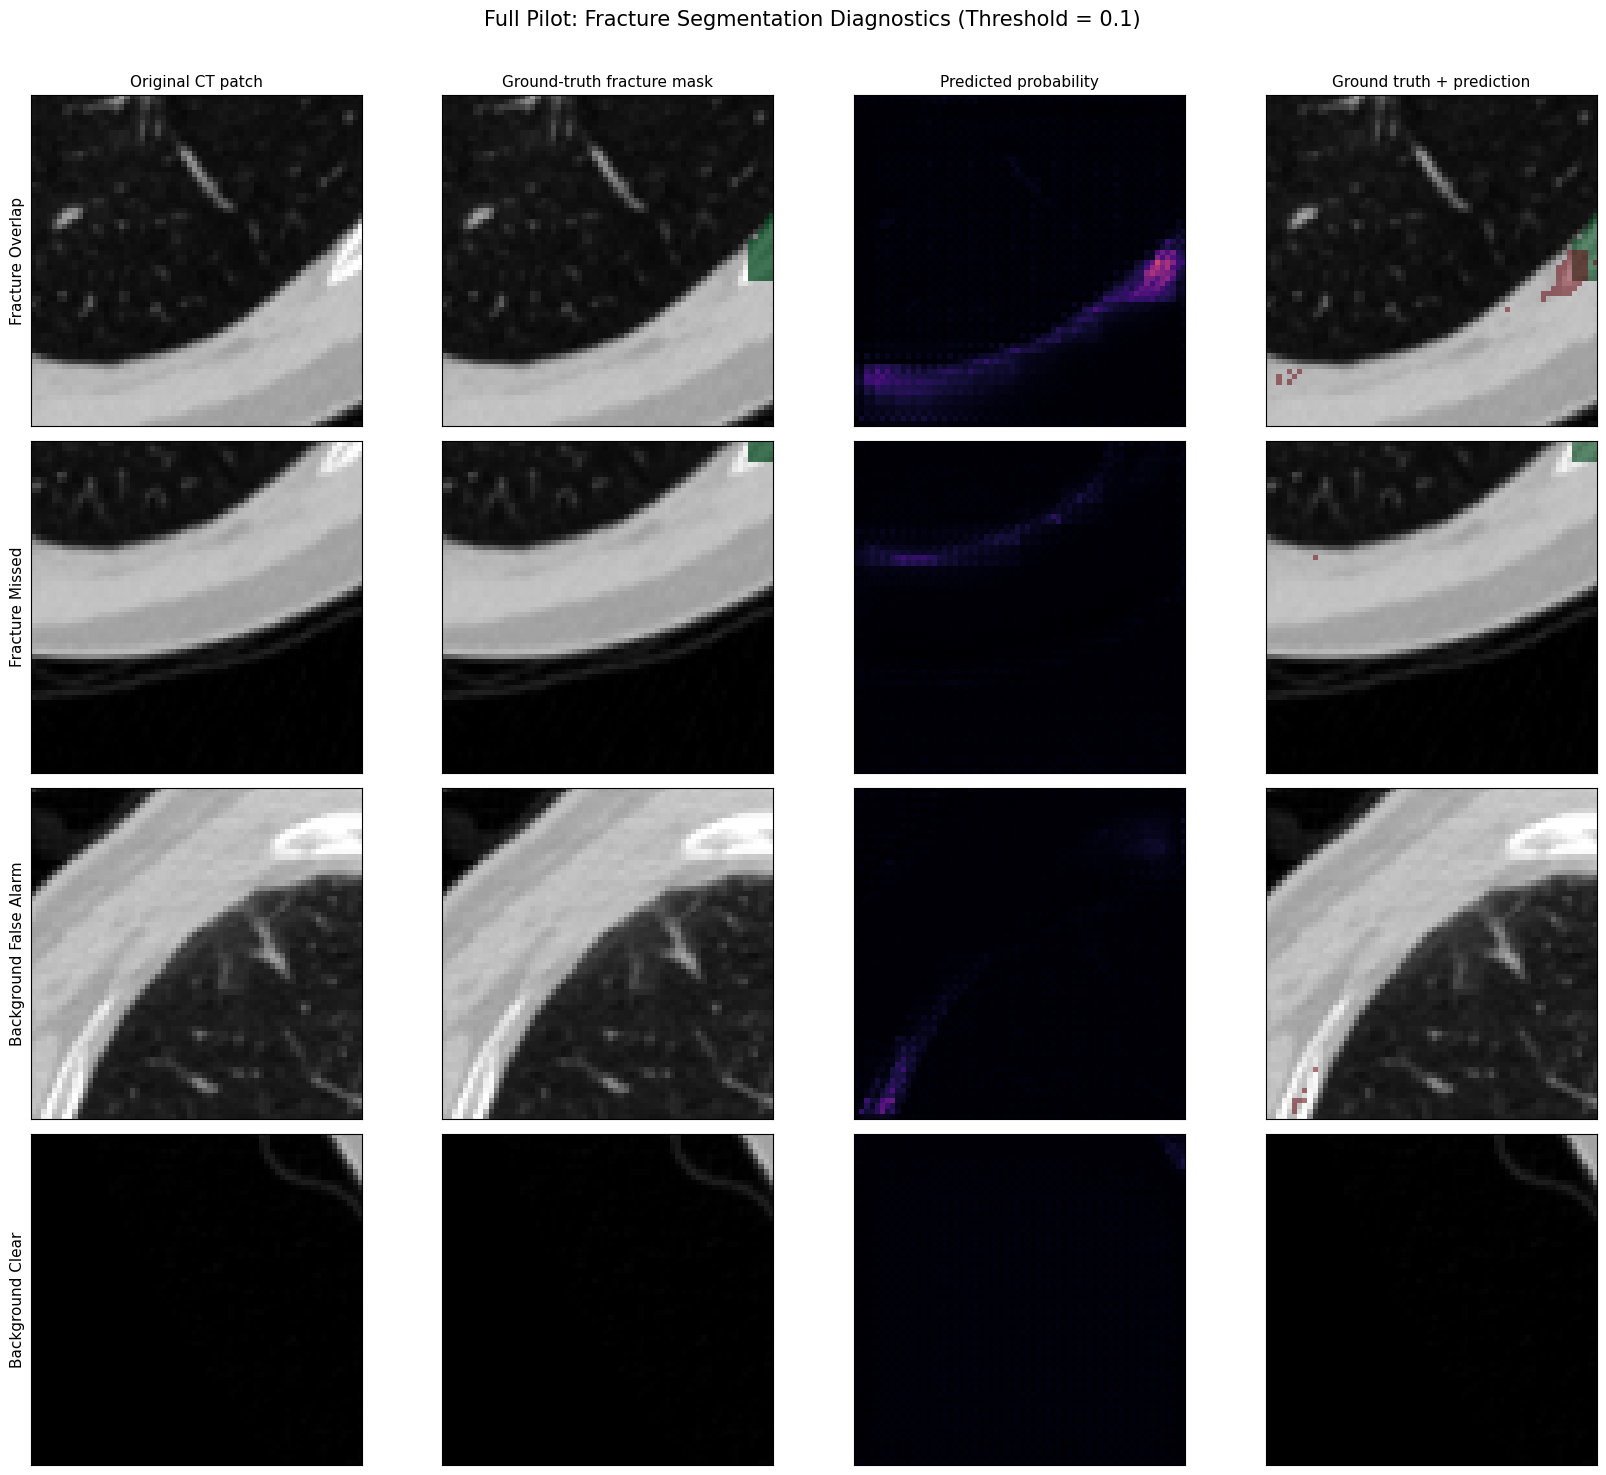


SELECTED DIAGNOSTIC EXAMPLES
              category  validation_batch  true_fracture_voxels  predicted_fracture_voxels  true_positive_voxels  false_positive_voxels  max_probability
      fracture_overlap                 2                   487                       5535                   121                   5414         0.402284
       fracture_missed                 0                   186                       1435                     0                   1435         0.306301
background_false_alarm                51                     0                         18                     0                     18         0.151057
      background_clear                50                     0                          0                     0                      0         0.061330

Figure saved:
/kaggle/working/training_results/full_pilot/segmentation_visual_diagnostics.png

Case details saved:
/kaggle/working/training_results/full_pilot/visual_diagnostic_cases.csv

Visual diagnostics: P

In [51]:

# ============================================================
# FULL PILOT — STEP 10
# VISUALIZE CT, GROUND TRUTH AND SEGMENTATION PREDICTIONS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("=" * 70)
print("FULL PILOT — VISUAL SEGMENTATION DIAGNOSTICS")
print("=" * 70)

THRESHOLD = 0.10

case_types = [
    "fracture_overlap",
    "fracture_missed",
    "background_false_alarm",
    "background_clear"
]

selected_cases = {}

# ------------------------------------------------------------
# 1. Find diagnostic examples
# ------------------------------------------------------------

for batch_idx in range(len(val_dataset)):

    X_batch, targets = val_dataset[batch_idx]

    predictions = best_model.predict_on_batch(X_batch)

    if isinstance(predictions, dict):
        outputs = predictions
    else:
        outputs = dict(
            zip(best_model.output_names, predictions)
        )

    image = np.asarray(X_batch)[0, ..., 0]

    ground_truth = (
        np.asarray(
            targets["segmentation_output"]
        )[0, ..., 0] >= 0.5
    )

    probabilities = np.asarray(
        outputs["segmentation_output"]
    )[0, ..., 0]

    predicted_mask = probabilities >= THRESHOLD

    tp = int(np.count_nonzero(
        ground_truth & predicted_mask
    ))

    fp = int(np.count_nonzero(
        ~ground_truth & predicted_mask
    ))

    true_positive_patch = bool(np.any(ground_truth))
    predicted_positive_patch = bool(np.any(predicted_mask))

    # Categorize example
    if true_positive_patch:

        category = (
            "fracture_overlap"
            if tp > 0 else "fracture_missed"
        )

    else:

        category = (
            "background_false_alarm"
            if predicted_positive_patch
            else "background_clear"
        )

    if category not in selected_cases:

        selected_cases[category] = {
            "batch_idx": batch_idx,
            "image": image.copy(),
            "truth": ground_truth.copy(),
            "probabilities": probabilities.copy(),
            "predicted": predicted_mask.copy(),
            "tp": tp,
            "fp": fp,
            "true_voxels": int(
                np.count_nonzero(ground_truth)
            ),
            "predicted_voxels": int(
                np.count_nonzero(predicted_mask)
            ),
        }

    if len(selected_cases) == len(case_types):
        break

# ------------------------------------------------------------
# 2. Verify diagnostic cases
# ------------------------------------------------------------

assert len(selected_cases) == 4, (
    f"Available categories: {list(selected_cases)}"
)

# ------------------------------------------------------------
# 3. Plot four examples
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 4,
    figsize=(17, 15)
)

column_titles = [
    "Original CT patch",
    "Ground-truth fracture mask",
    "Predicted probability",
    "Ground truth + prediction"
]

for row_idx, category in enumerate(case_types):

    case = selected_cases[category]

    ct = case["image"]
    gt = case["truth"]
    pred = case["predicted"]
    prob = case["probabilities"]

    # Choose an informative axial slice
    if np.any(gt):
        z = int(np.argmax(gt.sum(axis=(0, 1))))
    elif np.any(pred):
        z = int(np.argmax(pred.sum(axis=(0, 1))))
    else:
        z = int(np.argmax(prob.max(axis=(0, 1))))

    ct_slice = ct[:, :, z].T
    gt_slice = gt[:, :, z].T
    pred_slice = pred[:, :, z].T
    prob_slice = prob[:, :, z].T

    # Original CT
    axes[row_idx, 0].imshow(
        ct_slice,
        cmap="gray",
        origin="lower",
        vmin=0,
        vmax=1
    )

    # Ground truth overlay
    axes[row_idx, 1].imshow(
        ct_slice,
        cmap="gray",
        origin="lower",
        vmin=0,
        vmax=1
    )
    axes[row_idx, 1].imshow(
        np.ma.masked_where(~gt_slice, gt_slice),
        cmap="Greens",
        alpha=0.75,
        vmin=0,
        vmax=1,
        origin="lower"
    )

    # Raw predicted probabilities
    axes[row_idx, 2].imshow(
        prob_slice,
        cmap="magma",
        vmin=0,
        vmax=0.5,
        origin="lower"
    )

    # Ground truth and prediction together
    axes[row_idx, 3].imshow(
        ct_slice,
        cmap="gray",
        origin="lower",
        vmin=0,
        vmax=1
    )

    axes[row_idx, 3].imshow(
        np.ma.masked_where(~gt_slice, gt_slice),
        cmap="Greens",
        alpha=0.65,
        vmin=0,
        vmax=1,
        origin="lower"
    )

    axes[row_idx, 3].imshow(
        np.ma.masked_where(~pred_slice, pred_slice),
        cmap="Reds",
        alpha=0.5,
        vmin=0,
        vmax=1,
        origin="lower"
    )

    axes[row_idx, 0].set_ylabel(
        category.replace("_", " ").title(),
        fontsize=11
    )

    for col_idx in range(4):

        axes[row_idx, col_idx].set_xticks([])
        axes[row_idx, col_idx].set_yticks([])

        if row_idx == 0:
            axes[row_idx, col_idx].set_title(
                column_titles[col_idx],
                fontsize=11
            )

# ------------------------------------------------------------
# 4. Save figure
# ------------------------------------------------------------

fig.suptitle(
    "Full Pilot: Fracture Segmentation Diagnostics "
    f"(Threshold = {THRESHOLD})",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

VISUAL_DIAGNOSTICS_PATH = (
    FULL_PILOT_ROOT
    / "segmentation_visual_diagnostics.png"
)

plt.savefig(
    VISUAL_DIAGNOSTICS_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Save selection details
# ------------------------------------------------------------

case_rows = []

for category in case_types:

    case = selected_cases[category]

    case_rows.append({
        "category": category,
        "validation_batch": case["batch_idx"],
        "true_fracture_voxels": case["true_voxels"],
        "predicted_fracture_voxels":
            case["predicted_voxels"],
        "true_positive_voxels": case["tp"],
        "false_positive_voxels": case["fp"],
        "max_probability": float(
            case["probabilities"].max()
        ),
    })

case_df = pd.DataFrame(case_rows)

CASE_DETAILS_PATH = (
    FULL_PILOT_ROOT
    / "visual_diagnostic_cases.csv"
)

case_df.to_csv(CASE_DETAILS_PATH, index=False)

print("\nSELECTED DIAGNOSTIC EXAMPLES")
print(case_df.to_string(index=False))

print("\nFigure saved:")
print(VISUAL_DIAGNOSTICS_PATH)

print("\nCase details saved:")
print(CASE_DETAILS_PATH)

print("\nVisual diagnostics: PASS")
print("Full Pilot — Step 10: PASS")


In [53]:

# ============================================================
# FULL PILOT — STEP 11
# IMPLEMENT AND VERIFY BCE + SOFT DICE LOSS
# Enhanced 3D ResUNet
# ============================================================

import tensorflow as tf
from tensorflow import keras
import numpy as np

print("=" * 70)
print("3D RESUNET — BCE + SOFT DICE LOSS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Define combined segmentation loss
# ------------------------------------------------------------

@keras.utils.register_keras_serializable(
    package="RibFrac"
)
def bce_soft_dice_loss(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    # Binary cross-entropy across all voxels
    bce = tf.reduce_mean(
        keras.losses.binary_crossentropy(
            y_true,
            y_pred
        )
    )

    # Soft Dice operates on probabilities, not
    # thresholded binary predictions.
    axes = (1, 2, 3, 4)
    smooth = 1.0

    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=axes
    )

    true_sum = tf.reduce_sum(
        y_true,
        axis=axes
    )

    pred_sum = tf.reduce_sum(
        y_pred,
        axis=axes
    )

    dice = (
        2.0 * intersection + smooth
    ) / (
        true_sum + pred_sum + smooth
    )

    # Apply Dice loss to fracture-positive patches.
    # Empty-background patches are still trained by BCE.
    positive_mask = tf.cast(
        true_sum > 0,
        tf.float32
    )

    positive_dice_loss = tf.math.divide_no_nan(
        tf.reduce_sum(
            (1.0 - dice) * positive_mask
        ),
        tf.reduce_sum(positive_mask)
    )

    # Equal weighting for this first controlled experiment
    combined_loss = bce + positive_dice_loss

    return combined_loss

# ------------------------------------------------------------
# 2. Test using synthetic 3D masks
# ------------------------------------------------------------

y_true_test = np.zeros(
    (1, 16, 16, 16, 1),
    dtype=np.float32
)

# Create a small synthetic fracture region
y_true_test[
    0, 6:10, 6:10, 6:10, 0
] = 1.0

# Perfect predictions
y_perfect = y_true_test.copy()

# Empty predictions
y_empty = np.zeros_like(y_true_test)

# Incorrect predictions
y_wrong = np.zeros_like(y_true_test)
y_wrong[
    0, 0:4, 0:4, 0:4, 0
] = 1.0

perfect_loss = float(
    bce_soft_dice_loss(
        y_true_test, y_perfect
    ).numpy()
)

empty_loss = float(
    bce_soft_dice_loss(
        y_true_test, y_empty
    ).numpy()
)

wrong_loss = float(
    bce_soft_dice_loss(
        y_true_test, y_wrong
    ).numpy()
)

# ------------------------------------------------------------
# 3. Verify loss behaviour
# ------------------------------------------------------------

assert np.isfinite(perfect_loss)
assert np.isfinite(empty_loss)
assert np.isfinite(wrong_loss)

assert perfect_loss < empty_loss
assert perfect_loss < wrong_loss

# Verify background-only masks
background_loss = float(
    bce_soft_dice_loss(
        np.zeros_like(y_true_test),
        np.zeros_like(y_true_test)
    ).numpy()
)

assert np.isfinite(background_loss)
assert background_loss >= 0.0

# ------------------------------------------------------------
# 4. Display loss-function results
# ------------------------------------------------------------

print("\nLOSS FUNCTION SANITY CHECK")
print("-" * 70)

print(f"Perfect prediction loss: {perfect_loss:.6f}")
print(f"Empty prediction loss: {empty_loss:.6f}")
print(f"Wrong prediction loss: {wrong_loss:.6f}")
print(f"Empty background loss: {background_loss:.6f}")

print("\nLoss function behaves as expected: PASS")

print("\nSegmentation loss: BCE + Soft Dice")
print("Classification loss: Unchanged")
print("Model architecture: Unchanged")
print("Training started: No")

print("\nFull Pilot — Step 11: PASS")


3D RESUNET — BCE + SOFT DICE LOSS

LOSS FUNCTION SANITY CHECK
----------------------------------------------------------------------
Perfect prediction loss: 0.000000
Empty prediction loss: 1.236461
Wrong prediction loss: 1.493193
Empty background loss: 0.000000

Loss function behaves as expected: PASS

Segmentation loss: BCE + Soft Dice
Classification loss: Unchanged
Model architecture: Unchanged
Training started: No

Full Pilot — Step 11: PASS


In [54]:

# ============================================================
# FULL PILOT — STEP 12
# INITIALIZE AND COMPILE BCE + SOFT DICE MODEL
# ============================================================

import tensorflow as tf
from tensorflow import keras
from pathlib import Path

print("=" * 70)
print("3D RESUNET — BCE + SOFT DICE MODEL INITIALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify original model and dataset
# ------------------------------------------------------------

assert Path(MODEL_PATH).is_file()

assert len(train_dataset) == 202
assert len(val_dataset) == 100

assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

assert (
    train_patch_index["patient_id"].nunique()
    == 4
)

assert (
    val_patch_index["patient_id"].nunique()
    == 1
)

assert "test" not in set(
    train_patch_index["source_split"]
)

assert "test" not in set(
    val_patch_index["source_split"]
)

# ------------------------------------------------------------
# 2. Define new experiment identity
# ------------------------------------------------------------

DICE_EXPERIMENT_NAME = "bce_soft_dice_pilot"

DICE_PILOT_ROOT = (
    OUTPUT_ROOT / DICE_EXPERIMENT_NAME
)

DICE_PILOT_CHECKPOINT_ROOT = (
    DICE_PILOT_ROOT / "checkpoints"
)

DICE_PILOT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

DICE_PILOT_CHECKPOINT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. Verify existing baseline checkpoint is preserved
# ------------------------------------------------------------

BASELINE_CHECKPOINT_PATH = (
    OUTPUT_ROOT
    / "full_pilot"
    / "checkpoints"
    / "best_full_pilot_model.keras"
)

assert BASELINE_CHECKPOINT_PATH.is_file(), (
    "Original BCE baseline checkpoint is missing."
)

# ------------------------------------------------------------
# 4. Reload original untrained model
# ------------------------------------------------------------

# Important:
# Do not initialize from the previously trained
# baseline or smoke-test checkpoints.

dice_model = keras.models.load_model(
    str(MODEL_PATH),
    compile=False
)

assert dice_model.count_params() == 7258326

assert dice_model.input_shape == (
    None, 64, 64, 64, 1
)

assert set(dice_model.output_names) == {
    "segmentation_output",
    "classification_output"
}

# ------------------------------------------------------------
# 5. Configure controlled experiment parameters
# ------------------------------------------------------------

DICE_TRAIN_EPOCHS = 50

DICE_TRAIN_STEPS = len(train_dataset)
DICE_VAL_STEPS = len(val_dataset)

DICE_LEARNING_RATE = float(LEARNING_RATE)

assert DICE_TRAIN_STEPS == 202
assert DICE_VAL_STEPS == 100
assert BATCH_SIZE == 1

# ------------------------------------------------------------
# 6. Compile with BCE + Soft Dice segmentation loss
# ------------------------------------------------------------

dice_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=DICE_LEARNING_RATE
    ),

    loss={
        "segmentation_output":
            bce_soft_dice_loss,

        "classification_output":
            keras.losses.SparseCategoricalCrossentropy()
    },

    loss_weights={
        "segmentation_output":
            SEGMENTATION_LOSS_WEIGHT,

        "classification_output":
            CLASSIFICATION_LOSS_WEIGHT
    },

    metrics={
        "segmentation_output": [
            keras.metrics.BinaryAccuracy(
                name="seg_accuracy"
            ),
            dice_coefficient,
            iou_coefficient
        ],

        "classification_output": [
            keras.metrics.SparseCategoricalAccuracy(
                name="cls_accuracy"
            )
        ]
    }
)

# ------------------------------------------------------------
# 7. Verify compilation
# ------------------------------------------------------------

assert dice_model.optimizer is not None

assert dice_model.count_params() == 7258326

assert dice_model is not best_model

assert BASELINE_CHECKPOINT_PATH.is_file()

# ------------------------------------------------------------
# 8. Display experiment configuration
# ------------------------------------------------------------

print("\nExperiment:", DICE_EXPERIMENT_NAME)

print("Model:", dice_model.name)

print("Input shape:", dice_model.input_shape)

print("Total parameters:", dice_model.count_params())

print("\nSegmentation loss: BCE + Soft Dice")
print("Classification loss: Sparse Categorical Cross-Entropy")

print("\nOptimizer: Adam")
print("Learning rate:", DICE_LEARNING_RATE)

print("\nMaximum epochs:", DICE_TRAIN_EPOCHS)
print("Batch size:", BATCH_SIZE)

print("Training patients:", 4)
print("Validation patients:", 1)

print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("Training steps:", DICE_TRAIN_STEPS)
print("Validation steps:", DICE_VAL_STEPS)

print("\nOriginal baseline checkpoint preserved:")
print(BASELINE_CHECKPOINT_PATH)

print("\nNew experiment directory:")
print(DICE_PILOT_ROOT)

print("\nModel initialized from original weights: PASS")
print("Model compilation: PASS")
print("Training started: No")

print("\nFull Pilot — Step 12: PASS")


3D RESUNET — BCE + SOFT DICE MODEL INITIALIZATION

Experiment: bce_soft_dice_pilot
Model: Enhanced_3D_ResUNet_MultiTask
Input shape: (None, 64, 64, 64, 1)
Total parameters: 7258326

Segmentation loss: BCE + Soft Dice
Classification loss: Sparse Categorical Cross-Entropy

Optimizer: Adam
Learning rate: 0.0001

Maximum epochs: 50
Batch size: 1
Training patients: 4
Validation patients: 1
Training patches: 202
Validation patches: 100
Training steps: 202
Validation steps: 100

Original baseline checkpoint preserved:
/kaggle/working/training_results/full_pilot/checkpoints/best_full_pilot_model.keras

New experiment directory:
/kaggle/working/training_results/bce_soft_dice_pilot

Model initialized from original weights: PASS
Model compilation: PASS
Training started: No

Full Pilot — Step 12: PASS


In [55]:

# ============================================================
# FULL PILOT — STEP 13
# CONFIGURE BCE + SOFT DICE TRAINING CALLBACKS
# ============================================================

from pathlib import Path
from tensorflow import keras

print("=" * 70)
print("3D RESUNET — BCE + SOFT DICE CALLBACK CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify experiment settings
# ------------------------------------------------------------

assert DICE_EXPERIMENT_NAME == "bce_soft_dice_pilot"

assert DICE_TRAIN_EPOCHS == 50
assert DICE_TRAIN_STEPS == 202
assert DICE_VAL_STEPS == 100

assert BATCH_SIZE == 1
assert dice_model.optimizer is not None

assert len(train_dataset) == DICE_TRAIN_STEPS
assert len(val_dataset) == DICE_VAL_STEPS

# ------------------------------------------------------------
# 2. Verify baseline model is preserved
# ------------------------------------------------------------

assert BASELINE_CHECKPOINT_PATH.is_file(), (
    "Original BCE baseline checkpoint is missing."
)

# ------------------------------------------------------------
# 3. Define separate experiment output paths
# ------------------------------------------------------------

DICE_BEST_MODEL_PATH = (
    DICE_PILOT_CHECKPOINT_ROOT
    / "best_bce_soft_dice_model.keras"
)

DICE_FINAL_MODEL_PATH = (
    DICE_PILOT_ROOT
    / "final_bce_soft_dice_model.keras"
)

DICE_HISTORY_CSV_PATH = (
    DICE_PILOT_ROOT
    / "bce_soft_dice_training_history.csv"
)

DICE_HISTORY_NPY_PATH = (
    DICE_PILOT_ROOT
    / "bce_soft_dice_training_history.npy"
)

DICE_HISTORY_JSON_PATH = (
    DICE_PILOT_ROOT
    / "bce_soft_dice_training_summary.json"
)

DICE_METRICS_PATH = (
    DICE_PILOT_ROOT
    / "validation_metrics.json"
)

DICE_CONFIG_PATH = (
    DICE_PILOT_ROOT
    / "experiment_config.json"
)

# ------------------------------------------------------------
# 4. Prevent accidental overwriting
# ------------------------------------------------------------

assert not DICE_BEST_MODEL_PATH.exists(), (
    "A BCE + Soft Dice checkpoint already exists. "
    "Inspect the existing experiment before retraining."
)

assert not DICE_HISTORY_CSV_PATH.exists(), (
    "A BCE + Soft Dice training history already exists. "
    "Inspect it before starting a new run."
)

# ------------------------------------------------------------
# 5. Configure model checkpoint
# ------------------------------------------------------------

dice_checkpoint_callback = (
    keras.callbacks.ModelCheckpoint(
        filepath=str(DICE_BEST_MODEL_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    )
)

# ------------------------------------------------------------
# 6. Configure early stopping
# ------------------------------------------------------------

dice_early_stopping_callback = (
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
)

# ------------------------------------------------------------
# 7. Configure learning-rate reduction
# ------------------------------------------------------------

dice_reduce_lr_callback = (
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
)

# ------------------------------------------------------------
# 8. Configure training-history logger
# ------------------------------------------------------------

dice_csv_logger_callback = (
    keras.callbacks.CSVLogger(
        filename=str(DICE_HISTORY_CSV_PATH),
        append=False
    )
)

# ------------------------------------------------------------
# 9. Configure numerical instability protection
# ------------------------------------------------------------

dice_nan_callback = (
    keras.callbacks.TerminateOnNaN()
)

# ------------------------------------------------------------
# 10. Assemble callbacks
# ------------------------------------------------------------

dice_training_callbacks = [
    dice_checkpoint_callback,
    dice_early_stopping_callback,
    dice_reduce_lr_callback,
    dice_csv_logger_callback,
    dice_nan_callback
]

assert len(dice_training_callbacks) == 5

# ------------------------------------------------------------
# 11. Verify directories and paths
# ------------------------------------------------------------

DICE_PILOT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

DICE_PILOT_CHECKPOINT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

assert DICE_PILOT_ROOT.is_dir()
assert DICE_PILOT_CHECKPOINT_ROOT.is_dir()

assert (
    DICE_BEST_MODEL_PATH.resolve()
    != BASELINE_CHECKPOINT_PATH.resolve()
)

# ------------------------------------------------------------
# 12. Display configuration
# ------------------------------------------------------------

print("\nExperiment:", DICE_EXPERIMENT_NAME)

print("\nMaximum epochs:", DICE_TRAIN_EPOCHS)
print("Training steps per epoch:", DICE_TRAIN_STEPS)
print("Validation steps per epoch:", DICE_VAL_STEPS)

print("\nConfigured callbacks:")

for callback in dice_training_callbacks:
    print("-", type(callback).__name__)

print("\nBest model checkpoint:")
print(DICE_BEST_MODEL_PATH)

print("\nTraining history CSV:")
print(DICE_HISTORY_CSV_PATH)

print("\nExperiment directory:")
print(DICE_PILOT_ROOT)

print("\nOriginal BCE baseline preserved: True")
print("Training started: No")

print("\nBCE + Soft Dice callbacks configured: PASS")
print("Full Pilot — Step 13: PASS")


3D RESUNET — BCE + SOFT DICE CALLBACK CONFIGURATION

Experiment: bce_soft_dice_pilot

Maximum epochs: 50
Training steps per epoch: 202
Validation steps per epoch: 100

Configured callbacks:
- ModelCheckpoint
- EarlyStopping
- ReduceLROnPlateau
- CSVLogger
- TerminateOnNaN

Best model checkpoint:
/kaggle/working/training_results/bce_soft_dice_pilot/checkpoints/best_bce_soft_dice_model.keras

Training history CSV:
/kaggle/working/training_results/bce_soft_dice_pilot/bce_soft_dice_training_history.csv

Experiment directory:
/kaggle/working/training_results/bce_soft_dice_pilot

Original BCE baseline preserved: True
Training started: No

BCE + Soft Dice callbacks configured: PASS
Full Pilot — Step 13: PASS


In [56]:

# ============================================================
# FULL PILOT — STEP 14
# TRAIN BCE + SOFT DICE 3D RESUNET
# ============================================================

import numpy as np
from pathlib import Path

print("=" * 70)
print("STARTING 3D RESUNET — BCE + SOFT DICE TRAINING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify experiment configuration
# ------------------------------------------------------------

assert DICE_EXPERIMENT_NAME == "bce_soft_dice_pilot"

assert DICE_TRAIN_EPOCHS == 50
assert DICE_TRAIN_STEPS == 202
assert DICE_VAL_STEPS == 100

assert len(train_dataset) == 202
assert len(val_dataset) == 100
assert BATCH_SIZE == 1

assert dice_model.optimizer is not None

assert len(dice_training_callbacks) == 5

# ------------------------------------------------------------
# 2. Verify patient-level separation
# ------------------------------------------------------------

train_patient_ids = set(
    train_patch_index["patient_id"].unique()
)

val_patient_ids = set(
    val_patch_index["patient_id"].unique()
)

assert train_patient_ids.isdisjoint(
    val_patient_ids
)

assert len(train_patient_ids) == 4
assert len(val_patient_ids) == 1

assert "test" not in set(
    train_patch_index["source_split"]
)

assert "test" not in set(
    val_patch_index["source_split"]
)

# ------------------------------------------------------------
# 3. Protect existing checkpoints
# ------------------------------------------------------------

assert BASELINE_CHECKPOINT_PATH.is_file()

assert not DICE_BEST_MODEL_PATH.exists(), (
    "BCE + Soft Dice checkpoint already exists. "
    "Inspect it before starting another run."
)

assert not DICE_HISTORY_CSV_PATH.exists(), (
    "BCE + Soft Dice training history exists. "
    "Inspect it before starting another run."
)

# ------------------------------------------------------------
# 4. Verify model output structure
# ------------------------------------------------------------

assert dice_model.count_params() == 7258326

assert set(dice_model.output_names) == {
    "segmentation_output",
    "classification_output"
}

# ------------------------------------------------------------
# 5. Display experiment settings
# ------------------------------------------------------------

print("\nExperiment:", DICE_EXPERIMENT_NAME)
print("Model:", dice_model.name)

print("\nSegmentation loss: BCE + Soft Dice")
print("Classification loss: Sparse Categorical Cross-Entropy")

print("\nTraining patients:", len(train_patient_ids))
print("Validation patients:", len(val_patient_ids))

print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("\nMaximum epochs:", DICE_TRAIN_EPOCHS)
print("Training steps:", DICE_TRAIN_STEPS)
print("Validation steps:", DICE_VAL_STEPS)
print("Batch size:", BATCH_SIZE)

print("\nBest checkpoint:")
print(DICE_BEST_MODEL_PATH)

print("\nTraining history:")
print(DICE_HISTORY_CSV_PATH)

# ------------------------------------------------------------
# 6. Start training
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BCE + SOFT DICE TRAINING IN PROGRESS")
print("=" * 70)

dice_history = dice_model.fit(
    train_dataset,

    validation_data=val_dataset,

    epochs=DICE_TRAIN_EPOCHS,

    steps_per_epoch=DICE_TRAIN_STEPS,

    validation_steps=DICE_VAL_STEPS,

    callbacks=dice_training_callbacks,

    verbose=1
)

# ------------------------------------------------------------
# 7. Verify training results
# ------------------------------------------------------------

completed_epochs = len(
    dice_history.history["loss"]
)

assert completed_epochs > 0

assert np.all(
    np.isfinite(dice_history.history["loss"])
)

assert np.all(
    np.isfinite(dice_history.history["val_loss"])
)

assert DICE_BEST_MODEL_PATH.is_file()

assert DICE_HISTORY_CSV_PATH.is_file()

# ------------------------------------------------------------
# 8. Identify best validation epoch
# ------------------------------------------------------------

dice_train_losses = (
    dice_history.history["loss"]
)

dice_val_losses = (
    dice_history.history["val_loss"]
)

dice_best_epoch = (
    int(np.argmin(dice_val_losses)) + 1
)

dice_best_val_loss = float(
    np.min(dice_val_losses)
)

# ------------------------------------------------------------
# 9. Display training summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BCE + SOFT DICE — TRAINING SUMMARY")
print("=" * 70)

print("Experiment:", DICE_EXPERIMENT_NAME)

print("Maximum epochs:", DICE_TRAIN_EPOCHS)

print("Completed epochs:", completed_epochs)

print(
    "\nFinal training loss:",
    dice_train_losses[-1]
)

print(
    "Final validation loss:",
    dice_val_losses[-1]
)

print(
    "\nBest validation epoch:",
    dice_best_epoch
)

print(
    "Best validation loss:",
    dice_best_val_loss
)

print("\nBest model checkpoint:")
print(DICE_BEST_MODEL_PATH)

print("\nTraining history:")
print(DICE_HISTORY_CSV_PATH)

print("\nOriginal BCE baseline preserved:",
      BASELINE_CHECKPOINT_PATH.is_file())

print("\nBCE + Soft Dice training: PASS")
print("Full Pilot — Step 14: PASS")


STARTING 3D RESUNET — BCE + SOFT DICE TRAINING

Experiment: bce_soft_dice_pilot
Model: Enhanced_3D_ResUNet_MultiTask

Segmentation loss: BCE + Soft Dice
Classification loss: Sparse Categorical Cross-Entropy

Training patients: 4
Validation patients: 1
Training patches: 202
Validation patches: 100

Maximum epochs: 50
Training steps: 202
Validation steps: 100
Batch size: 1

Best checkpoint:
/kaggle/working/training_results/bce_soft_dice_pilot/checkpoints/best_bce_soft_dice_model.keras

Training history:
/kaggle/working/training_results/bce_soft_dice_pilot/bce_soft_dice_training_history.csv

BCE + SOFT DICE TRAINING IN PROGRESS
Epoch 1/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - classification_output_cls_accuracy: 0.3878 - classification_output_loss: 1.8559 - loss: 2.7233 - segmentation_output_dice_coefficient: 0.0052 - segmentation_output_iou_coefficient: 0.0026 - segmentation_output_loss: 0.8673 - segmentation_output_seg_accuracy: 0.8733
Epoch 1: val_loss improved from None to 2.196

In [57]:

# ============================================================
# FULL PILOT — STEP 15
# SAVE HISTORY AND EVALUATE BEST BCE + SOFT DICE MODEL
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from tensorflow import keras

print("=" * 70)
print("BCE + SOFT DICE — SAVE HISTORY AND EVALUATE MODEL")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify experiment
# ------------------------------------------------------------

assert DICE_EXPERIMENT_NAME == "bce_soft_dice_pilot"
assert DICE_BEST_MODEL_PATH.is_file()
assert BASELINE_CHECKPOINT_PATH.is_file()

assert len(train_dataset) == 202
assert len(val_dataset) == 100

assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

# ------------------------------------------------------------
# 2. Save training history
# ------------------------------------------------------------

dice_history_dict = {
    key: [float(value) for value in values]
    for key, values in dice_history.history.items()
}

dice_completed_epochs = len(
    dice_history_dict["loss"]
)

dice_best_epoch = (
    int(np.argmin(dice_history_dict["val_loss"])) + 1
)

assert dice_completed_epochs == 10
assert dice_best_epoch == 3

for values in dice_history_dict.values():
    assert len(values) == dice_completed_epochs
    assert np.all(np.isfinite(values))

np.save(
    DICE_HISTORY_NPY_PATH,
    dice_history_dict,
    allow_pickle=True
)

history_df = pd.read_csv(
    DICE_HISTORY_CSV_PATH
)

assert len(history_df) == dice_completed_epochs

# ------------------------------------------------------------
# 3. Save experiment summary
# ------------------------------------------------------------

dice_training_summary = {
    "experiment": DICE_EXPERIMENT_NAME,
    "segmentation_loss": "BCE + Soft Dice",
    "classification_loss":
        "Sparse Categorical Cross-Entropy",
    "maximum_epochs": DICE_TRAIN_EPOCHS,
    "epochs_completed": dice_completed_epochs,
    "best_epoch": dice_best_epoch,
    "best_validation_loss": float(
        min(dice_history_dict["val_loss"])
    ),
    "final_training_loss": float(
        dice_history_dict["loss"][-1]
    ),
    "final_validation_loss": float(
        dice_history_dict["val_loss"][-1]
    ),
    "training_patients": 4,
    "validation_patients": 1,
    "training_patches": 202,
    "validation_patches": 100,
    "internal_test_used": False,
    "best_checkpoint": str(DICE_BEST_MODEL_PATH),
    "history": dice_history_dict
}

with open(
    DICE_HISTORY_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(dice_training_summary, f, indent=2)

print("\nTraining history saved.")
print("Completed epochs:", dice_completed_epochs)
print("Best epoch:", dice_best_epoch)

# ------------------------------------------------------------
# 4. Load the best checkpoint
# ------------------------------------------------------------

best_dice_model = keras.models.load_model(
    str(DICE_BEST_MODEL_PATH),
    custom_objects={
        "bce_soft_dice_loss": bce_soft_dice_loss,
        "dice_coefficient": dice_coefficient,
        "iou_coefficient": iou_coefficient
    },
    compile=False
)

assert best_dice_model.count_params() == 7258326

assert set(best_dice_model.output_names) == {
    "segmentation_output",
    "classification_output"
}

print("\nBest checkpoint loaded successfully.")
print("Model:", best_dice_model.name)
print("Best checkpoint epoch:", dice_best_epoch)

# ------------------------------------------------------------
# 5. Compile for evaluation
# ------------------------------------------------------------

best_dice_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=DICE_LEARNING_RATE
    ),

    loss={
        "segmentation_output":
            bce_soft_dice_loss,

        "classification_output":
            keras.losses.SparseCategoricalCrossentropy()
    },

    loss_weights={
        "segmentation_output":
            SEGMENTATION_LOSS_WEIGHT,

        "classification_output":
            CLASSIFICATION_LOSS_WEIGHT
    },

    metrics={
        "segmentation_output": [
            keras.metrics.BinaryAccuracy(
                name="seg_accuracy"
            ),
            dice_coefficient,
            iou_coefficient
        ],

        "classification_output": [
            keras.metrics.SparseCategoricalAccuracy(
                name="cls_accuracy"
            )
        ]
    }
)

# ------------------------------------------------------------
# 6. Evaluate all 100 validation patches
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EVALUATING BEST BCE + SOFT DICE CHECKPOINT")
print("=" * 70)

dice_evaluation_results = best_dice_model.evaluate(
    val_dataset,
    steps=len(val_dataset),
    return_dict=True,
    verbose=1
)

# ------------------------------------------------------------
# 7. Verify metrics
# ------------------------------------------------------------

required_metrics = [
    "loss",
    "segmentation_output_loss",
    "classification_output_loss",
    "segmentation_output_dice_coefficient",
    "segmentation_output_iou_coefficient",
    "segmentation_output_seg_accuracy",
    "classification_output_cls_accuracy"
]

for metric in required_metrics:
    assert metric in dice_evaluation_results
    assert np.isfinite(dice_evaluation_results[metric])

# ------------------------------------------------------------
# 8. Save evaluation metrics
# ------------------------------------------------------------

dice_validation_metrics = {
    key: float(value)
    for key, value in dice_evaluation_results.items()
}

with open(
    DICE_METRICS_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(dice_validation_metrics, f, indent=2)

# ------------------------------------------------------------
# 9. Display evaluation results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BCE + SOFT DICE — VALIDATION RESULTS")
print("=" * 70)

for metric, value in dice_validation_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\nTraining epochs:", dice_completed_epochs)
print("Best checkpoint epoch:", dice_best_epoch)
print("Validation patients: 1")
print("Validation patches: 100")

print("\nTraining history:")
print(DICE_HISTORY_NPY_PATH)

print("\nValidation metrics:")
print(DICE_METRICS_PATH)

assert DICE_HISTORY_NPY_PATH.is_file()
assert DICE_HISTORY_JSON_PATH.is_file()
assert DICE_METRICS_PATH.is_file()

print("\nStep 15: PASS")


BCE + SOFT DICE — SAVE HISTORY AND EVALUATE MODEL

Training history saved.
Completed epochs: 10
Best epoch: 3

Best checkpoint loaded successfully.
Model: Enhanced_3D_ResUNet_MultiTask
Best checkpoint epoch: 3

EVALUATING BEST BCE + SOFT DICE CHECKPOINT
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - classification_output_cls_accuracy: 0.4400 - classification_output_loss: 1.5731 - loss: 2.0698 - segmentation_output_dice_coefficient: 0.3741 - segmentation_output_iou_coefficient: 0.3585 - segmentation_output_loss: 0.4967 - segmentation_output_seg_accuracy: 0.9954

BCE + SOFT DICE — VALIDATION RESULTS
classification_output_cls_accuracy: 0.440000
classification_output_loss: 1.573080
loss: 2.069820
segmentation_output_dice_coefficient: 0.374095
segmentation_output_iou_coefficient: 0.358524
segmentation_output_loss: 0.496740
segmentation_output_seg_accuracy: 0.995441

Training epochs: 10
Best checkpoint epoch: 3
Validation patients: 1
Validation patches: 100

Training history:
/kaggle/working/tr

In [58]:

# ============================================================
# FULL PILOT — STEP 16
# CONTROLLED COMPARISON: BCE VS BCE + SOFT DICE
# ============================================================

import numpy as np
import pandas as pd
import json

print("=" * 70)
print("3D RESUNET — CONTROLLED SEGMENTATION COMPARISON")
print("=" * 70)

# ------------------------------------------------------------
# 1. Define models and thresholds
# ------------------------------------------------------------

comparison_models = {
    "BCE_baseline": best_model,
    "BCE_plus_Soft_Dice": best_dice_model
}

thresholds = [0.05, 0.10, 0.20, 0.30, 0.50]

assert len(val_dataset) == 100
assert BASELINE_CHECKPOINT_PATH.is_file()
assert DICE_BEST_MODEL_PATH.is_file()

assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

# ------------------------------------------------------------
# 2. Initialize segmentation statistics
# ------------------------------------------------------------

comparison_stats = {}

classification_matrices = {}

for model_name in comparison_models:

    classification_matrices[model_name] = np.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=np.int64
    )

    comparison_stats[model_name] = {}

    for threshold in thresholds:

        comparison_stats[model_name][threshold] = {
            "TP": 0,
            "FP": 0,
            "FN": 0,
            "positive_dice_sum": 0.0,
            "positive_iou_sum": 0.0,
            "positive_overlap_patches": 0,
            "background_false_alarms": 0,
            "predicted_empty_patches": 0
        }

positive_patch_count = 0
background_patch_count = 0

# ------------------------------------------------------------
# 3. Evaluate both models on identical validation patches
# ------------------------------------------------------------

for batch_idx in range(len(val_dataset)):

    X_batch, targets = val_dataset[batch_idx]

    y_true = (
        np.asarray(
            targets["segmentation_output"]
        )[0, ..., 0] >= 0.5
    )

    true_class = int(
        np.asarray(
            targets["classification_output"]
        ).reshape(-1)[0]
    )

    true_voxels = int(np.count_nonzero(y_true))
    is_positive = true_voxels > 0

    if is_positive:
        positive_patch_count += 1
    else:
        background_patch_count += 1

    for model_name, current_model in comparison_models.items():

        predictions = current_model.predict_on_batch(
            X_batch
        )

        if isinstance(predictions, dict):
            outputs = predictions
        else:
            outputs = dict(
                zip(
                    current_model.output_names,
                    predictions
                )
            )

        # Classification prediction
        class_probabilities = np.asarray(
            outputs["classification_output"]
        )[0]

        predicted_class = int(
            np.argmax(class_probabilities)
        )

        classification_matrices[model_name][
            true_class, predicted_class
        ] += 1

        # Segmentation probabilities
        probabilities = np.asarray(
            outputs["segmentation_output"]
        )[0, ..., 0]

        assert probabilities.shape == y_true.shape
        assert np.all(np.isfinite(probabilities))

        # Evaluate the same thresholds for both models
        for threshold in thresholds:

            y_pred = probabilities >= threshold

            predicted_voxels = int(
                np.count_nonzero(y_pred)
            )

            tp = int(
                np.count_nonzero(y_pred & y_true)
            )

            fp = int(
                np.count_nonzero(y_pred & ~y_true)
            )

            fn = int(
                np.count_nonzero(~y_pred & y_true)
            )

            s = comparison_stats[
                model_name
            ][threshold]

            s["TP"] += tp
            s["FP"] += fp
            s["FN"] += fn

            if predicted_voxels == 0:
                s["predicted_empty_patches"] += 1

            if is_positive:

                dice = (
                    2.0 * tp
                    / (2 * tp + fp + fn)
                )

                iou = (
                    tp / (tp + fp + fn)
                )

                s["positive_dice_sum"] += dice
                s["positive_iou_sum"] += iou

                if tp > 0:
                    s["positive_overlap_patches"] += 1

            elif predicted_voxels > 0:

                s["background_false_alarms"] += 1

# ------------------------------------------------------------
# 4. Confirm validation composition
# ------------------------------------------------------------

assert positive_patch_count == 50
assert background_patch_count == 50

for model_name, cm in classification_matrices.items():
    assert int(cm.sum()) == 100

# ------------------------------------------------------------
# 5. Calculate comparable segmentation metrics
# ------------------------------------------------------------

comparison_rows = []

for model_name in comparison_models:

    for threshold in thresholds:

        s = comparison_stats[
            model_name
        ][threshold]

        tp = s["TP"]
        fp = s["FP"]
        fn = s["FN"]

        precision = (
            tp / (tp + fp)
            if tp + fp > 0 else 0.0
        )

        recall = (
            tp / (tp + fn)
            if tp + fn > 0 else 0.0
        )

        micro_dice = (
            2 * tp / (2 * tp + fp + fn)
            if 2 * tp + fp + fn > 0 else 0.0
        )

        micro_iou = (
            tp / (tp + fp + fn)
            if tp + fp + fn > 0 else 0.0
        )

        positive_mean_dice = (
            s["positive_dice_sum"]
            / positive_patch_count
        )

        positive_mean_iou = (
            s["positive_iou_sum"]
            / positive_patch_count
        )

        comparison_rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "Voxel Precision": precision,
            "Voxel Recall": recall,
            "Micro Dice": micro_dice,
            "Micro IoU": micro_iou,
            "Positive-only Dice":
                positive_mean_dice,
            "Positive-only IoU":
                positive_mean_iou,
            "Positive Patches With Overlap":
                s["positive_overlap_patches"],
            "Background False-Alarm Patches":
                s["background_false_alarms"],
            "Predicted Empty Patches":
                s["predicted_empty_patches"],
            "TP": tp,
            "FP": fp,
            "FN": fn
        })

comparison_df = pd.DataFrame(comparison_rows)

# ------------------------------------------------------------
# 6. Save comparison table
# ------------------------------------------------------------

COMPARISON_CSV_PATH = (
    DICE_PILOT_ROOT
    / "bce_vs_soft_dice_segmentation_comparison.csv"
)

comparison_df.to_csv(
    COMPARISON_CSV_PATH,
    index=False
)

# ------------------------------------------------------------
# 7. Display segmentation comparison
# ------------------------------------------------------------

display_columns = [
    "Model",
    "Threshold",
    "Voxel Precision",
    "Voxel Recall",
    "Micro Dice",
    "Micro IoU",
    "Positive-only Dice",
    "Positive Patches With Overlap",
    "Background False-Alarm Patches"
]

print("\nSEGMENTATION COMPARISON")
print("-" * 70)

print(
    comparison_df[display_columns].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 8. Compare classification accuracy
# ------------------------------------------------------------

class_labels = [
    CLASS_NAMES[i]
    for i in range(NUM_CLASSES)
]

classification_summary = {}

for model_name, cm in classification_matrices.items():

    accuracy = float(
        np.trace(cm) / np.sum(cm)
    )

    classification_summary[model_name] = {
        "accuracy": accuracy,
        "confusion_matrix": cm.tolist()
    }

    print("\n" + "-" * 70)
    print("CLASSIFICATION:", model_name)
    print("-" * 70)

    cm_df = pd.DataFrame(
        cm,
        index=class_labels,
        columns=class_labels
    )

    print(cm_df.to_string())
    print("Accuracy:", f"{accuracy:.4f}")

# ------------------------------------------------------------
# 9. Save classification comparison
# ------------------------------------------------------------

CLASS_COMPARISON_PATH = (
    DICE_PILOT_ROOT
    / "classification_model_comparison.json"
)

with open(
    CLASS_COMPARISON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            "class_labels": class_labels,
            "validation_patient_count": 1,
            "validation_patch_count": 100,
            "majority_class_baseline": 0.50,
            "models": classification_summary
        },
        f,
        indent=2
    )

# ------------------------------------------------------------
# 10. Verify results
# ------------------------------------------------------------

assert COMPARISON_CSV_PATH.is_file()
assert CLASS_COMPARISON_PATH.is_file()

assert len(comparison_df) == (
    len(comparison_models) * len(thresholds)
)

print("\nSaved segmentation comparison:")
print(COMPARISON_CSV_PATH)

print("\nSaved classification comparison:")
print(CLASS_COMPARISON_PATH)

print("\nControlled model comparison: PASS")
print("Full Pilot — Step 16: PASS")


3D RESUNET — CONTROLLED SEGMENTATION COMPARISON

SEGMENTATION COMPARISON
----------------------------------------------------------------------
             Model  Threshold  Voxel Precision  Voxel Recall  Micro Dice  Micro IoU  Positive-only Dice  Positive Patches With Overlap  Background False-Alarm Patches
      BCE_baseline   0.050000         0.114709      0.640523    0.194573   0.107771            0.151935                             37                              30
      BCE_baseline   0.100000         0.201022      0.438112    0.275592   0.159818            0.166980                             34                              21
      BCE_baseline   0.200000         0.417191      0.193847    0.264701   0.152539            0.121773                             32                               7
      BCE_baseline   0.300000         0.627084      0.023182    0.044712   0.022867            0.018746                             23                               5
      BCE_baseline   

In [59]:

# ============================================================
# FULL PILOT — STEP 17
# PREPARE CLASS-WEIGHTED CLASSIFICATION LOSS
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

print("=" * 70)
print("3D RESUNET — CLASS IMBALANCE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify patient-level separation
# ------------------------------------------------------------

assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

assert NUM_CLASSES == 5

# ------------------------------------------------------------
# 2. Calculate class frequencies from training data ONLY
# ------------------------------------------------------------

train_labels = (
    train_patch_index["classification"]
    .to_numpy(dtype=np.int32)
)

val_labels = (
    val_patch_index["classification"]
    .to_numpy(dtype=np.int32)
)

train_counts = np.bincount(
    train_labels,
    minlength=NUM_CLASSES
)

val_counts = np.bincount(
    val_labels,
    minlength=NUM_CLASSES
)

assert train_counts.sum() == 202
assert val_counts.sum() == 100
assert np.all(train_counts > 0)

# ------------------------------------------------------------
# 3. Calculate balanced class weights
# ------------------------------------------------------------

CLASS_WEIGHTS = (
    len(train_labels)
    / (NUM_CLASSES * train_counts)
).astype(np.float32)

class_weight_df = pd.DataFrame({
    "Class ID": np.arange(NUM_CLASSES),
    "Class Name": [
        CLASS_NAMES[i]
        for i in range(NUM_CLASSES)
    ],
    "Training Count": train_counts,
    "Validation Count": val_counts,
    "Class Weight": CLASS_WEIGHTS
})

print("\nCLASS DISTRIBUTION AND WEIGHTS")
print("-" * 70)

print(
    class_weight_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 4. Define serializable weighted classification loss
# ------------------------------------------------------------

@keras.utils.register_keras_serializable(
    package="RibFrac"
)
class WeightedSparseCategoricalCrossentropy(
    keras.losses.Loss
):

    def __init__(
        self,
        class_weights,
        name="weighted_sparse_categorical_crossentropy",
        **kwargs
    ):
        super().__init__(name=name, **kwargs)

        self.class_weights = [
            float(w) for w in class_weights
        ]

        self.weight_tensor = tf.constant(
            self.class_weights,
            dtype=tf.float32
        )

    def call(self, y_true, y_pred):

        y_true = tf.cast(
            tf.reshape(y_true, [-1]),
            tf.int32
        )

        per_sample_ce = (
            keras.losses.sparse_categorical_crossentropy(
                y_true,
                y_pred,
                from_logits=False
            )
        )

        sample_weights = tf.gather(
            self.weight_tensor,
            y_true
        )

        return per_sample_ce * sample_weights

    def get_config(self):

        config = super().get_config()

        config.update({
            "class_weights": self.class_weights
        })

        return config

weighted_classification_loss = (
    WeightedSparseCategoricalCrossentropy(
        class_weights=CLASS_WEIGHTS.tolist()
    )
)

# ------------------------------------------------------------
# 5. Sanity-check the weighted loss
# ------------------------------------------------------------

# Same predicted probability distribution:
# rare class errors should carry a higher penalty.

sample_probabilities = tf.constant(
    [[0.90, 0.025, 0.025, 0.025, 0.025]],
    dtype=tf.float32
)

background_loss = float(
    weighted_classification_loss(
        tf.constant([0]),
        sample_probabilities
    ).numpy()
)

buckle_loss = float(
    weighted_classification_loss(
        tf.constant([3]),
        sample_probabilities
    ).numpy()
)

assert np.isfinite(background_loss)
assert np.isfinite(buckle_loss)

assert CLASS_WEIGHTS[3] > CLASS_WEIGHTS[0]
assert buckle_loss > background_loss

# Verify class-weight configuration
loss_config = weighted_classification_loss.get_config()

assert len(loss_config["class_weights"]) == NUM_CLASSES

# ------------------------------------------------------------
# 6. Display verification results
# ------------------------------------------------------------

print("\nWEIGHTED CLASSIFICATION LOSS CHECK")
print("-" * 70)

print(
    "Background example loss:",
    f"{background_loss:.6f}"
)

print(
    "Buckle example loss:",
    f"{buckle_loss:.6f}"
)

print("\nClass weights computed from training only: True")
print("Validation class weights used: False")
print("Training started: No")

print("\nWeighted classification loss verified: PASS")
print("Full Pilot — Step 17: PASS")


3D RESUNET — CLASS IMBALANCE ANALYSIS

CLASS DISTRIBUTION AND WEIGHTS
----------------------------------------------------------------------
 Class ID    Class Name  Training Count  Validation Count  Class Weight
        0    background             101                50        0.4000
        1     displaced              20                10        2.0200
        2 non-displaced              59                10        0.6847
        3        buckle              10                30        4.0400
        4     segmental              12                 0        3.3667

WEIGHTED CLASSIFICATION LOSS CHECK
----------------------------------------------------------------------
Background example loss: 0.042144
Buckle example loss: 14.903073

Class weights computed from training only: True
Validation class weights used: False
Training started: No

Weighted classification loss verified: PASS
Full Pilot — Step 17: PASS


In [60]:

# ============================================================
# FULL PILOT — STEP 18
# INITIALIZE AND COMPILE CLASS-WEIGHTED 3D RESUNET
# ============================================================

import numpy as np
import tensorflow as tf
from tensorflow import keras
from pathlib import Path

print("=" * 70)
print("3D RESUNET — CLASS-WEIGHTED MODEL INITIALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify required model and dataset
# ------------------------------------------------------------

assert Path(MODEL_PATH).is_file()

assert len(train_dataset) == 202
assert len(val_dataset) == 100

assert NUM_CLASSES == 5
assert BATCH_SIZE == 1

assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

assert "test" not in set(
    train_patch_index["source_split"]
)

assert "test" not in set(
    val_patch_index["source_split"]
)

# ------------------------------------------------------------
# 2. Verify class-weight configuration
# ------------------------------------------------------------

assert len(CLASS_WEIGHTS) == NUM_CLASSES
assert np.all(CLASS_WEIGHTS > 0)
assert np.all(np.isfinite(CLASS_WEIGHTS))

assert isinstance(
    weighted_classification_loss,
    WeightedSparseCategoricalCrossentropy
)

# ------------------------------------------------------------
# 3. Define new experiment identity
# ------------------------------------------------------------

WEIGHTED_EXPERIMENT_NAME = "class_weighted_ce_pilot"

WEIGHTED_PILOT_ROOT = (
    OUTPUT_ROOT / WEIGHTED_EXPERIMENT_NAME
)

WEIGHTED_CHECKPOINT_ROOT = (
    WEIGHTED_PILOT_ROOT / "checkpoints"
)

WEIGHTED_PILOT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

WEIGHTED_CHECKPOINT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 4. Verify previous experiments remain preserved
# ------------------------------------------------------------

assert BASELINE_CHECKPOINT_PATH.is_file(), (
    "BCE baseline checkpoint is missing."
)

assert DICE_BEST_MODEL_PATH.is_file(), (
    "BCE + Soft Dice checkpoint is missing."
)

# ------------------------------------------------------------
# 5. Reload original untrained model
# ------------------------------------------------------------

# Do NOT use best_model or best_dice_model.
# This experiment must start from the original weights.

weighted_model = keras.models.load_model(
    str(MODEL_PATH),
    compile=False
)

assert weighted_model.count_params() == 7258326

assert weighted_model.input_shape == (
    None, 64, 64, 64, 1
)

assert set(weighted_model.output_names) == {
    "segmentation_output",
    "classification_output"
}

assert weighted_model is not best_model
assert weighted_model is not best_dice_model

# ------------------------------------------------------------
# 6. Define training parameters
# ------------------------------------------------------------

WEIGHTED_TRAIN_EPOCHS = 50

WEIGHTED_TRAIN_STEPS = len(train_dataset)

WEIGHTED_VAL_STEPS = len(val_dataset)

WEIGHTED_LEARNING_RATE = float(LEARNING_RATE)

assert WEIGHTED_TRAIN_STEPS == 202
assert WEIGHTED_VAL_STEPS == 100

# ------------------------------------------------------------
# 7. Compile class-weighted model
# ------------------------------------------------------------

weighted_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=WEIGHTED_LEARNING_RATE
    ),

    loss={
        # Keep original BCE segmentation loss
        "segmentation_output":
            keras.losses.BinaryCrossentropy(),

        # Change only classification loss
        "classification_output":
            weighted_classification_loss
    },

    loss_weights={
        "segmentation_output":
            SEGMENTATION_LOSS_WEIGHT,

        "classification_output":
            CLASSIFICATION_LOSS_WEIGHT
    },

    metrics={
        "segmentation_output": [
            keras.metrics.BinaryAccuracy(
                name="seg_accuracy"
            ),
            dice_coefficient,
            iou_coefficient
        ],

        "classification_output": [
            keras.metrics.SparseCategoricalAccuracy(
                name="cls_accuracy"
            )
        ]
    }
)

# ------------------------------------------------------------
# 8. Verify compilation
# ------------------------------------------------------------

assert weighted_model.optimizer is not None

assert weighted_model.count_params() == 7258326

assert BASELINE_CHECKPOINT_PATH.is_file()
assert DICE_BEST_MODEL_PATH.is_file()

# ------------------------------------------------------------
# 9. Display experiment configuration
# ------------------------------------------------------------

print("\nExperiment:", WEIGHTED_EXPERIMENT_NAME)

print("Model:", weighted_model.name)

print("Input shape:", weighted_model.input_shape)

print("Total parameters:", weighted_model.count_params())

print("\nSegmentation loss: BinaryCrossentropy")

print(
    "Classification loss: "
    "WeightedSparseCategoricalCrossentropy"
)

print("\nCLASS WEIGHTS")

for class_id in range(NUM_CLASSES):

    print(
        f"{CLASS_NAMES[class_id]}: "
        f"{CLASS_WEIGHTS[class_id]:.4f}"
    )

print("\nOptimizer: Adam")

print("Learning rate:", WEIGHTED_LEARNING_RATE)

print("\nMaximum epochs:", WEIGHTED_TRAIN_EPOCHS)
print("Batch size:", BATCH_SIZE)

print("Training patients:",
      train_patch_index["patient_id"].nunique())

print("Validation patients:",
      val_patch_index["patient_id"].nunique())

print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("Training steps:", WEIGHTED_TRAIN_STEPS)
print("Validation steps:", WEIGHTED_VAL_STEPS)

print("\nOriginal BCE baseline preserved: True")
print("BCE + Soft Dice checkpoint preserved: True")

print("\nNew experiment directory:")
print(WEIGHTED_PILOT_ROOT)

print("\nOriginal model weights loaded: PASS")
print("Class-weighted model compilation: PASS")
print("Training started: No")

print("\nFull Pilot — Step 18: PASS")


3D RESUNET — CLASS-WEIGHTED MODEL INITIALIZATION

Experiment: class_weighted_ce_pilot
Model: Enhanced_3D_ResUNet_MultiTask
Input shape: (None, 64, 64, 64, 1)
Total parameters: 7258326

Segmentation loss: BinaryCrossentropy
Classification loss: WeightedSparseCategoricalCrossentropy

CLASS WEIGHTS
background: 0.4000
displaced: 2.0200
non-displaced: 0.6847
buckle: 4.0400
segmental: 3.3667

Optimizer: Adam
Learning rate: 0.0001

Maximum epochs: 50
Batch size: 1
Training patients: 4
Validation patients: 1
Training patches: 202
Validation patches: 100
Training steps: 202
Validation steps: 100

Original BCE baseline preserved: True
BCE + Soft Dice checkpoint preserved: True

New experiment directory:
/kaggle/working/training_results/class_weighted_ce_pilot

Original model weights loaded: PASS
Class-weighted model compilation: PASS
Training started: No

Full Pilot — Step 18: PASS


In [61]:

# ============================================================
# FULL PILOT — STEP 19
# CONFIGURE CLASS-WEIGHTED MODEL TRAINING CALLBACKS
# ============================================================

import json
import numpy as np
from pathlib import Path
from tensorflow import keras

print("=" * 70)
print("3D RESUNET — CLASS-WEIGHTED CALLBACK CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify experiment
# ------------------------------------------------------------

assert WEIGHTED_EXPERIMENT_NAME == "class_weighted_ce_pilot"

assert WEIGHTED_TRAIN_EPOCHS == 50
assert WEIGHTED_TRAIN_STEPS == 202
assert WEIGHTED_VAL_STEPS == 100

assert BATCH_SIZE == 1
assert weighted_model.optimizer is not None

assert len(train_dataset) == WEIGHTED_TRAIN_STEPS
assert len(val_dataset) == WEIGHTED_VAL_STEPS

assert len(CLASS_WEIGHTS) == NUM_CLASSES
assert np.all(np.isfinite(CLASS_WEIGHTS))

# ------------------------------------------------------------
# 2. Verify previous checkpoints remain intact
# ------------------------------------------------------------

assert BASELINE_CHECKPOINT_PATH.is_file()
assert DICE_BEST_MODEL_PATH.is_file()

# ------------------------------------------------------------
# 3. Create experiment directories
# ------------------------------------------------------------

WEIGHTED_PILOT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

WEIGHTED_CHECKPOINT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 4. Define model and results paths
# ------------------------------------------------------------

WEIGHTED_BEST_MODEL_PATH = (
    WEIGHTED_CHECKPOINT_ROOT
    / "best_class_weighted_model.keras"
)

WEIGHTED_FINAL_MODEL_PATH = (
    WEIGHTED_PILOT_ROOT
    / "final_class_weighted_model.keras"
)

WEIGHTED_HISTORY_CSV_PATH = (
    WEIGHTED_PILOT_ROOT
    / "class_weighted_training_history.csv"
)

WEIGHTED_HISTORY_NPY_PATH = (
    WEIGHTED_PILOT_ROOT
    / "class_weighted_training_history.npy"
)

WEIGHTED_HISTORY_JSON_PATH = (
    WEIGHTED_PILOT_ROOT
    / "class_weighted_training_summary.json"
)

WEIGHTED_METRICS_PATH = (
    WEIGHTED_PILOT_ROOT
    / "validation_metrics.json"
)

WEIGHTED_CONFIG_PATH = (
    WEIGHTED_PILOT_ROOT
    / "experiment_config.json"
)

WEIGHTED_CLASS_WEIGHTS_PATH = (
    WEIGHTED_PILOT_ROOT
    / "class_weights.json"
)

# ------------------------------------------------------------
# 5. Prevent accidental overwriting
# ------------------------------------------------------------

assert not WEIGHTED_BEST_MODEL_PATH.exists(), (
    "Class-weighted checkpoint already exists. "
    "Inspect the previous run before retraining."
)

assert not WEIGHTED_HISTORY_CSV_PATH.exists(), (
    "Class-weighted training history already exists."
)

# ------------------------------------------------------------
# 6. Model checkpoint
# ------------------------------------------------------------

weighted_checkpoint_callback = (
    keras.callbacks.ModelCheckpoint(
        filepath=str(WEIGHTED_BEST_MODEL_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    )
)

# ------------------------------------------------------------
# 7. Early stopping
# ------------------------------------------------------------

weighted_early_stopping_callback = (
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
)

# ------------------------------------------------------------
# 8. Learning-rate reduction
# ------------------------------------------------------------

weighted_reduce_lr_callback = (
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
)

# ------------------------------------------------------------
# 9. CSV training-history logger
# ------------------------------------------------------------

weighted_csv_logger_callback = (
    keras.callbacks.CSVLogger(
        filename=str(WEIGHTED_HISTORY_CSV_PATH),
        append=False
    )
)

# ------------------------------------------------------------
# 10. Numerical instability protection
# ------------------------------------------------------------

weighted_nan_callback = (
    keras.callbacks.TerminateOnNaN()
)

# ------------------------------------------------------------
# 11. Assemble callbacks
# ------------------------------------------------------------

weighted_training_callbacks = [
    weighted_checkpoint_callback,
    weighted_early_stopping_callback,
    weighted_reduce_lr_callback,
    weighted_csv_logger_callback,
    weighted_nan_callback
]

assert len(weighted_training_callbacks) == 5

# ------------------------------------------------------------
# 12. Save class weights for reproducibility
# ------------------------------------------------------------

class_weight_record = {
    "experiment": WEIGHTED_EXPERIMENT_NAME,
    "source": "training_patch_index_only",
    "formula": "N / (num_classes * class_count)",
    "training_patch_count": int(len(train_patch_index)),
    "weights": {
        str(i): {
            "class_name": CLASS_NAMES[i],
            "training_count": int(train_counts[i]),
            "weight": float(CLASS_WEIGHTS[i])
        }
        for i in range(NUM_CLASSES)
    }
}

with open(
    WEIGHTED_CLASS_WEIGHTS_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(class_weight_record, f, indent=2)

# ------------------------------------------------------------
# 13. Verify output paths
# ------------------------------------------------------------

assert WEIGHTED_CLASS_WEIGHTS_PATH.is_file()

assert (
    WEIGHTED_BEST_MODEL_PATH.resolve()
    != BASELINE_CHECKPOINT_PATH.resolve()
)

assert (
    WEIGHTED_BEST_MODEL_PATH.resolve()
    != DICE_BEST_MODEL_PATH.resolve()
)

# ------------------------------------------------------------
# 14. Display callback configuration
# ------------------------------------------------------------

print("\nExperiment:", WEIGHTED_EXPERIMENT_NAME)

print("\nMaximum epochs:", WEIGHTED_TRAIN_EPOCHS)
print("Training steps:", WEIGHTED_TRAIN_STEPS)
print("Validation steps:", WEIGHTED_VAL_STEPS)
print("Batch size:", BATCH_SIZE)

print("\nConfigured callbacks:")

for callback in weighted_training_callbacks:
    print("-", type(callback).__name__)

print("\nBest checkpoint:")
print(WEIGHTED_BEST_MODEL_PATH)

print("\nTraining history:")
print(WEIGHTED_HISTORY_CSV_PATH)

print("\nClass weights saved:")
print(WEIGHTED_CLASS_WEIGHTS_PATH)

print("\nPrevious model checkpoints preserved: True")
print("Training started: No")

print("\nClass-weighted callbacks configured: PASS")
print("Full Pilot — Step 19: PASS")


3D RESUNET — CLASS-WEIGHTED CALLBACK CONFIGURATION

Experiment: class_weighted_ce_pilot

Maximum epochs: 50
Training steps: 202
Validation steps: 100
Batch size: 1

Configured callbacks:
- ModelCheckpoint
- EarlyStopping
- ReduceLROnPlateau
- CSVLogger
- TerminateOnNaN

Best checkpoint:
/kaggle/working/training_results/class_weighted_ce_pilot/checkpoints/best_class_weighted_model.keras

Training history:
/kaggle/working/training_results/class_weighted_ce_pilot/class_weighted_training_history.csv

Class weights saved:
/kaggle/working/training_results/class_weighted_ce_pilot/class_weights.json

Previous model checkpoints preserved: True
Training started: No

Class-weighted callbacks configured: PASS
Full Pilot — Step 19: PASS


In [62]:

# ============================================================
# FULL PILOT — STEP 20
# TRAIN CLASS-WEIGHTED ENHANCED 3D RESUNET
# ============================================================

import numpy as np
from pathlib import Path

print("=" * 70)
print("STARTING 3D RESUNET — CLASS-WEIGHTED TRAINING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify experiment configuration
# ------------------------------------------------------------

assert WEIGHTED_EXPERIMENT_NAME == "class_weighted_ce_pilot"

assert WEIGHTED_TRAIN_EPOCHS == 50
assert WEIGHTED_TRAIN_STEPS == 202
assert WEIGHTED_VAL_STEPS == 100

assert BATCH_SIZE == 1

assert len(train_dataset) == 202
assert len(val_dataset) == 100

assert weighted_model.optimizer is not None
assert len(weighted_training_callbacks) == 5

# ------------------------------------------------------------
# 2. Verify patient-level separation
# ------------------------------------------------------------

train_patient_ids = set(
    train_patch_index["patient_id"].unique()
)

val_patient_ids = set(
    val_patch_index["patient_id"].unique()
)

assert train_patient_ids.isdisjoint(
    val_patient_ids
)

assert len(train_patient_ids) == 4
assert len(val_patient_ids) == 1

# Protect original internal test partition
assert "test" not in set(
    train_patch_index["source_split"]
)

assert "test" not in set(
    val_patch_index["source_split"]
)

# ------------------------------------------------------------
# 3. Verify class weights
# ------------------------------------------------------------

assert len(CLASS_WEIGHTS) == NUM_CLASSES

assert np.all(
    np.isfinite(CLASS_WEIGHTS)
)

assert np.all(CLASS_WEIGHTS > 0)

assert WEIGHTED_CLASS_WEIGHTS_PATH.is_file()

# ------------------------------------------------------------
# 4. Verify previous checkpoints remain intact
# ------------------------------------------------------------

assert BASELINE_CHECKPOINT_PATH.is_file()

assert DICE_BEST_MODEL_PATH.is_file()

# Prevent accidental overwriting
assert not WEIGHTED_BEST_MODEL_PATH.exists(), (
    "Class-weighted checkpoint already exists. "
    "Inspect the previous experiment before retraining."
)

assert not WEIGHTED_HISTORY_CSV_PATH.exists(), (
    "Class-weighted history already exists. "
    "Inspect the previous experiment before retraining."
)

# ------------------------------------------------------------
# 5. Verify model architecture
# ------------------------------------------------------------

assert weighted_model.count_params() == 7258326

assert weighted_model.input_shape == (
    None, 64, 64, 64, 1
)

assert set(weighted_model.output_names) == {
    "segmentation_output",
    "classification_output"
}

# ------------------------------------------------------------
# 6. Display experiment configuration
# ------------------------------------------------------------

print("\nExperiment:", WEIGHTED_EXPERIMENT_NAME)
print("Model:", weighted_model.name)

print("\nSegmentation loss: BinaryCrossentropy")

print(
    "Classification loss: "
    "WeightedSparseCategoricalCrossentropy"
)

print("\nTraining patients:", len(train_patient_ids))
print("Validation patients:", len(val_patient_ids))

print("Training patches:", len(train_patch_index))
print("Validation patches:", len(val_patch_index))

print("\nMaximum epochs:", WEIGHTED_TRAIN_EPOCHS)
print("Training steps:", WEIGHTED_TRAIN_STEPS)
print("Validation steps:", WEIGHTED_VAL_STEPS)

print("Batch size:", BATCH_SIZE)
print("Learning rate:", WEIGHTED_LEARNING_RATE)

print("\nClass weights:")

for class_id in range(NUM_CLASSES):
    print(
        f"  {CLASS_NAMES[class_id]}: "
        f"{CLASS_WEIGHTS[class_id]:.4f}"
    )

print("\nBest checkpoint:")
print(WEIGHTED_BEST_MODEL_PATH)

print("\nTraining history:")
print(WEIGHTED_HISTORY_CSV_PATH)

# ------------------------------------------------------------
# 7. Begin class-weighted training
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS-WEIGHTED 3D RESUNET TRAINING IN PROGRESS")
print("=" * 70)

weighted_history = weighted_model.fit(
    train_dataset,

    validation_data=val_dataset,

    epochs=WEIGHTED_TRAIN_EPOCHS,

    steps_per_epoch=WEIGHTED_TRAIN_STEPS,

    validation_steps=WEIGHTED_VAL_STEPS,

    callbacks=weighted_training_callbacks,

    verbose=1
)

# ------------------------------------------------------------
# 8. Verify training results
# ------------------------------------------------------------

weighted_completed_epochs = len(
    weighted_history.history["loss"]
)

assert weighted_completed_epochs > 0

assert np.all(
    np.isfinite(weighted_history.history["loss"])
)

assert np.all(
    np.isfinite(weighted_history.history["val_loss"])
)

assert WEIGHTED_BEST_MODEL_PATH.is_file()

assert WEIGHTED_HISTORY_CSV_PATH.is_file()

# ------------------------------------------------------------
# 9. Identify best validation epoch
# ------------------------------------------------------------

weighted_train_losses = (
    weighted_history.history["loss"]
)

weighted_val_losses = (
    weighted_history.history["val_loss"]
)

weighted_best_epoch = (
    int(np.argmin(weighted_val_losses)) + 1
)

weighted_best_val_loss = float(
    np.min(weighted_val_losses)
)

# ------------------------------------------------------------
# 10. Display training summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS-WEIGHTED 3D RESUNET — TRAINING SUMMARY")
print("=" * 70)

print("Experiment:", WEIGHTED_EXPERIMENT_NAME)

print("Maximum epochs:", WEIGHTED_TRAIN_EPOCHS)

print("Completed epochs:", weighted_completed_epochs)

print(
    "\nFinal training loss:",
    weighted_train_losses[-1]
)

print(
    "Final validation loss:",
    weighted_val_losses[-1]
)

print(
    "\nBest validation epoch:",
    weighted_best_epoch
)

print(
    "Best validation loss:",
    weighted_best_val_loss
)

print("\nBest model checkpoint:")
print(WEIGHTED_BEST_MODEL_PATH)

print("\nTraining history:")
print(WEIGHTED_HISTORY_CSV_PATH)

print("\nBCE baseline preserved:",
      BASELINE_CHECKPOINT_PATH.is_file())

print("BCE + Soft Dice model preserved:",
      DICE_BEST_MODEL_PATH.is_file())

print("\nClass-weighted training: PASS")
print("Full Pilot — Step 20: PASS")


STARTING 3D RESUNET — CLASS-WEIGHTED TRAINING

Experiment: class_weighted_ce_pilot
Model: Enhanced_3D_ResUNet_MultiTask

Segmentation loss: BinaryCrossentropy
Classification loss: WeightedSparseCategoricalCrossentropy

Training patients: 4
Validation patients: 1
Training patches: 202
Validation patches: 100

Maximum epochs: 50
Training steps: 202
Validation steps: 100
Batch size: 1
Learning rate: 0.0001

Class weights:
  background: 0.4000
  displaced: 2.0200
  non-displaced: 0.6847
  buckle: 4.0400
  segmental: 3.3667

Best checkpoint:
/kaggle/working/training_results/class_weighted_ce_pilot/checkpoints/best_class_weighted_model.keras

Training history:
/kaggle/working/training_results/class_weighted_ce_pilot/class_weighted_training_history.csv

CLASS-WEIGHTED 3D RESUNET TRAINING IN PROGRESS
Epoch 1/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - classification_output_cls_accuracy: 0.2855 - classification_output_loss: 2.1041 - loss: 2.4560 - segmentation_output_dice_coefficient: 0.006

In [63]:

# ============================================================
# FULL PILOT — STEP 21
# SAVE HISTORY AND EVALUATE CLASS-WEIGHTED MODEL
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path
from tensorflow import keras

print("=" * 70)
print("CLASS-WEIGHTED 3D RESUNET — SAVE AND EVALUATE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify experiment and datasets
# ------------------------------------------------------------

assert WEIGHTED_EXPERIMENT_NAME == "class_weighted_ce_pilot"

assert WEIGHTED_BEST_MODEL_PATH.is_file()
assert WEIGHTED_HISTORY_CSV_PATH.is_file()

assert BASELINE_CHECKPOINT_PATH.is_file()
assert DICE_BEST_MODEL_PATH.is_file()

assert len(train_dataset) == 202
assert len(val_dataset) == 100

assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

# ------------------------------------------------------------
# 2. Extract complete training history
# ------------------------------------------------------------

weighted_history_dict = {
    key: [float(value) for value in values]
    for key, values in weighted_history.history.items()
}

weighted_completed_epochs = len(
    weighted_history_dict["loss"]
)

assert weighted_completed_epochs == 16

for metric, values in weighted_history_dict.items():
    assert len(values) == weighted_completed_epochs
    assert np.all(np.isfinite(values)), metric

weighted_best_epoch = int(
    np.argmin(weighted_history_dict["val_loss"])
) + 1

assert weighted_best_epoch == 9

# ------------------------------------------------------------
# 3. Save NumPy history
# ------------------------------------------------------------

np.save(
    WEIGHTED_HISTORY_NPY_PATH,
    weighted_history_dict,
    allow_pickle=True
)

# Verify existing CSV
weighted_history_df = pd.read_csv(
    WEIGHTED_HISTORY_CSV_PATH
)

assert len(weighted_history_df) == weighted_completed_epochs

# ------------------------------------------------------------
# 4. Save experiment summary
# ------------------------------------------------------------

weighted_training_summary = {
    "experiment": WEIGHTED_EXPERIMENT_NAME,
    "segmentation_loss": "BinaryCrossentropy",
    "classification_loss":
        "WeightedSparseCategoricalCrossentropy",
    "maximum_epochs": int(WEIGHTED_TRAIN_EPOCHS),
    "epochs_completed": int(weighted_completed_epochs),
    "best_epoch": int(weighted_best_epoch),
    "best_validation_loss": float(
        min(weighted_history_dict["val_loss"])
    ),
    "final_training_loss": float(
        weighted_history_dict["loss"][-1]
    ),
    "final_validation_loss": float(
        weighted_history_dict["val_loss"][-1]
    ),
    "training_patients": int(
        train_patch_index["patient_id"].nunique()
    ),
    "validation_patients": int(
        val_patch_index["patient_id"].nunique()
    ),
    "training_patches": int(len(train_patch_index)),
    "validation_patches": int(len(val_patch_index)),
    "class_weights": {
        CLASS_NAMES[i]: float(CLASS_WEIGHTS[i])
        for i in range(NUM_CLASSES)
    },
    "internal_test_used": False,
    "best_checkpoint": str(WEIGHTED_BEST_MODEL_PATH),
    "history": weighted_history_dict,
}

with open(
    WEIGHTED_HISTORY_JSON_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(weighted_training_summary, f, indent=2)

print("\nTraining history saved.")
print("Completed epochs:", weighted_completed_epochs)
print("Best validation epoch:", weighted_best_epoch)

# ------------------------------------------------------------
# 5. Reload best model checkpoint
# ------------------------------------------------------------

best_weighted_model = keras.models.load_model(
    str(WEIGHTED_BEST_MODEL_PATH),
    compile=False
)

assert best_weighted_model.count_params() == 7258326

assert best_weighted_model.input_shape == (
    None, 64, 64, 64, 1
)

assert set(best_weighted_model.output_names) == {
    "segmentation_output",
    "classification_output"
}

print("\nBest class-weighted checkpoint loaded.")
print("Model:", best_weighted_model.name)
print("Checkpoint epoch:", weighted_best_epoch)

# ------------------------------------------------------------
# 6. Compile checkpoint for evaluation
# ------------------------------------------------------------

best_weighted_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=WEIGHTED_LEARNING_RATE
    ),

    loss={
        "segmentation_output":
            keras.losses.BinaryCrossentropy(),

        "classification_output":
            weighted_classification_loss
    },

    loss_weights={
        "segmentation_output":
            SEGMENTATION_LOSS_WEIGHT,

        "classification_output":
            CLASSIFICATION_LOSS_WEIGHT
    },

    metrics={
        "segmentation_output": [
            keras.metrics.BinaryAccuracy(
                name="seg_accuracy"
            ),
            dice_coefficient,
            iou_coefficient
        ],

        "classification_output": [
            keras.metrics.SparseCategoricalAccuracy(
                name="cls_accuracy"
            )
        ]
    }
)

# ------------------------------------------------------------
# 7. Evaluate complete validation set
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EVALUATING CLASS-WEIGHTED MODEL")
print("=" * 70)

weighted_evaluation_results = best_weighted_model.evaluate(
    val_dataset,
    steps=len(val_dataset),
    return_dict=True,
    verbose=1
)

# ------------------------------------------------------------
# 8. Verify evaluation metrics
# ------------------------------------------------------------

required_metrics = [
    "loss",
    "segmentation_output_loss",
    "classification_output_loss",
    "segmentation_output_dice_coefficient",
    "segmentation_output_iou_coefficient",
    "segmentation_output_seg_accuracy",
    "classification_output_cls_accuracy"
]

for metric in required_metrics:

    assert metric in weighted_evaluation_results

    assert np.isfinite(
        weighted_evaluation_results[metric]
    )

# ------------------------------------------------------------
# 9. Save validation metrics
# ------------------------------------------------------------

weighted_validation_metrics = {
    key: float(value)
    for key, value in weighted_evaluation_results.items()
}

with open(
    WEIGHTED_METRICS_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        weighted_validation_metrics,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 10. Display evaluation results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS-WEIGHTED 3D RESUNET — VALIDATION RESULTS")
print("=" * 70)

for metric, value in weighted_validation_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\nTraining epochs:", weighted_completed_epochs)
print("Best checkpoint epoch:", weighted_best_epoch)

print("Validation patients: 1")
print("Validation patches: 100")

print("\nTraining history:")
print(WEIGHTED_HISTORY_NPY_PATH)

print("\nTraining summary:")
print(WEIGHTED_HISTORY_JSON_PATH)

print("\nValidation metrics:")
print(WEIGHTED_METRICS_PATH)

# ------------------------------------------------------------
# 11. Final verification
# ------------------------------------------------------------

assert WEIGHTED_HISTORY_NPY_PATH.is_file()
assert WEIGHTED_HISTORY_JSON_PATH.is_file()
assert WEIGHTED_METRICS_PATH.is_file()

assert BASELINE_CHECKPOINT_PATH.is_file()
assert DICE_BEST_MODEL_PATH.is_file()

print("\nClass-weighted model evaluation: PASS")
print("Full Pilot — Step 21: PASS")


CLASS-WEIGHTED 3D RESUNET — SAVE AND EVALUATE

Training history saved.
Completed epochs: 16
Best validation epoch: 9

Best class-weighted checkpoint loaded.
Model: Enhanced_3D_ResUNet_MultiTask
Checkpoint epoch: 9

EVALUATING CLASS-WEIGHTED MODEL
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - classification_output_cls_accuracy: 0.3000 - classification_output_loss: 2.0874 - loss: 2.1064 - segmentation_output_dice_coefficient: 0.5001 - segmentation_output_iou_coefficient: 0.5000 - segmentation_output_loss: 0.0189 - segmentation_output_seg_accuracy: 0.9959

CLASS-WEIGHTED 3D RESUNET — VALIDATION RESULTS
classification_output_cls_accuracy: 0.300000
classification_output_loss: 2.087437
loss: 2.106368
segmentation_output_dice_coefficient: 0.500066
segmentation_output_iou_coefficient: 0.500033
segmentation_output_loss: 0.018932
segmentation_output_seg_accuracy: 0.995916

Training epochs: 16
Best checkpoint epoch: 9
Validation patients: 1
Validation patches: 100

Training history:
/kaggle/working

In [64]:

# ============================================================
# FULL PILOT — STEP 22
# COMPARE CLASSIFICATION PERFORMANCE OF THREE 3D RESUNETS
# ============================================================

import numpy as np
import pandas as pd
import json
from pathlib import Path

print("=" * 70)
print("3D RESUNET — THREE-MODEL CLASSIFICATION COMPARISON")
print("=" * 70)

# ------------------------------------------------------------
# 1. Define the three best models
# ------------------------------------------------------------

classification_models = {
    "A_BCE_baseline": best_model,
    "B_BCE_Soft_Dice": best_dice_model,
    "C_Class_weighted": best_weighted_model
}

assert len(val_dataset) == 100
assert len(val_patch_index) == 100
assert NUM_CLASSES == 5

assert BASELINE_CHECKPOINT_PATH.is_file()
assert DICE_BEST_MODEL_PATH.is_file()
assert WEIGHTED_BEST_MODEL_PATH.is_file()

# Verify patient-level separation
assert set(
    train_patch_index["patient_id"]
).isdisjoint(
    set(val_patch_index["patient_id"])
)

# ------------------------------------------------------------
# 2. Initialize confusion matrices
# ------------------------------------------------------------

confusion_matrices = {
    name: np.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=np.int64
    )
    for name in classification_models
}

class_names = [
    CLASS_NAMES[i]
    for i in range(NUM_CLASSES)
]

# ------------------------------------------------------------
# 3. Predict all validation patches
# ------------------------------------------------------------

for batch_idx in range(len(val_dataset)):

    X_batch, targets = val_dataset[batch_idx]

    true_labels = np.asarray(
        targets["classification_output"]
    ).reshape(-1).astype(int)

    for model_name, current_model in (
        classification_models.items()
    ):

        outputs = current_model.predict_on_batch(
            X_batch
        )

        if isinstance(outputs, dict):
            prediction_dict = outputs
        else:
            prediction_dict = dict(
                zip(current_model.output_names, outputs)
            )

        class_probabilities = np.asarray(
            prediction_dict["classification_output"]
        )

        predicted_labels = np.argmax(
            class_probabilities,
            axis=-1
        ).reshape(-1)

        assert len(true_labels) == len(predicted_labels)

        for true_class, pred_class in zip(
            true_labels,
            predicted_labels
        ):

            assert 0 <= true_class < NUM_CLASSES
            assert 0 <= pred_class < NUM_CLASSES

            confusion_matrices[model_name][
                true_class, pred_class
            ] += 1

# ------------------------------------------------------------
# 4. Create output directory
# ------------------------------------------------------------

CLASSIFICATION_COMPARISON_ROOT = (
    OUTPUT_ROOT / "classification_comparison"
)

CLASSIFICATION_COMPARISON_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 5. Calculate class-specific metrics
# ------------------------------------------------------------

all_class_rows = []
model_summary_rows = []

for model_name, cm in confusion_matrices.items():

    assert int(cm.sum()) == 100

    actual_support = cm.sum(axis=1)
    predicted_support = cm.sum(axis=0)

    class_f1 = {}

    for class_id in range(NUM_CLASSES):

        tp = int(cm[class_id, class_id])
        fp = int(predicted_support[class_id] - tp)
        fn = int(actual_support[class_id] - tp)

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0 else 0.0
        )

        # Recall is undefined when a class is absent
        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0 else np.nan
        )

        f1 = (
            2 * tp / (2 * tp + fp + fn)
            if actual_support[class_id] > 0
            else np.nan
        )

        class_f1[class_id] = f1

        all_class_rows.append({
            "Model": model_name,
            "Class": class_names[class_id],
            "Support": int(actual_support[class_id]),
            "Predicted": int(predicted_support[class_id]),
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

    accuracy = float(
        np.trace(cm) / np.sum(cm)
    )

    # Macro F1 over classes present in validation
    present_classes = [
        i for i in range(NUM_CLASSES)
        if actual_support[i] > 0
    ]

    macro_f1 = float(np.mean([
        class_f1[i]
        for i in present_classes
    ]))

    # Macro F1 for fracture classes present in validation
    present_fracture_classes = [
        i for i in present_classes
        if i != 0
    ]

    fracture_macro_f1 = float(np.mean([
        class_f1[i]
        for i in present_fracture_classes
    ]))

    # Recall of fracture patches classified as any
    # fracture category, regardless of exact subtype
    fracture_total = int(
        cm[1:, :].sum()
    )

    fracture_as_fracture = int(
        cm[1:, 1:].sum()
    )

    fracture_detection_recall = (
        fracture_as_fracture / fracture_total
        if fracture_total else np.nan
    )

    # Background patches incorrectly called fractures
    background_false_positives = int(
        cm[0, 1:].sum()
    )

    model_summary_rows.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro F1 (present classes)": macro_f1,
        "Fracture-class Macro F1":
            fracture_macro_f1,
        "Fracture-vs-background Recall":
            fracture_detection_recall,
        "Background false positives":
            background_false_positives
    })

    # Save confusion matrix
    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )

    cm_path = (
        CLASSIFICATION_COMPARISON_ROOT
        / f"{model_name}_confusion_matrix.csv"
    )

    cm_df.to_csv(cm_path)

    print("\n" + "-" * 70)
    print("MODEL:", model_name)
    print("-" * 70)

    print("Rows = actual class")
    print("Columns = predicted class")
    print(cm_df.to_string())

# ------------------------------------------------------------
# 6. Build comparison DataFrames
# ------------------------------------------------------------

class_metrics_df = pd.DataFrame(
    all_class_rows
)

model_summary_df = pd.DataFrame(
    model_summary_rows
)

# ------------------------------------------------------------
# 7. Save complete results
# ------------------------------------------------------------

CLASS_METRICS_PATH = (
    CLASSIFICATION_COMPARISON_ROOT
    / "per_class_metrics.csv"
)

MODEL_SUMMARY_PATH = (
    CLASSIFICATION_COMPARISON_ROOT
    / "classification_model_summary.csv"
)

class_metrics_df.to_csv(
    CLASS_METRICS_PATH,
    index=False
)

model_summary_df.to_csv(
    MODEL_SUMMARY_PATH,
    index=False
)

# ------------------------------------------------------------
# 8. Display model comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("THREE-MODEL CLASSIFICATION SUMMARY")
print("=" * 70)

print(
    model_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nPER-CLASS PERFORMANCE")
print("-" * 70)

print(
    class_metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. Verify the accuracy results
# ------------------------------------------------------------

expected_accuracy = {
    "A_BCE_baseline": 0.51,
    "B_BCE_Soft_Dice": 0.44,
    "C_Class_weighted": 0.30
}

for model_name, expected in expected_accuracy.items():

    actual = model_summary_df.loc[
        model_summary_df["Model"] == model_name,
        "Accuracy"
    ].iloc[0]

    assert np.isclose(
        actual, expected, atol=1e-6
    ), (
        f"Unexpected accuracy for {model_name}: {actual}"
    )

# ------------------------------------------------------------
# 10. Report validation limitations
# ------------------------------------------------------------

print("\nVALIDATION LIMITATIONS")
print("-" * 70)

print("Validation patients: 1")
print("Validation patches: 100")
print("Segmental examples: 0")
print("Segmental recall: NOT ESTIMABLE")

print("\nClass metrics saved:")
print(CLASS_METRICS_PATH)

print("\nModel summary saved:")
print(MODEL_SUMMARY_PATH)

print("\nThree-model classification analysis: PASS")
print("Full Pilot — Step 22: PASS")


3D RESUNET — THREE-MODEL CLASSIFICATION COMPARISON

----------------------------------------------------------------------
MODEL: A_BCE_baseline
----------------------------------------------------------------------
Rows = actual class
Columns = predicted class
               background  displaced  non-displaced  buckle  segmental
background             50          0              0       0          0
displaced              10          0              0       0          0
non-displaced           9          0              1       0          0
buckle                 27          0              3       0          0
segmental               0          0              0       0          0

----------------------------------------------------------------------
MODEL: B_BCE_Soft_Dice
----------------------------------------------------------------------
Rows = actual class
Columns = predicted class
               background  displaced  non-displaced  buckle  segmental
background             44    

In [65]:

# ============================================================
# FULL PILOT — STEP 23
# SUMMARIZE THREE-MODEL CLASSIFICATION RESULTS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

print("=" * 70)
print("3D RESUNET — CLASSIFICATION PERFORMANCE SUMMARY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load saved evaluation tables
# ------------------------------------------------------------

assert MODEL_SUMMARY_PATH.is_file()
assert CLASS_METRICS_PATH.is_file()

summary_df = pd.read_csv(MODEL_SUMMARY_PATH)
per_class_df = pd.read_csv(CLASS_METRICS_PATH)

# ------------------------------------------------------------
# 2. Display overall model comparison
# ------------------------------------------------------------

print("\nOVERALL MODEL PERFORMANCE")
print("-" * 70)

print(
    summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 3. Display fracture-class performance
# ------------------------------------------------------------

fracture_classes = [
    "displaced",
    "non-displaced",
    "buckle"
]

fracture_metrics_df = per_class_df[
    per_class_df["Class"].isin(fracture_classes)
].copy()

print("\nFRACTURE-CLASS PRECISION, RECALL AND F1")
print("-" * 70)

print(
    fracture_metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 4. Display class-weighted confusion matrix
# ------------------------------------------------------------

weighted_cm_path = (
    CLASSIFICATION_COMPARISON_ROOT
    / "C_Class_weighted_confusion_matrix.csv"
)

assert weighted_cm_path.is_file()

weighted_cm_df = pd.read_csv(
    weighted_cm_path,
    index_col=0
)

print("\nCLASS-WEIGHTED MODEL CONFUSION MATRIX")
print("-" * 70)

print("Rows = actual classes")
print("Columns = predicted classes")

print(weighted_cm_df.to_string())

# ------------------------------------------------------------
# 5. Identify the highest observed macro F1
# ------------------------------------------------------------

best_macro_idx = (
    summary_df["Macro F1 (present classes)"]
    .idxmax()
)

best_macro_row = summary_df.loc[best_macro_idx]

print("\nHIGHEST OBSERVED MACRO F1")
print("-" * 70)

print("Model:", best_macro_row["Model"])

print(
    "Macro F1:",
    f"{best_macro_row['Macro F1 (present classes)']:.4f}"
)

print(
    "Fracture-class Macro F1:",
    f"{best_macro_row['Fracture-class Macro F1']:.4f}"
)

# ------------------------------------------------------------
# 6. Report study limitations
# ------------------------------------------------------------

print("\nVALIDATION LIMITATIONS")
print("-" * 70)

print("Validation patients: 1")
print("Validation patches: 100")
print("Segmental class recall: Not estimable")
print("Independent internal test evaluated: No")

print("\nClassification summary verified: PASS")
print("Full Pilot — Step 23: PASS")


3D RESUNET — CLASSIFICATION PERFORMANCE SUMMARY

OVERALL MODEL PERFORMANCE
----------------------------------------------------------------------
           Model  Accuracy  Macro F1 (present classes)  Fracture-class Macro F1  Fracture-vs-background Recall  Background false positives
  A_BCE_baseline    0.5100                      0.2069                   0.0476                         0.0800                           0
 B_BCE_Soft_Dice    0.4400                      0.1760                   0.0000                         0.3800                           6
C_Class_weighted    0.3000                      0.1340                   0.1530                         1.0000                          48

FRACTURE-CLASS PRECISION, RECALL AND F1
----------------------------------------------------------------------
           Model         Class  Support  Predicted  Precision  Recall     F1
  A_BCE_baseline     displaced       10          0     0.0000  0.0000 0.0000
  A_BCE_baseline non-displaced  

3D RESUNET — FINAL CLASSIFICATION COMPARISON

MODEL COMPARISON
----------------------------------------------------------------------
           Model  Accuracy  Macro F1 (present classes)  Fracture-class Macro F1  Fracture-vs-background Recall  Background false positives
  A_BCE_baseline    0.5100                      0.2069                   0.0476                         0.0800                           0
 B_BCE_Soft_Dice    0.4400                      0.1760                   0.0000                         0.3800                           6
C_Class_weighted    0.3000                      0.1340                   0.1530                         1.0000                          48

CLASS-WEIGHTED MODEL — PER-CLASS PERFORMANCE
----------------------------------------------------------------------
        Class  Support  Predicted  Precision  Recall     F1
   background       50          2     1.0000  0.0400 0.0769
    displaced       10          1     0.0000  0.0000 0.0000
non-displaced

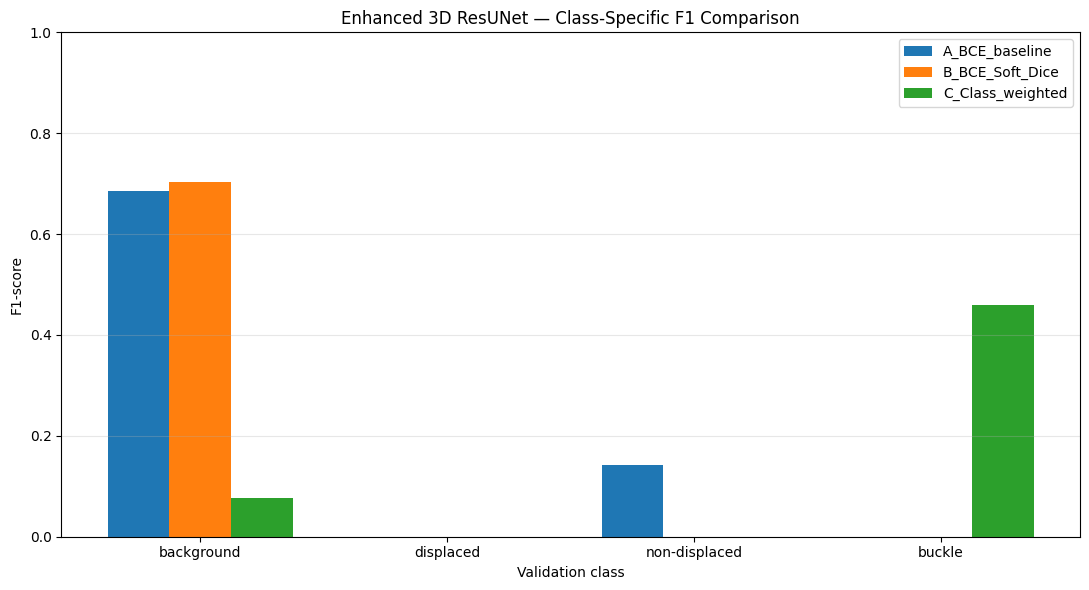


Figure saved:
/kaggle/working/training_results/classification_comparison/three_model_classification_f1.png

Validation patients: 1
Validation patches: 100
Segmental recall: Not estimable
Independent test data used: No

Classification comparison: PASS
Full Pilot — Step 24: PASS


In [66]:

# ============================================================
# FULL PILOT — STEP 24
# FINAL CLASSIFICATION COMPARISON AND VISUALIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 70)
print("3D RESUNET — FINAL CLASSIFICATION COMPARISON")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load results from completed experiments
# ------------------------------------------------------------

summary_df = pd.read_csv(MODEL_SUMMARY_PATH)
class_df = pd.read_csv(CLASS_METRICS_PATH)

models = [
    "A_BCE_baseline",
    "B_BCE_Soft_Dice",
    "C_Class_weighted"
]

assert set(models) == set(summary_df["Model"])

# ------------------------------------------------------------
# 2. Display model-level classification performance
# ------------------------------------------------------------

columns = [
    "Model",
    "Accuracy",
    "Macro F1 (present classes)",
    "Fracture-class Macro F1",
    "Fracture-vs-background Recall",
    "Background false positives"
]

print("\nMODEL COMPARISON")
print("-" * 70)

print(
    summary_df[columns].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 3. Display per-class performance of weighted model
# ------------------------------------------------------------

weighted_classes = class_df[
    class_df["Model"] == "C_Class_weighted"
].copy()

print("\nCLASS-WEIGHTED MODEL — PER-CLASS PERFORMANCE")
print("-" * 70)

print(
    weighted_classes[
        ["Class", "Support", "Predicted",
         "Precision", "Recall", "F1"]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 4. Display weighted model confusion matrix
# ------------------------------------------------------------

cm_path = (
    CLASSIFICATION_COMPARISON_ROOT
    / "C_Class_weighted_confusion_matrix.csv"
)

weighted_cm = pd.read_csv(
    cm_path,
    index_col=0
)

print("\nCLASS-WEIGHTED CONFUSION MATRIX")
print("Rows = actual class; columns = predicted class")
print("-" * 70)
print(weighted_cm.to_string())

# ------------------------------------------------------------
# 5. Compare class-weighted and baseline models
# ------------------------------------------------------------

summary_indexed = summary_df.set_index("Model")

baseline = summary_indexed.loc["A_BCE_baseline"]
weighted = summary_indexed.loc["C_Class_weighted"]

delta_accuracy = (
    weighted["Accuracy"] - baseline["Accuracy"]
)

delta_fracture_f1 = (
    weighted["Fracture-class Macro F1"]
    - baseline["Fracture-class Macro F1"]
)

delta_fracture_recall = (
    weighted["Fracture-vs-background Recall"]
    - baseline["Fracture-vs-background Recall"]
)

delta_background_fp = (
    weighted["Background false positives"]
    - baseline["Background false positives"]
)

print("\nCLASS WEIGHTING VS BCE BASELINE")
print("-" * 70)

print(f"Accuracy difference: {delta_accuracy:+.4f}")
print(f"Fracture macro F1 difference: {delta_fracture_f1:+.4f}")
print(f"Fracture recall difference: {delta_fracture_recall:+.4f}")
print(f"Background false-positive difference: {delta_background_fp:+.0f}")

# ------------------------------------------------------------
# 6. Plot F1-scores for evaluated classes
# ------------------------------------------------------------

class_order = [
    "background",
    "displaced",
    "non-displaced",
    "buckle"
]

pivot_df = class_df.pivot(
    index="Class",
    columns="Model",
    values="F1"
).reindex(class_order)

x = np.arange(len(class_order))
bar_width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

for model_idx, model_name in enumerate(models):

    positions = x + (
        model_idx - 1
    ) * bar_width

    ax.bar(
        positions,
        pivot_df[model_name].fillna(0).values,
        width=bar_width,
        label=model_name
    )

ax.set_xticks(x)
ax.set_xticklabels(class_order)

ax.set_ylim(0, 1)
ax.set_ylabel("F1-score")
ax.set_xlabel("Validation class")

ax.set_title(
    "Enhanced 3D ResUNet — "
    "Class-Specific F1 Comparison"
)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# ------------------------------------------------------------
# 7. Save classification comparison figure
# ------------------------------------------------------------

CLASS_F1_FIGURE_PATH = (
    CLASSIFICATION_COMPARISON_ROOT
    / "three_model_classification_f1.png"
)

plt.savefig(
    CLASS_F1_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert CLASS_F1_FIGURE_PATH.is_file()

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\nFigure saved:")
print(CLASS_F1_FIGURE_PATH)

print("\nValidation patients: 1")
print("Validation patches: 100")
print("Segmental recall: Not estimable")
print("Independent test data used: No")

print("\nClassification comparison: PASS")
print("Full Pilot — Step 24: PASS")


In [67]:

# ============================================================
# STEP 25 — DISPLAY FINAL CLASSIFICATION RESULTS
# ============================================================

import pandas as pd

summary = pd.read_csv(MODEL_SUMMARY_PATH)
classes = pd.read_csv(CLASS_METRICS_PATH)

print("=" * 70)
print("THREE-MODEL CLASSIFICATION SUMMARY")
print("=" * 70)

print(summary.to_string(index=False))

print("\n" + "=" * 70)
print("FRACTURE-CLASS PERFORMANCE")
print("=" * 70)

fracture_classes = [
    "displaced",
    "non-displaced",
    "buckle"
]

print(
    classes[
        classes["Class"].isin(fracture_classes)
    ].to_string(index=False)
)

print("\n" + "=" * 70)
print("CLASS-WEIGHTED CONFUSION MATRIX")
print("=" * 70)

cm = pd.read_csv(
    CLASSIFICATION_COMPARISON_ROOT
    / "C_Class_weighted_confusion_matrix.csv",
    index_col=0
)

print(cm.to_string())

print("\nStep 25: PASS")


THREE-MODEL CLASSIFICATION SUMMARY
           Model  Accuracy  Macro F1 (present classes)  Fracture-class Macro F1  Fracture-vs-background Recall  Background false positives
  A_BCE_baseline      0.51                    0.206947                 0.047619                           0.08                           0
 B_BCE_Soft_Dice      0.44                    0.176000                 0.000000                           0.38                           6
C_Class_weighted      0.30                    0.133985                 0.153005                           1.00                          48

FRACTURE-CLASS PERFORMANCE
           Model         Class  Support  Predicted  Precision   Recall       F1
  A_BCE_baseline     displaced       10          0   0.000000 0.000000 0.000000
  A_BCE_baseline non-displaced       10          4   0.250000 0.100000 0.142857
  A_BCE_baseline        buckle       30          0   0.000000 0.000000 0.000000
 B_BCE_Soft_Dice     displaced       10          0   0.000000

In [68]:

# ============================================================
# STEP 26 — AUDIT AVAILABLE RIBFRAC PATIENT DATA
# Identify patients needing patch extraction
# ============================================================

import re
import json
from pathlib import Path

print("=" * 70)
print("RIBFRAC — PATIENT DATA EXPANSION AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check possible Kaggle mount locations
# ------------------------------------------------------------

candidate_roots = [
    Path("/kaggle/input/datasets/waboke/ribfrac-preprocessed-final"),
    Path("/kaggle/input/ribfrac-preprocessed-final")
]

preprocessed_root = next(
    (p for p in candidate_roots if p.is_dir()),
    None
)

# ------------------------------------------------------------
# 2. Identify patients already used in pilot
# ------------------------------------------------------------

training_ids = set(
    train_patch_index["patient_id"].astype(str)
)

validation_ids = set(
    val_patch_index["patient_id"].astype(str)
)

assert training_ids.isdisjoint(validation_ids)

patched_ids = training_ids | validation_ids

print("\nCurrent training patients:")
print(sorted(training_ids))

print("\nCurrent validation patients:")
print(sorted(validation_ids))

print("\nPatients with extracted patches:",
      len(patched_ids))

# ------------------------------------------------------------
# 3. Discover available preprocessed patient files
# ------------------------------------------------------------

available_patient_files = {}

if preprocessed_root is not None:

    print("\nPreprocessed dataset:")
    print(preprocessed_root)

    patient_pattern = re.compile(
        r"RibFrac\d+",
        re.IGNORECASE
    )

    for file_path in preprocessed_root.rglob("*.npy"):

        match = patient_pattern.search(
            str(file_path.relative_to(preprocessed_root))
        )

        if match:

            patient_id = match.group(0)

            available_patient_files.setdefault(
                patient_id, []
            ).append(str(file_path))

else:

    print("\nWARNING: Preprocessed dataset not mounted.")
    print("Add the preprocessed dataset to this Kaggle notebook.")

available_ids = set(available_patient_files)

unpatched_ids = available_ids - patched_ids

# ------------------------------------------------------------
# 4. Report the expansion opportunity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATA AVAILABILITY SUMMARY")
print("=" * 70)

print("Preprocessed patient IDs found:",
      len(available_ids))

print("Patients already patched:",
      len(patched_ids))

print("Preprocessed IDs not yet patched:",
      len(unpatched_ids))

print("\nUnpatched patient IDs:")
print(sorted(unpatched_ids))

print("\nIMPORTANT:")
print("These are filename-based discoveries only.")
print("They are not yet verified complete CT/mask pairs.")
print("Train/validation/test eligibility must be")
print("checked against the authoritative split.")

# ------------------------------------------------------------
# 5. Save audit for the next preprocessing stage
# ------------------------------------------------------------

audit = {
    "preprocessed_root": (
        str(preprocessed_root)
        if preprocessed_root else None
    ),
    "current_training_patient_ids":
        sorted(training_ids),
    "current_validation_patient_ids":
        sorted(validation_ids),
    "preprocessed_patient_ids":
        sorted(available_ids),
    "unpatched_patient_ids":
        sorted(unpatched_ids),
    "file_counts_by_patient": {
        patient_id: len(paths)
        for patient_id, paths
        in available_patient_files.items()
    },
    "authoritative_split_verified_for_unpatched":
        False,
    "internal_test_allowed_for_training":
        False
}

AUDIT_PATH = (
    OUTPUT_ROOT / "pilot_data_expansion_audit.json"
)

with open(AUDIT_PATH, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2)

assert AUDIT_PATH.is_file()

print("\nAudit saved:")
print(AUDIT_PATH)

print("\nData expansion audit: PASS")
print("Step 26: PASS")


RIBFRAC — PATIENT DATA EXPANSION AUDIT

Current training patients:
['RibFrac101', 'RibFrac102', 'RibFrac103', 'RibFrac128']

Current validation patients:
['RibFrac10']

Patients with extracted patches: 5

Preprocessed dataset:
/kaggle/input/datasets/waboke/ribfrac-preprocessed-final

DATA AVAILABILITY SUMMARY
Preprocessed patient IDs found: 49
Patients already patched: 5
Preprocessed IDs not yet patched: 44

Unpatched patient IDs:
['RibFrac104', 'RibFrac105', 'RibFrac106', 'RibFrac107', 'RibFrac108', 'RibFrac109', 'RibFrac11', 'RibFrac110', 'RibFrac111', 'RibFrac113', 'RibFrac114', 'RibFrac117', 'RibFrac118', 'RibFrac12', 'RibFrac120', 'RibFrac121', 'RibFrac122', 'RibFrac123', 'RibFrac124', 'RibFrac125', 'RibFrac129', 'RibFrac13', 'RibFrac130', 'RibFrac131', 'RibFrac132', 'RibFrac133', 'RibFrac134', 'RibFrac135', 'RibFrac136', 'RibFrac138', 'RibFrac139', 'RibFrac14', 'RibFrac140', 'RibFrac141', 'RibFrac142', 'RibFrac143', 'RibFrac144', 'RibFrac145', 'RibFrac146', 'RibFrac147', 'RibFrac

In [69]:

# ============================================================
# STEP 27 — VERIFY PATIENT SPLITS AND COMPLETE CT-LABEL PAIRS
# RibFrac 500-Patient Dataset Expansion
# ============================================================

import numpy as np
import pandas as pd
import json
from pathlib import Path

print("=" * 70)
print("RIBFRAC — AUTHORITATIVE SPLIT AND PAIR VALIDATION")
print("=" * 70)

# 1. Locate the existing persisted dataset
PRE_ROOT = Path(
    "/kaggle/input/datasets/waboke/ribfrac-preprocessed-final"
)

IMAGE_DIR_AUDIT = PRE_ROOT / "images"
LABEL_DIR_AUDIT = PRE_ROOT / "labels"
META_DIR_AUDIT = PRE_ROOT / "metadata"

SPLIT_FILE = META_DIR_AUDIT / "patient_split_500.csv"
STATUS_FILE = META_DIR_AUDIT / "processing_status.csv"
ANNOTATION_FILE = (
    META_DIR_AUDIT / "combined_ribfrac_metadata.csv"
)

for path in [
    IMAGE_DIR_AUDIT, LABEL_DIR_AUDIT,
    SPLIT_FILE, STATUS_FILE, ANNOTATION_FILE
]:
    assert path.exists(), f"Required input missing: {path}"

# 2. Load the authoritative split (never regenerate it)
split_audit = pd.read_csv(
    SPLIT_FILE, dtype=str, keep_default_na=False
)

if "public_id" not in split_audit.columns:
    split_audit = split_audit.rename(
        columns={"patient_id": "public_id"}
    )

split_audit["public_id"] = (
    split_audit["public_id"].str.strip()
)
split_audit["split"] = (
    split_audit["split"].str.strip().str.lower()
    .replace({"val": "validation"})
)

assert len(split_audit) == 500
assert split_audit["public_id"].nunique() == 500

expected_splits = {
    "train": 350,
    "validation": 75,
    "test": 75
}

assert (
    split_audit["split"].value_counts().to_dict()
    == expected_splits
)

split_lookup = split_audit.set_index(
    "public_id"
)["split"].to_dict()

print("\nAUTHORITATIVE 500-PATIENT SPLIT")
print(split_audit["split"].value_counts().to_string())

# 3. Load processing records and annotation metadata
status_audit = pd.read_csv(
    STATUS_FILE, dtype=str, keep_default_na=False
)

annotation_audit = pd.read_csv(
    ANNOTATION_FILE, dtype=str, keep_default_na=False
)

assert {"public_id", "status", "split"}.issubset(
    status_audit.columns
)

assert "public_id" in annotation_audit.columns

status_audit["public_id"] = (
    status_audit["public_id"].str.strip()
)
annotation_audit["public_id"] = (
    annotation_audit["public_id"].str.strip()
)

assert not status_audit["public_id"].duplicated().any()

status_lookup = status_audit.set_index(
    "public_id"
).to_dict(orient="index")

annotation_ids = set(
    annotation_audit["public_id"]
)

# 4. Identify actual CT and label files
image_ids = {
    p.name.removesuffix("-image.npy")
    for p in IMAGE_DIR_AUDIT.glob("*-image.npy")
}

label_ids = {
    p.name.removesuffix("-label.npy")
    for p in LABEL_DIR_AUDIT.glob("*-label.npy")
}

paired_ids = image_ids & label_ids
all_file_ids = image_ids | label_ids

assert all_file_ids.issubset(set(split_lookup)), (
    "Some patient files are missing from the "
    "authoritative registry."
)

# 5. Identify existing pilot patients
pilot_training_ids = set(
    train_patch_index["patient_id"].astype(str)
)

pilot_validation_ids = set(
    val_patch_index["patient_id"].astype(str)
)

pilot_ids = pilot_training_ids | pilot_validation_ids

assert pilot_training_ids.isdisjoint(
    pilot_validation_ids
)

# 6. Validate available patient pairs
audit_rows = []

for patient_id in sorted(all_file_ids):

    authoritative_split = split_lookup[patient_id]

    image_path = (
        IMAGE_DIR_AUDIT / f"{patient_id}-image.npy"
    )

    label_path = (
        LABEL_DIR_AUDIT / f"{patient_id}-label.npy"
    )

    image_exists = image_path.is_file()
    label_exists = label_path.is_file()

    record = status_lookup.get(patient_id, {})

    processing_status = record.get(
        "status", "missing"
    ).strip().lower()

    recorded_split = record.get(
        "split", ""
    ).strip().lower()

    split_consistent = (
        recorded_split == authoritative_split
    )

    pair_valid = False
    image_shape = ""
    validation_error = ""

    if image_exists and label_exists:

        try:
            # Memory-mapped headers: no full-volume read
            ct = np.load(
                image_path,
                mmap_mode="r",
                allow_pickle=False
            )

            label = np.load(
                label_path,
                mmap_mode="r",
                allow_pickle=False
            )

            image_shape = str(tuple(ct.shape))

            pair_valid = (
                ct.ndim == 3
                and label.ndim == 3
                and ct.shape == label.shape
                and ct.dtype == np.float32
                and label.dtype == np.int16
                and image_path.stat().st_size > 0
                and label_path.stat().st_size > 0
            )

            if not pair_valid:
                validation_error = (
                    "Shape, dimension or dtype mismatch"
                )

            del ct, label

        except Exception as exc:
            validation_error = str(exc)

    else:
        validation_error = "Missing image or label"

    annotation_available = (
        patient_id in annotation_ids
    )

    eligible = (
        pair_valid
        and processing_status == "completed"
        and split_consistent
        and annotation_available
    )

    audit_rows.append({
        "patient_id": patient_id,
        "authoritative_split": authoritative_split,
        "image_exists": image_exists,
        "label_exists": label_exists,
        "pair_valid": pair_valid,
        "processing_status": processing_status,
        "split_consistent": split_consistent,
        "annotation_metadata_present":
            annotation_available,
        "already_in_pilot": patient_id in pilot_ids,
        "eligible_for_extraction": eligible,
        "ct_shape": image_shape,
        "validation_error": validation_error
    })

audit_df = pd.DataFrame(audit_rows)

# 7. Define new candidates by AUTHORITATIVE split
eligible_train_df = audit_df.loc[
    audit_df["eligible_for_extraction"]
    & audit_df["authoritative_split"].eq("train")
    & ~audit_df["already_in_pilot"]
].copy()

eligible_validation_df = audit_df.loc[
    audit_df["eligible_for_extraction"]
    & audit_df["authoritative_split"].eq("validation")
    & ~audit_df["already_in_pilot"]
].copy()

eligible_train_ids = sorted(
    eligible_train_df["patient_id"].tolist()
)

eligible_validation_ids = sorted(
    eligible_validation_df["patient_id"].tolist()
)

# Test patients must NEVER enter these lists
assert set(eligible_train_ids).isdisjoint(
    set(split_audit.loc[
        split_audit["split"] == "test", "public_id"
    ])
)

assert set(eligible_validation_ids).isdisjoint(
    set(split_audit.loc[
        split_audit["split"] == "test", "public_id"
    ])
)

assert set(eligible_train_ids).isdisjoint(pilot_ids)

# 8. Save the verified audit
AUDIT_CSV_PATH = (
    OUTPUT_ROOT / "verified_patient_expansion_audit.csv"
)

CANDIDATE_JSON_PATH = (
    OUTPUT_ROOT / "verified_extraction_candidates.json"
)

audit_df.to_csv(AUDIT_CSV_PATH, index=False)

candidate_record = {
    "authoritative_split_source": str(SPLIT_FILE),
    "training_candidates": eligible_train_ids,
    "validation_candidates": eligible_validation_ids,
    "excluded_existing_pilot_ids": sorted(pilot_ids),
    "test_patients_excluded_from_extraction": True,
    "pilot_validation_is_temporary": True
}

with open(
    CANDIDATE_JSON_PATH, "w", encoding="utf-8"
) as f:
    json.dump(candidate_record, f, indent=2)

# 9. Display the audit summary
print("\n" + "=" * 70)
print("VERIFIED DATA AVAILABILITY")
print("=" * 70)

print("CT files:", len(image_ids))
print("Label files:", len(label_ids))
print("Paired patient IDs:", len(paired_ids))

print(
    "Valid CT-label arrays:",
    int(audit_df["pair_valid"].sum())
)

print(
    "Fully eligible patient pairs:",
    int(audit_df["eligible_for_extraction"].sum())
)

print("\nELIGIBLE COMPLETE PAIRS BY ORIGINAL SPLIT")
print(
    audit_df.loc[
        audit_df["eligible_for_extraction"],
        "authoritative_split"
    ].value_counts().reindex(
        ["train", "validation", "test"],
        fill_value=0
    ).to_string()
)

print("\nNEW EXTRACTION CANDIDATES")
print("-" * 70)

print("New training candidates:", len(eligible_train_ids))
print(
    "New authoritative validation candidates:",
    len(eligible_validation_ids)
)

print("\nTraining candidate IDs:")
print(eligible_train_ids)

print("\nValidation candidate IDs:")
print(eligible_validation_ids)

invalid_df = audit_df.loc[
    ~audit_df["eligible_for_extraction"]
]

print("\nInvalid or incomplete candidates:",
      len(invalid_df))

if not invalid_df.empty:
    print(
        invalid_df[
            ["patient_id", "authoritative_split",
             "processing_status", "validation_error"]
        ].to_string(index=False)
    )

print("\nAudit CSV:", AUDIT_CSV_PATH)
print("Candidates JSON:", CANDIDATE_JSON_PATH)

print("\nAuthoritative split preserved: True")
print("Test patients excluded from candidate lists: True")
print("No patches extracted: True")

print("\nStep 27: PASS")


RIBFRAC — AUTHORITATIVE SPLIT AND PAIR VALIDATION

AUTHORITATIVE 500-PATIENT SPLIT
split
train         350
validation     75
test           75

VERIFIED DATA AVAILABILITY
CT files: 49
Label files: 49
Paired patient IDs: 49
Valid CT-label arrays: 49
Fully eligible patient pairs: 49

ELIGIBLE COMPLETE PAIRS BY ORIGINAL SPLIT
authoritative_split
train         36
validation     0
test          13

NEW EXTRACTION CANDIDATES
----------------------------------------------------------------------
New training candidates: 31
New authoritative validation candidates: 0

Training candidate IDs:
['RibFrac104', 'RibFrac105', 'RibFrac106', 'RibFrac108', 'RibFrac11', 'RibFrac110', 'RibFrac111', 'RibFrac113', 'RibFrac117', 'RibFrac118', 'RibFrac122', 'RibFrac123', 'RibFrac124', 'RibFrac125', 'RibFrac13', 'RibFrac130', 'RibFrac131', 'RibFrac132', 'RibFrac133', 'RibFrac135', 'RibFrac136', 'RibFrac138', 'RibFrac139', 'RibFrac14', 'RibFrac141', 'RibFrac142', 'RibFrac143', 'RibFrac144', 'RibFrac145', 'RibFr